In [1]:
import logging

from graphviz import Digraph

archive_logger = logging.getLogger(__name__)

archive_logger = logging.getLogger(__name__)


def create_id_diagnostic_decision_tree():
    """
    Creates a Graphviz Digraph object representing the decision tree
    for genetic testing approaches in intellectual disability.
    """
    dot = Digraph(
        comment="ID Diagnostic Decision Tree",
        format="png",
        graph_attr={
            "rankdir": "LR",
            "splines": "true",
            "nodesep": "0.8",
            "ranksep": "1.5",
        },
    )

    # Define Node Styles
    # Decision Nodes (Squares)
    dot.attr(
        "node",
        shape="box",
        style="filled",
        fillcolor="lightblue",
        fontname="Helvetica",
        fontsize="10",
    )
    # Chance Nodes (Circles)
    dot.attr(
        "node",
        shape="dot",
        style="filled",
        fillcolor="lightcoral",
        fontname="Helvetica",
        fontsize="10",
    )
    # Terminal Nodes (Ellipses/Double Circles)
    dot.attr(
        "node",
        shape="ellipse",
        style="filled",
        fillcolor="lightgreen",
        fontname="Helvetica",
        fontsize="10",
    )
    dot.attr(
        "edge", fontname="Helvetica", fontsize="9", dir="forward"
    )  # Set global edge style

    # --- Start Node ---
    dot.node("Start", "Patient with Suspected ID")

    # --- Decision Point: Diagnostic Strategy ---
    dot.node(
        "Dec_Strategy",
        "Decision: Diagnostic Strategy",
        shape="box",
        fillcolor="lightblue",
    )
    dot.edge("Start", "Dec_Strategy", "Suspected ID")

    # --- Arm 1: Standard Clinical Workup / No Genetic Testing ---
    dot.node(
        "Arm1_NoGen",
        "Arm 1: Standard Clinical Workup / No Genetic Testing",
        shape="plaintext",
    )
    dot.edge("Dec_Strategy", "Arm1_NoGen", "Choose Arm 1")

    dot.node(
        "Chance_NonGen",
        "Chance: Non-Genetic Etiology Found?",
        shape="circle",
        fillcolor="lightcoral",
    )
    dot.edge("Arm1_NoGen", "Chance_NonGen", "Initial Workup")

    dot.node(
        "Term_A",
        "Terminal A: Diagnosed ID\n(Non-Genetic)",
        shape="ellipse",
        fillcolor="lightgreen",
    )
    dot.edge("Chance_NonGen", "Term_A", "Yes (Prob. P_NonGenDx)")

    dot.node(
        "Term_B",
        "Terminal B: Undiagnosed ID\n(Idiopathic)",
        shape="ellipse",
        fillcolor="lightgreen",
    )
    dot.edge("Chance_NonGen", "Term_B", "No (Prob. 1 - P_NonGenDx)")

    # --- Arm 2: CMA First-Line, then Sequential Testing ---
    dot.node("Arm2_CMA", "Arm 2: CMA First-Line", shape="plaintext")
    dot.edge("Dec_Strategy", "Arm2_CMA", "Choose Arm 2")

    dot.node(
        "Chance_CMA", "Chance: CMA Result?", shape="circle", fillcolor="lightcoral"
    )
    dot.edge("Arm2_CMA", "Chance_CMA", "Perform CMA")

    dot.node(
        "Term_C",
        "Terminal C: Diagnosed ID\n(CMA Positive)",
        shape="ellipse",
        fillcolor="lightgreen",
    )
    dot.edge("Chance_CMA", "Term_C", "Positive (Prob. P_CMA_Dx)")

    # CMA Negative Branch
    dot.node(
        "Dec_CMA_Neg_Next",
        "Decision: Proceed to WES?",
        shape="box",
        fillcolor="lightblue",
    )
    dot.edge("Chance_CMA", "Dec_CMA_Neg_Next", "Negative (Prob. 1 - P_CMA_Dx)")

    dot.node(
        "Chance_WES_AfterCMA",
        "Chance: WES Result?",
        shape="circle",
        fillcolor="lightcoral",
    )
    dot.edge("Dec_CMA_Neg_Next", "Chance_WES_AfterCMA", "Yes (Proceed WES)")

    dot.node(
        "Term_D",
        "Terminal D: Diagnosed ID\n(WES Positive after CMA)",
        shape="ellipse",
        fillcolor="lightgreen",
    )
    dot.edge("Chance_WES_AfterCMA", "Term_D", "Positive (Prob. P_WES_Dx_afterCMA)")

    # WES Negative Branch (after CMA)
    dot.node(
        "Dec_WES_Neg_Next_AfterCMA",
        "Decision: Proceed to WGS?",
        shape="box",
        fillcolor="lightblue",
    )
    dot.edge(
        "Chance_WES_AfterCMA",
        "Dec_WES_Neg_Next_AfterCMA",
        "Negative (Prob. 1 - P_WES_Dx_afterCMA)",
    )

    dot.node(
        "Chance_WGS_AfterWES_AfterCMA",
        "Chance: WGS Result?",
        shape="circle",
        fillcolor="lightcoral",
    )
    dot.edge(
        "Dec_WES_Neg_Next_AfterCMA", "Chance_WGS_AfterWES_AfterCMA", "Yes (Proceed WGS)"
    )

    dot.node(
        "Term_E",
        "Terminal E: Diagnosed ID\n(WGS Positive after WES)",
        shape="ellipse",
        fillcolor="lightgreen",
    )
    dot.edge(
        "Chance_WGS_AfterWES_AfterCMA", "Term_E", "Positive (Prob. P_WGS_Dx_afterWES)"
    )

    dot.node(
        "Term_F",
        "Terminal F: Undiagnosed ID\n(WGS Negative after WES)",
        shape="ellipse",
        fillcolor="lightgreen",
    )
    dot.edge(
        "Chance_WGS_AfterWES_AfterCMA",
        "Term_F",
        "Negative (Prob. 1 - P_WGS_Dx_afterWES)",
    )

    dot.node(
        "Term_G",
        "Terminal G: Undiagnosed ID\n(Stopped after WES)",
        shape="ellipse",
        fillcolor="lightgreen",
    )
    dot.edge("Dec_WES_Neg_Next_AfterCMA", "Term_G", "No (Stop Testing)")

    dot.node(
        "Term_CMA_Stop",
        "Terminal: Undiagnosed ID\n(Stopped after CMA)",
        shape="ellipse",
        fillcolor="lightgreen",
    )
    dot.edge("Dec_CMA_Neg_Next", "Term_CMA_Stop", "No (Stop Testing)")

    # --- Arm 3: Whole Exome Sequencing (WES) as First-Line ---
    dot.node("Arm3_WES", "Arm 3: WES First-Line", shape="plaintext")
    dot.edge("Dec_Strategy", "Arm3_WES", "Choose Arm 3")

    dot.node(
        "Chance_WES", "Chance: WES Result?", shape="circle", fillcolor="lightcoral"
    )
    dot.edge("Arm3_WES", "Chance_WES", "Perform WES")

    dot.node(
        "Term_H",
        "Terminal H: Diagnosed ID\n(WES Positive)",
        shape="ellipse",
        fillcolor="lightgreen",
    )
    dot.edge("Chance_WES", "Term_H", "Positive (Prob. P_WES_Dx)")

    # WES Negative Branch
    dot.node(
        "Dec_WES_Neg_Next",
        "Decision: Proceed to WGS?",
        shape="box",
        fillcolor="lightblue",
    )
    dot.edge("Chance_WES", "Dec_WES_Neg_Next", "Negative (Prob. 1 - P_WES_Dx)")

    dot.node(
        "Chance_WGS_AfterWES",
        "Chance: WGS Result?",
        shape="circle",
        fillcolor="lightcoral",
    )
    dot.edge("Dec_WES_Neg_Next", "Chance_WGS_AfterWES", "Yes (Proceed WGS)")

    dot.node(
        "Term_I",
        "Terminal I: Diagnosed ID\n(WGS Positive after WES)",
        shape="ellipse",
        fillcolor="lightgreen",
    )
    dot.edge(
        "Chance_WGS_AfterWES", "Term_I", "Positive (Prob. P_WGS_Dx_afterWES_Direct)"
    )

    dot.node(
        "Term_J",
        "Terminal J: Undiagnosed ID\n(WGS Negative after WES)",
        shape="ellipse",
        fillcolor="lightgreen",
    )
    dot.edge(
        "Chance_WGS_AfterWES", "Term_J", "Negative (Prob. 1 - P_WGS_Dx_afterWES_Direct)"
    )

    dot.node(
        "Term_K",
        "Terminal K: Undiagnosed ID\n(Stopped after WES)",
        shape="ellipse",
        fillcolor="lightgreen",
    )
    dot.edge("Dec_WES_Neg_Next", "Term_K", "No (Stop Testing)")

    # --- Arm 4: Whole Genome Sequencing (WGS) as First-Line ---
    dot.node("Arm4_WGS", "Arm 4: WGS First-Line", shape="plaintext")
    dot.edge("Dec_Strategy", "Arm4_WGS", "Choose Arm 4")

    dot.node(
        "Chance_WGS", "Chance: WGS Result?", shape="circle", fillcolor="lightcoral"
    )
    dot.edge("Arm4_WGS", "Chance_WGS", "Perform WGS")

    dot.node(
        "Term_L",
        "Terminal L: Diagnosed ID\n(WGS Positive)",
        shape="ellipse",
        fillcolor="lightgreen",
    )
    dot.edge("Chance_WGS", "Term_L", "Positive (Prob. P_WGS_Dx)")

    dot.node(
        "Term_M",
        "Terminal M: Undiagnosed ID\n(WGS Negative)",
        shape="ellipse",
        fillcolor="lightgreen",
    )
    dot.edge("Chance_WGS", "Term_M", "Negative (Prob. 1 - P_WGS_Dx)")

    return dot


if __name__ == "__main__":
    tree = create_id_diagnostic_decision_tree()
    # Render the graph to a file (e.g., 'id_decision_tree.png')
    # The default format is 'pdf' if not specified in Digraph constructor.
    # You can change 'png' to 'svg' for scalable vector graphics.
    tree.render(
        "id_decision_tree", view=True
    )  # view=True opens the generated file after rendering

    print(
        "Decision tree visualization saved as 'id_decision_tree.png' in the current directory."
    )
    print(
        "Please ensure Graphviz is installed and in your system PATH for rendering to work."
    )

Decision tree visualization saved as 'id_decision_tree.png' in the current directory.
Please ensure Graphviz is installed and in your system PATH for rendering to work.


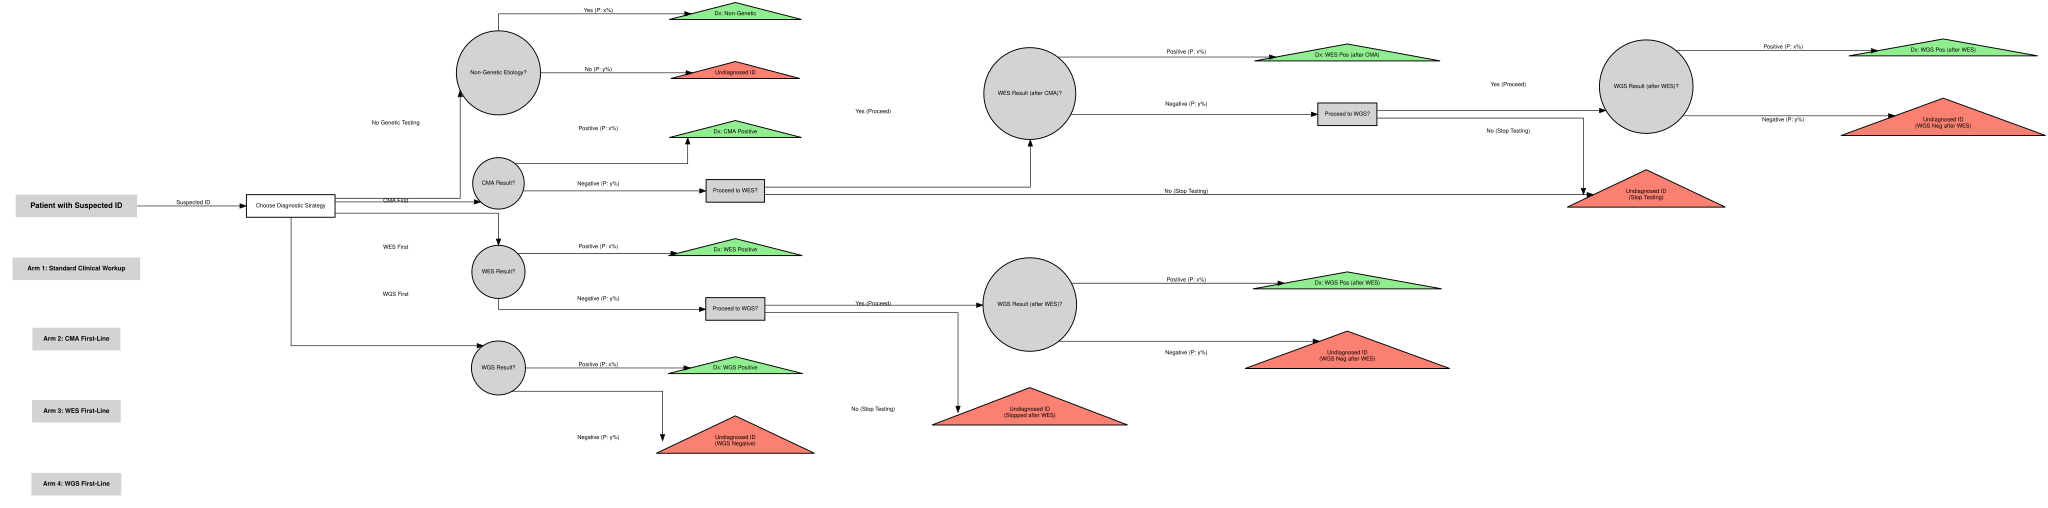

Decision tree visualization displayed interactively in Jupyter.
Remember to replace 'P: x%' and 'P: y%' with actual probabilities for your model.
Green terminal nodes imply a diagnosis, salmon implies undiagnosed.


In [2]:
from IPython.display import display  # For interactive display in Jupyter


def create_treeage_style_id_diagnostic_decision_tree():
    """
    Creates a Graphviz Digraph object representing the decision tree
    for genetic testing approaches in intellectual disability,
    following TreeAge visual conventions.
    """
    dot = Digraph(
        comment="ID Diagnostic Decision Tree",
        format="svg",
        graph_attr={
            "rankdir": "LR",
            "splines": "ortho",
            "nodesep": "0.8",
            "ranksep": "1.5",
            "fontname": "Helvetica",
            "fontsize": "10",
        },
    )

    # --- Global Node Styles (Mimicking TreeAge) ---
    # Decision Nodes (Squares)
    dot.attr(
        "node",
        shape="box",
        style="filled",
        fillcolor="white",
        fontname="Helvetica",
        fontsize="10",
        penwidth="1.5",
    )
    # Chance Nodes (Circles)
    dot.attr(
        "node",
        shape="circle",
        style="filled",
        fillcolor="white",
        fontname="Helvetica",
        fontsize="10",
        penwidth="1.5",
    )
    # Terminal Nodes (Triangles)
    dot.attr(
        "node",
        shape="triangle",
        style="filled",
        fillcolor="lightgray",
        fontname="Helvetica",
        fontsize="9",
        penwidth="1.5",
    )

    # Global Edge Style
    dot.attr("edge", fontname="Helvetica", fontsize="9", dir="forward", penwidth="1.0")

    # --- Start Node (Often implicit or simple text in TreeAge, let's make it a simple text node) ---
    dot.node(
        "Start",
        "Patient with Suspected ID",
        shape="plaintext",
        fontname="Helvetica-Bold",
        fontsize="12",
    )

    # --- Decision Point: Diagnostic Strategy (Root Decision Node) ---
    dot.node(
        "Dec_Strategy", "Choose Diagnostic Strategy", shape="box", fillcolor="white"
    )
    dot.edge("Start", "Dec_Strategy", label="Suspected ID")

    # --- Arm 1: Standard Clinical Workup / No Genetic Testing (Comparator) ---
    # Using a subgraph to group related nodes for better layout, although 'plaintext' nodes don't group visually in the same way as clusters
    with dot.subgraph(name="cluster_arm1") as c:
        # Invisible node to guide layout for the arm label
        c.attr(style="invis")  # Hide the cluster box
        c.node(
            "Arm1_Label",
            "Arm 1: Standard Clinical Workup",
            shape="plaintext",
            fontname="Helvetica-Bold",
            fontsize="10",
        )

        # Link from main decision to this arm's pathway
        dot.edge("Dec_Strategy", "Chance_NonGen", label="No Genetic Testing")

        dot.node("Chance_NonGen", "Non-Genetic Etiology?", shape="circle")
        dot.edge(
            "Arm1_Label", "Chance_NonGen", style="invis", constraint="false"
        )  # Invisible edge for conceptual grouping

        dot.node("Term_A", "Dx: Non-Genetic", shape="triangle", fillcolor="lightgreen")
        dot.edge("Chance_NonGen", "Term_A", label="Yes (P: x%)")

        dot.node("Term_B", "Undiagnosed ID", shape="triangle", fillcolor="salmon")
        dot.edge("Chance_NonGen", "Term_B", label="No (P: y%)")

    # --- Arm 2: CMA First-Line, then Sequential Testing ---
    with dot.subgraph(name="cluster_arm2") as c:
        c.attr(style="invis")
        c.node(
            "Arm2_Label",
            "Arm 2: CMA First-Line",
            shape="plaintext",
            fontname="Helvetica-Bold",
            fontsize="10",
        )

        dot.edge("Dec_Strategy", "Chance_CMA", label="CMA First")

        dot.node("Chance_CMA", "CMA Result?", shape="circle")
        dot.edge("Arm2_Label", "Chance_CMA", style="invis", constraint="false")

        dot.node("Term_C", "Dx: CMA Positive", shape="triangle", fillcolor="lightgreen")
        dot.edge("Chance_CMA", "Term_C", label="Positive (P: x%)")

        # CMA Negative Branch
        dot.node("Dec_CMA_Neg_Next", "Proceed to WES?", shape="box")
        dot.edge("Chance_CMA", "Dec_CMA_Neg_Next", label="Negative (P: y%)")

        dot.node("Chance_WES_AfterCMA", "WES Result (after CMA)?", shape="circle")
        dot.edge("Dec_CMA_Neg_Next", "Chance_WES_AfterCMA", label="Yes (Proceed)")

        dot.node(
            "Term_D",
            "Dx: WES Pos (after CMA)",
            shape="triangle",
            fillcolor="lightgreen",
        )
        dot.edge("Chance_WES_AfterCMA", "Term_D", label="Positive (P: x%)")

        # WES Negative Branch (after CMA)
        dot.node("Dec_WES_Neg_Next_AfterCMA", "Proceed to WGS?", shape="box")
        dot.edge(
            "Chance_WES_AfterCMA", "Dec_WES_Neg_Next_AfterCMA", label="Negative (P: y%)"
        )

        dot.node(
            "Chance_WGS_AfterWES_AfterCMA", "WGS Result (after WES)?", shape="circle"
        )
        dot.edge(
            "Dec_WES_Neg_Next_AfterCMA",
            "Chance_WGS_AfterWES_AfterCMA",
            label="Yes (Proceed)",
        )

        dot.node(
            "Term_E",
            "Dx: WGS Pos (after WES)",
            shape="triangle",
            fillcolor="lightgreen",
        )
        dot.edge("Chance_WGS_AfterWES_AfterCMA", "Term_E", label="Positive (P: x%)")

        dot.node(
            "Term_F",
            "Undiagnosed ID\n(WGS Neg after WES)",
            shape="triangle",
            fillcolor="salmon",
        )

        # Adding a common final node for stopping testing to reduce redundancy in Terminal Nodes
        dot.node(
            "Stop_Testing_Undiagnosed_Sequential",
            "Undiagnosed ID\n(Stop Testing)",
            shape="triangle",
            fillcolor="salmon",
        )
        dot.edge("Chance_WGS_AfterWES_AfterCMA", "Term_F", label="Negative (P: y%)")
        dot.edge(
            "Dec_WES_Neg_Next_AfterCMA",
            "Stop_Testing_Undiagnosed_Sequential",
            label="No (Stop Testing)",
        )
        dot.edge(
            "Dec_CMA_Neg_Next",
            "Stop_Testing_Undiagnosed_Sequential",
            label="No (Stop Testing)",
        )

    # --- Arm 3: Whole Exome Sequencing (WES) as First-Line ---
    with dot.subgraph(name="cluster_arm3") as c:
        c.attr(style="invis")
        c.node(
            "Arm3_Label",
            "Arm 3: WES First-Line",
            shape="plaintext",
            fontname="Helvetica-Bold",
            fontsize="10",
        )

        dot.edge("Dec_Strategy", "Chance_WES_Direct", label="WES First")

        dot.node("Chance_WES_Direct", "WES Result?", shape="circle")
        dot.edge("Arm3_Label", "Chance_WES_Direct", style="invis", constraint="false")

        dot.node("Term_H", "Dx: WES Positive", shape="triangle", fillcolor="lightgreen")
        dot.edge("Chance_WES_Direct", "Term_H", label="Positive (P: x%)")

        # WES Negative Branch
        dot.node("Dec_WES_Neg_Next_Direct", "Proceed to WGS?", shape="box")
        dot.edge(
            "Chance_WES_Direct", "Dec_WES_Neg_Next_Direct", label="Negative (P: y%)"
        )

        dot.node(
            "Chance_WGS_AfterWES_Direct", "WGS Result (after WES)?", shape="circle"
        )
        dot.edge(
            "Dec_WES_Neg_Next_Direct",
            "Chance_WGS_AfterWES_Direct",
            label="Yes (Proceed)",
        )

        dot.node(
            "Term_I",
            "Dx: WGS Pos (after WES)",
            shape="triangle",
            fillcolor="lightgreen",
        )
        dot.edge("Chance_WGS_AfterWES_Direct", "Term_I", label="Positive (P: x%)")

        dot.node(
            "Term_J",
            "Undiagnosed ID\n(WGS Neg after WES)",
            shape="triangle",
            fillcolor="salmon",
        )
        dot.edge("Chance_WGS_AfterWES_Direct", "Term_J", label="Negative (P: y%)")

        dot.node(
            "Term_K",
            "Undiagnosed ID\n(Stopped after WES)",
            shape="triangle",
            fillcolor="salmon",
        )
        dot.edge("Dec_WES_Neg_Next_Direct", "Term_K", label="No (Stop Testing)")

    # --- Arm 4: Whole Genome Sequencing (WGS) as First-Line ---
    with dot.subgraph(name="cluster_arm4") as c:
        c.attr(style="invis")
        c.node(
            "Arm4_Label",
            "Arm 4: WGS First-Line",
            shape="plaintext",
            fontname="Helvetica-Bold",
            fontsize="10",
        )

        dot.edge("Dec_Strategy", "Chance_WGS_Direct", label="WGS First")

        dot.node("Chance_WGS_Direct", "WGS Result?", shape="circle")
        dot.edge("Arm4_Label", "Chance_WGS_Direct", style="invis", constraint="false")

        dot.node("Term_L", "Dx: WGS Positive", shape="triangle", fillcolor="lightgreen")
        dot.edge("Chance_WGS_Direct", "Term_L", label="Positive (P: x%)")

        dot.node(
            "Term_M",
            "Undiagnosed ID\n(WGS Negative)",
            shape="triangle",
            fillcolor="salmon",
        )
        dot.edge("Chance_WGS_Direct", "Term_M", label="Negative (P: y%)")

    return dot


if __name__ == "__main__":
    tree = create_treeage_style_id_diagnostic_decision_tree()

    # For Jupyter Notebook interactive display
    # The `display` function from IPython.display will render the graphviz object directly.
    # It's best to use SVG format for interactive scaling in notebooks.
    display(tree)

    # Optional: Save the graph to a file if you also want a local image
    # tree.render('id_decision_tree_treeage_style', view=False)
    # print("Decision tree visualization also saved as 'id_decision_tree_treeage_style.svg' in the current directory.")
    print("Decision tree visualization displayed interactively in Jupyter.")
    print(
        "Remember to replace 'P: x%' and 'P: y%' with actual probabilities for your model."
    )
    print("Green terminal nodes imply a diagnosis, salmon implies undiagnosed.")

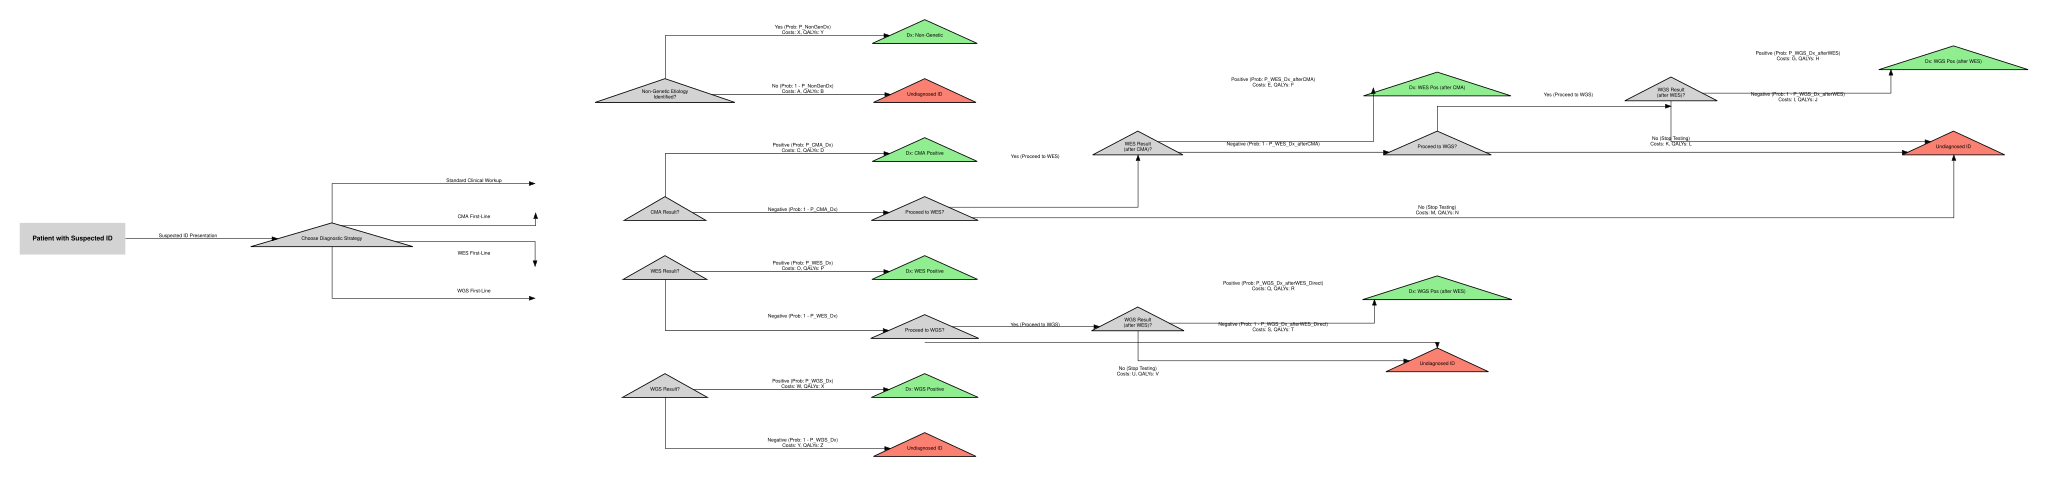

Decision tree visualization displayed interactively in Jupyter.
Please replace 'P: x%', 'Costs: X', and 'QALYs: Y' placeholders with actual probabilities, costs, and QALYs for your model.
Green terminal nodes imply a diagnosis, salmon implies undiagnosed.

Optimizations include:
- Node labels are now within the shapes.
- Edge labels (probabilities/costs/QALYs) are along the edges.
- Node sizes are adjusted for better balance and readability.
- Layout parameters (nodesep, ranksep, splines) fine-tuned.


In [3]:
from IPython.display import display  # For interactive display in Jupyter


def create_treeage_style_id_diagnostic_decision_tree_v2():
    """
    Creates a Graphviz Digraph object representing the decision tree
    for genetic testing approaches in intellectual disability,
    with optimized TreeAge visual conventions for readability.
    """
    dot = Digraph(
        comment="ID Diagnostic Decision Tree",
        format="svg",
        graph_attr={
            "rankdir": "LR",  # Left to Right layout
            "splines": "ortho",  # Orthogonal (right-angle) edges
            "nodesep": "0.7",  # Separation between nodes on the same rank
            "ranksep": "1.5",  # Separation between ranks (levels)
            "fontname": "Helvetica",  # Global font
            "fontsize": "10",
            "pad": "0.5",  # Padding around the graph
        },
    )

    # --- Global Node Styles (Mimicking TreeAge) ---
    # Decision Nodes (Squares)
    dot.attr(
        "node",
        shape="box",
        style="filled",
        fillcolor="white",
        fontname="Helvetica",
        fontsize="10",
        penwidth="1.5",
        fixedsize="false",
        width="1.5",
        height="0.8",
    )
    # Chance Nodes (Circles)
    dot.attr(
        "node",
        shape="circle",
        style="filled",
        fillcolor="white",
        fontname="Helvetica",
        fontsize="10",
        penwidth="1.5",
        fixedsize="false",
        width="1.0",
        height="1.0",
    )
    # Terminal Nodes (Triangles)
    dot.attr(
        "node",
        shape="triangle",
        style="filled",
        fillcolor="lightgray",
        fontname="Helvetica",
        fontsize="9",
        penwidth="1.5",
        fixedsize="false",
        width="0.8",
        height="0.8",
    )

    # Global Edge Style
    dot.attr(
        "edge",
        fontname="Helvetica",
        fontsize="9",
        dir="forward",
        penwidth="1.0",
        labeldistance="1.5",
        labelangle="30",
    )
    # labeldistance: How far label is from edge. labelangle: Angle of label relative to edge.

    # --- Start Node (Often just an entry point, no specific shape in TreeAge model display) ---
    dot.node(
        "Start",
        "Patient with Suspected ID",
        shape="plaintext",
        fontname="Helvetica-Bold",
        fontsize="12",
    )

    # --- Decision Point: Diagnostic Strategy (Root Decision Node) ---
    dot.node(
        "Dec_Strategy", "Choose Diagnostic Strategy"
    )  # Shape is 'box' by default attribute
    dot.edge("Start", "Dec_Strategy", label="Suspected ID Presentation")

    # --- Arm 1: Standard Clinical Workup / No Genetic Testing (Comparator) ---
    # We use a subgraph with an invisible node/edge to conceptually link the arm label
    with dot.subgraph(name="cluster_arm1") as c:
        c.attr(style="invis")  # Hide the cluster boundary
        # A small, invisible node to act as a anchor for the arm label
        c.node(
            "arm1_start_anchor",
            "",
            shape="point",
            width="0.01",
            height="0.01",
            style="invis",
        )
        dot.edge("Dec_Strategy", "arm1_start_anchor", label="Standard Clinical Workup")
        dot.edge(
            "arm1_start_anchor", "Chance_NonGen", style="invis", constraint="true"
        )  # Connect anchor to first real node

        dot.node(
            "Chance_NonGen", "Non-Genetic Etiology\nIdentified?"
        )  # Text inside circle
        dot.node(
            "Term_A", "Dx: Non-Genetic", fillcolor="lightgreen"
        )  # Text inside triangle
        dot.node("Term_B", "Undiagnosed ID", fillcolor="salmon")  # Text inside triangle

        dot.edge(
            "Chance_NonGen",
            "Term_A",
            label="Yes (Prob: P_NonGenDx)\nCosts: X, QALYs: Y",
        )  # Label on edge
        dot.edge(
            "Chance_NonGen",
            "Term_B",
            label="No (Prob: 1 - P_NonGenDx)\nCosts: A, QALYs: B",
        )  # Label on edge

    # --- Arm 2: CMA First-Line, then Sequential Testing ---
    with dot.subgraph(name="cluster_arm2") as c:
        c.attr(style="invis")
        c.node(
            "arm2_start_anchor",
            "",
            shape="point",
            width="0.01",
            height="0.01",
            style="invis",
        )
        dot.edge("Dec_Strategy", "arm2_start_anchor", label="CMA First-Line")
        dot.edge("arm2_start_anchor", "Chance_CMA", style="invis", constraint="true")

        dot.node("Chance_CMA", "CMA Result?")
        dot.node("Term_C", "Dx: CMA Positive", fillcolor="lightgreen")
        dot.edge(
            "Chance_CMA",
            "Term_C",
            label="Positive (Prob: P_CMA_Dx)\nCosts: C, QALYs: D",
        )

        # CMA Negative Branch
        dot.node("Dec_CMA_Neg_Next", "Proceed to WES?")
        dot.edge(
            "Chance_CMA", "Dec_CMA_Neg_Next", label="Negative (Prob: 1 - P_CMA_Dx)"
        )

        dot.node("Chance_WES_AfterCMA", "WES Result\n(after CMA)?")
        dot.edge(
            "Dec_CMA_Neg_Next", "Chance_WES_AfterCMA", label="Yes (Proceed to WES)"
        )

        dot.node("Term_D", "Dx: WES Pos (after CMA)", fillcolor="lightgreen")
        dot.edge(
            "Chance_WES_AfterCMA",
            "Term_D",
            label="Positive (Prob: P_WES_Dx_afterCMA)\nCosts: E, QALYs: F",
        )

        # WES Negative Branch (after CMA)
        dot.node("Dec_WES_Neg_Next_AfterCMA", "Proceed to WGS?")
        dot.edge(
            "Chance_WES_AfterCMA",
            "Dec_WES_Neg_Next_AfterCMA",
            label="Negative (Prob: 1 - P_WES_Dx_afterCMA)",
        )

        dot.node("Chance_WGS_AfterWES_AfterCMA", "WGS Result\n(after WES)?")
        dot.edge(
            "Dec_WES_Neg_Next_AfterCMA",
            "Chance_WGS_AfterWES_AfterCMA",
            label="Yes (Proceed to WGS)",
        )

        dot.node("Term_E", "Dx: WGS Pos (after WES)", fillcolor="lightgreen")
        dot.edge(
            "Chance_WGS_AfterWES_AfterCMA",
            "Term_E",
            label="Positive (Prob: P_WGS_Dx_afterWES)\nCosts: G, QALYs: H",
        )

        # Undiagnosed path common node for termination
        dot.node("Undiag_Seq_Stop", "Undiagnosed ID", fillcolor="salmon")
        dot.edge(
            "Chance_WGS_AfterWES_AfterCMA",
            "Undiag_Seq_Stop",
            label="Negative (Prob: 1 - P_WGS_Dx_afterWES)\nCosts: I, QALYs: J",
        )
        dot.edge(
            "Dec_WES_Neg_Next_AfterCMA",
            "Undiag_Seq_Stop",
            label="No (Stop Testing)\nCosts: K, QALYs: L",
        )
        dot.edge(
            "Dec_CMA_Neg_Next",
            "Undiag_Seq_Stop",
            label="No (Stop Testing)\nCosts: M, QALYs: N",
        )

    # --- Arm 3: Whole Exome Sequencing (WES) as First-Line ---
    with dot.subgraph(name="cluster_arm3") as c:
        c.attr(style="invis")
        c.node(
            "arm3_start_anchor",
            "",
            shape="point",
            width="0.01",
            height="0.01",
            style="invis",
        )
        dot.edge("Dec_Strategy", "arm3_start_anchor", label="WES First-Line")
        dot.edge(
            "arm3_start_anchor", "Chance_WES_Direct", style="invis", constraint="true"
        )

        dot.node("Chance_WES_Direct", "WES Result?")
        dot.node("Term_H", "Dx: WES Positive", fillcolor="lightgreen")
        dot.edge(
            "Chance_WES_Direct",
            "Term_H",
            label="Positive (Prob: P_WES_Dx)\nCosts: O, QALYs: P",
        )

        # WES Negative Branch
        dot.node("Dec_WES_Neg_Next_Direct", "Proceed to WGS?")
        dot.edge(
            "Chance_WES_Direct",
            "Dec_WES_Neg_Next_Direct",
            label="Negative (Prob: 1 - P_WES_Dx)",
        )

        dot.node("Chance_WGS_AfterWES_Direct", "WGS Result\n(after WES)?")
        dot.edge(
            "Dec_WES_Neg_Next_Direct",
            "Chance_WGS_AfterWES_Direct",
            label="Yes (Proceed to WGS)",
        )

        dot.node("Term_I", "Dx: WGS Pos (after WES)", fillcolor="lightgreen")
        dot.edge(
            "Chance_WGS_AfterWES_Direct",
            "Term_I",
            label="Positive (Prob: P_WGS_Dx_afterWES_Direct)\nCosts: Q, QALYs: R",
        )

        # Undiagnosed path common node for termination
        dot.node("Undiag_WES_Stop", "Undiagnosed ID", fillcolor="salmon")
        dot.edge(
            "Chance_WGS_AfterWES_Direct",
            "Undiag_WES_Stop",
            label="Negative (Prob: 1 - P_WGS_Dx_afterWES_Direct)\nCosts: S, QALYs: T",
        )
        dot.edge(
            "Dec_WES_Neg_Next_Direct",
            "Undiag_WES_Stop",
            label="No (Stop Testing)\nCosts: U, QALYs: V",
        )

    # --- Arm 4: Whole Genome Sequencing (WGS) as First-Line ---
    with dot.subgraph(name="cluster_arm4") as c:
        c.attr(style="invis")
        c.node(
            "arm4_start_anchor",
            "",
            shape="point",
            width="0.01",
            height="0.01",
            style="invis",
        )
        dot.edge("Dec_Strategy", "arm4_start_anchor", label="WGS First-Line")
        dot.edge(
            "arm4_start_anchor", "Chance_WGS_Direct", style="invis", constraint="true"
        )

        dot.node("Chance_WGS_Direct", "WGS Result?")
        dot.node("Term_L", "Dx: WGS Positive", fillcolor="lightgreen")
        dot.edge(
            "Chance_WGS_Direct",
            "Term_L",
            label="Positive (Prob: P_WGS_Dx)\nCosts: W, QALYs: X",
        )

        dot.node("Term_M", "Undiagnosed ID", fillcolor="salmon")
        dot.edge(
            "Chance_WGS_Direct",
            "Term_M",
            label="Negative (Prob: 1 - P_WGS_Dx)\nCosts: Y, QALYs: Z",
        )

    return dot


if __name__ == "__main__":
    tree = create_treeage_style_id_diagnostic_decision_tree_v2()

    # For Jupyter Notebook interactive display
    display(tree)

    print("Decision tree visualization displayed interactively in Jupyter.")
    print(
        "Please replace 'P: x%', 'Costs: X', and 'QALYs: Y' placeholders with actual probabilities, costs, and QALYs for your model."
    )
    print("Green terminal nodes imply a diagnosis, salmon implies undiagnosed.")
    print("\nOptimizations include:")
    print("- Node labels are now within the shapes.")
    print("- Edge labels (probabilities/costs/QALYs) are along the edges.")
    print("- Node sizes are adjusted for better balance and readability.")
    print("- Layout parameters (nodesep, ranksep, splines) fine-tuned.")

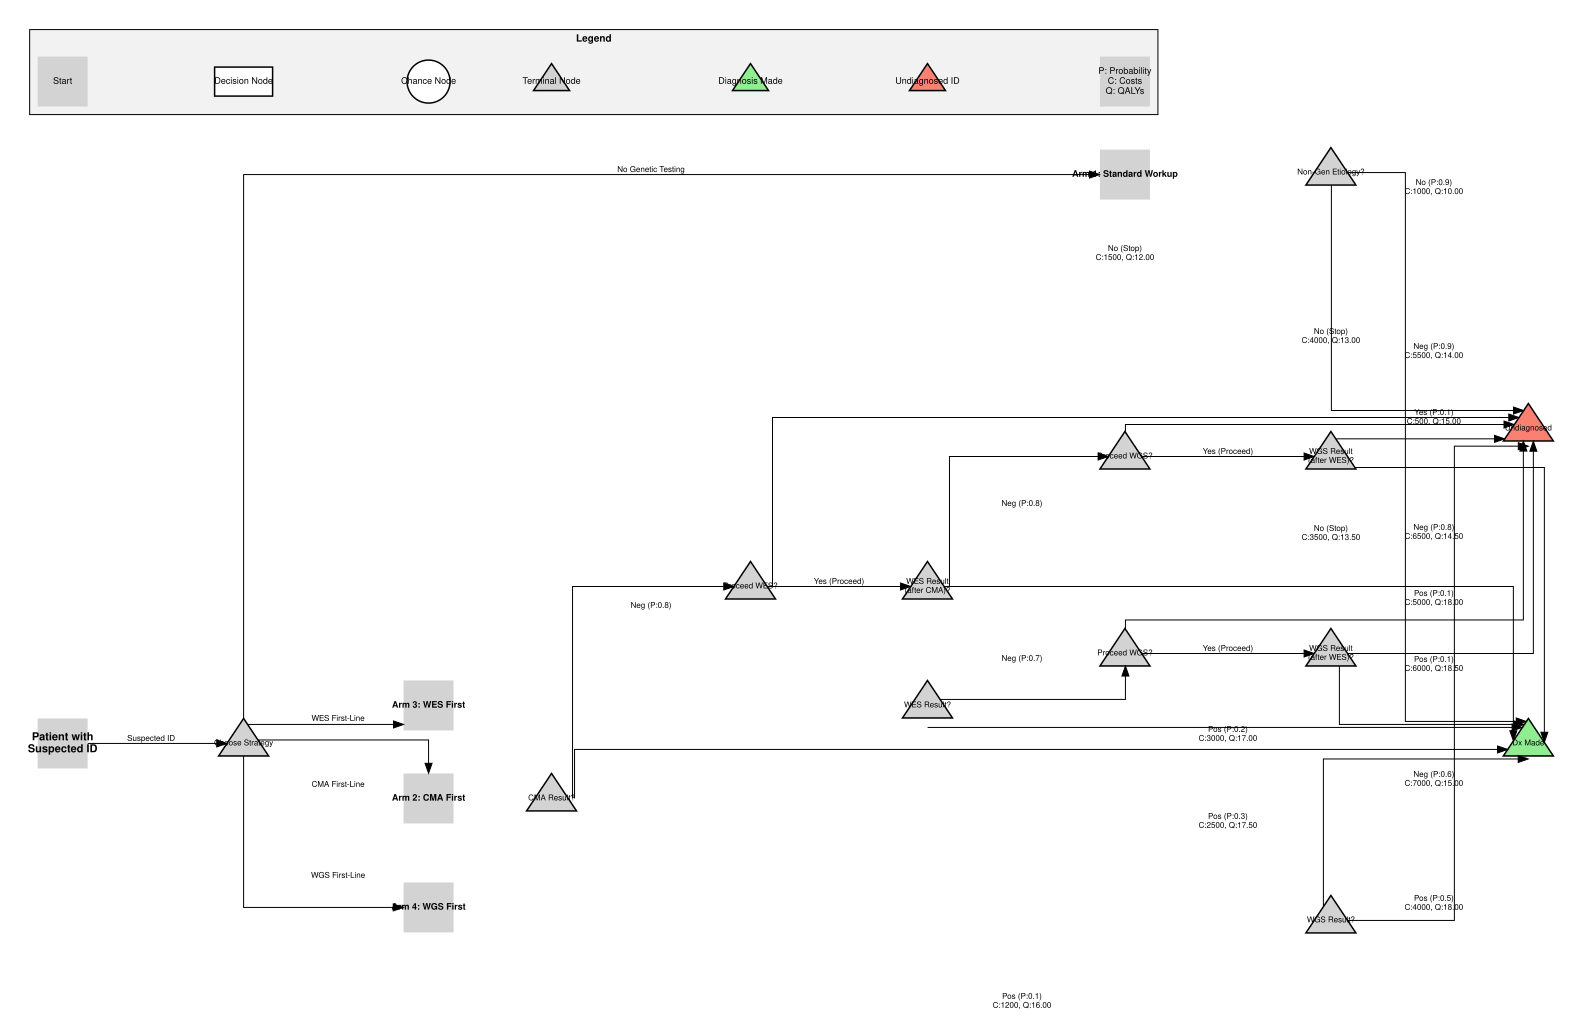

Decision tree visualization displayed interactively in Jupyter.
Please replace 'P:%.1f', 'C:%.0f', and 'Q:%.2f' with actual probabilities, costs, and QALYs for your model.
Note: Values are formatted with placeholders (e.g., '%.1f') for numerical data.

Optimizations for compactness and readability include:
- Reduced node/rank separation and overall padding.
- Fixed node sizes (minimized while fitting text).
- Consolidated common terminal nodes ('Dx Made', 'Undiagnosed').
- More concise node labels (e.g., 'WES Result' instead of 'WES Result (after CMA)?').
- Explicit numerical placeholders for probabilities, costs, and QALYs on edges.
- Added a clear legend at the bottom right.


In [4]:
from IPython.display import display


def create_treeage_style_id_diagnostic_decision_tree_v3():
    """
    Creates a Graphviz Digraph object representing the decision tree
    for genetic testing approaches in intellectual disability,
    with heavily optimized TreeAge visual conventions for readability and compactness.
    Includes a legend.
    """
    dot = Digraph(
        comment="ID Diagnostic Decision Tree",
        format="svg",
        graph_attr={
            "rankdir": "LR",  # Left to Right layout
            "splines": "ortho",  # Orthogonal (right-angle) edges
            "nodesep": "0.6",  # Reduced separation between nodes on the same rank
            "ranksep": "1.0",  # Reduced separation between ranks (levels)
            "fontname": "Helvetica",  # Global font
            "fontsize": "9",  # Slightly smaller global font
            "pad": "0.3",  # Reduced padding
            "overlap": "false",  # Prevent node overlap
            "concentrate": "true",  # Try to merge parallel edges
        },
    )

    # --- Global Node Styles (Mimicking TreeAge) ---
    # Decision Nodes (Squares)
    dot.attr(
        "node",
        shape="box",
        style="filled",
        fillcolor="white",
        fontname="Helvetica",
        fontsize="9",
        penwidth="1.5",
        fixedsize="true",
        width="1.2",
        height="0.6",
    )
    # Chance Nodes (Circles)
    dot.attr(
        "node",
        shape="circle",
        style="filled",
        fillcolor="white",
        fontname="Helvetica",
        fontsize="9",
        penwidth="1.5",
        fixedsize="true",
        width="0.8",
        height="0.8",
    )
    # Terminal Nodes (Triangles) - make them smaller, text inside might be harder but value labels are on edges.
    dot.attr(
        "node",
        shape="triangle",
        style="filled",
        fillcolor="lightgray",
        fontname="Helvetica",
        fontsize="8",
        penwidth="1.5",
        fixedsize="true",
        width="0.7",
        height="0.7",
    )

    # Global Edge Style
    dot.attr(
        "edge",
        fontname="Helvetica",
        fontsize="8",
        dir="forward",
        penwidth="1.0",
        labeldistance="1.2",
        labelangle="30",
    )
    # labeldistance: How far label is from edge. labelangle: Angle of label relative to edge.

    # --- Start Node ---
    dot.node(
        "Start",
        "Patient with\nSuspected ID",
        shape="plaintext",
        fontname="Helvetica-Bold",
        fontsize="11",
    )

    # --- Decision Point: Diagnostic Strategy (Root Decision Node) ---
    dot.node("Dec_Strategy", "Choose Strategy")
    dot.edge("Start", "Dec_Strategy", label="Suspected ID")

    # --- Common Terminal Nodes ---
    # Centralizing these to reduce redundant shapes and make the graph cleaner
    dot.node(
        "TERM_DIAGNOSED",
        "Dx Made",
        shape="triangle",
        fillcolor="lightgreen",
        width="0.7",
        height="0.7",
    )
    dot.node(
        "TERM_UNDIAGNOSED",
        "Undiagnosed",
        shape="triangle",
        fillcolor="salmon",
        width="0.7",
        height="0.7",
    )

    # --- Arm 1: Standard Clinical Workup / No Genetic Testing (Comparator) ---
    with dot.subgraph(name="cluster_arm1") as c:
        c.attr(style="invis")  # Hide cluster boundary
        c.node(
            "arm1_label",
            "Arm 1: Standard Workup",
            shape="plaintext",
            fontname="Helvetica-Bold",
            fontsize="9",
        )  # Arm label
        dot.edge(
            "Dec_Strategy", "arm1_label", label="No Genetic Testing", minlen="1"
        )  # Link to arm label

        dot.node("Chance_NonGen", "Non-Gen Etiology?")
        dot.edge(
            "arm1_label", "Chance_NonGen", style="invis", constraint="true", minlen="1"
        )  # Invisible link for layout

        dot.edge(
            "Chance_NonGen",
            "TERM_DIAGNOSED",
            label=f"Yes (P:{0.05:.1f})\nC:{500:.0f}, Q:{15.0:.2f}",
        )  # Example values
        dot.edge(
            "Chance_NonGen",
            "TERM_UNDIAGNOSED",
            label=f"No (P:{0.95:.1f})\nC:{1000:.0f}, Q:{10.0:.2f}",
        )

    # --- Arm 2: CMA First-Line, then Sequential Testing ---
    with dot.subgraph(name="cluster_arm2") as c:
        c.attr(style="invis")
        c.node(
            "arm2_label",
            "Arm 2: CMA First",
            shape="plaintext",
            fontname="Helvetica-Bold",
            fontsize="9",
        )
        dot.edge("Dec_Strategy", "arm2_label", label="CMA First-Line", minlen="1")

        dot.node("Chance_CMA", "CMA Result?")
        dot.edge(
            "arm2_label", "Chance_CMA", style="invis", constraint="true", minlen="1"
        )

        dot.edge(
            "Chance_CMA",
            "TERM_DIAGNOSED",
            label=f"Pos (P:{0.15:.1f})\nC:{1200:.0f}, Q:{16.0:.2f}",
        )  # Example values

        dot.node("Dec_CMA_Neg_Next", "Proceed WES?")
        dot.edge("Chance_CMA", "Dec_CMA_Neg_Next", label=f"Neg (P:{0.85:.1f})")

        dot.node("Chance_WES_AfterCMA", "WES Result\n(after CMA)?")
        dot.edge("Dec_CMA_Neg_Next", "Chance_WES_AfterCMA", label="Yes (Proceed)")
        dot.edge(
            "Dec_CMA_Neg_Next",
            "TERM_UNDIAGNOSED",
            label=f"No (Stop)\nC:{1500:.0f}, Q:{12.0:.2f}",
        )  # Stop testing here

        dot.edge(
            "Chance_WES_AfterCMA",
            "TERM_DIAGNOSED",
            label=f"Pos (P:{0.25:.1f})\nC:{3000:.0f}, Q:{17.0:.2f}",
        )

        dot.node("Dec_WES_Neg_Next_AfterCMA", "Proceed WGS?")
        dot.edge(
            "Chance_WES_AfterCMA",
            "Dec_WES_Neg_Next_AfterCMA",
            label=f"Neg (P:{0.75:.1f})",
        )

        dot.node("Chance_WGS_AfterWES_AfterCMA", "WGS Result\n(after WES)?")
        dot.edge(
            "Dec_WES_Neg_Next_AfterCMA",
            "Chance_WGS_AfterWES_AfterCMA",
            label="Yes (Proceed)",
        )
        dot.edge(
            "Dec_WES_Neg_Next_AfterCMA",
            "TERM_UNDIAGNOSED",
            label=f"No (Stop)\nC:{4000:.0f}, Q:{13.0:.2f}",
        )  # Stop testing here

        dot.edge(
            "Chance_WGS_AfterWES_AfterCMA",
            "TERM_DIAGNOSED",
            label=f"Pos (P:{0.10:.1f})\nC:{5000:.0f}, Q:{18.0:.2f}",
        )
        dot.edge(
            "Chance_WGS_AfterWES_AfterCMA",
            "TERM_UNDIAGNOSED",
            label=f"Neg (P:{0.90:.1f})\nC:{5500:.0f}, Q:{14.0:.2f}",
        )

    # --- Arm 3: Whole Exome Sequencing (WES) as First-Line ---
    with dot.subgraph(name="cluster_arm3") as c:
        c.attr(style="invis")
        c.node(
            "arm3_label",
            "Arm 3: WES First",
            shape="plaintext",
            fontname="Helvetica-Bold",
            fontsize="9",
        )
        dot.edge("Dec_Strategy", "arm3_label", label="WES First-Line", minlen="1")

        dot.node("Chance_WES_Direct", "WES Result?")
        dot.edge(
            "arm3_label",
            "Chance_WES_Direct",
            style="invis",
            constraint="true",
            minlen="1",
        )

        dot.edge(
            "Chance_WES_Direct",
            "TERM_DIAGNOSED",
            label=f"Pos (P:{0.35:.1f})\nC:{2500:.0f}, Q:{17.5:.2f}",
        )

        dot.node("Dec_WES_Neg_Next_Direct", "Proceed WGS?")
        dot.edge(
            "Chance_WES_Direct",
            "Dec_WES_Neg_Next_Direct",
            label=f"Neg (P:{0.65:.1f})",
        )

        dot.node("Chance_WGS_AfterWES_Direct", "WGS Result\n(after WES)?")
        dot.edge(
            "Dec_WES_Neg_Next_Direct",
            "Chance_WGS_AfterWES_Direct",
            label="Yes (Proceed)",
        )
        dot.edge(
            "Dec_WES_Neg_Next_Direct",
            "TERM_UNDIAGNOSED",
            label=f"No (Stop)\nC:{3500:.0f}, Q:{13.5:.2f}",
        )  # Stop testing here

        dot.edge(
            "Chance_WGS_AfterWES_Direct",
            "TERM_DIAGNOSED",
            label=f"Pos (P:{0.15:.1f})\nC:{6000:.0f}, Q:{18.5:.2f}",
        )
        dot.edge(
            "Chance_WGS_AfterWES_Direct",
            "TERM_UNDIAGNOSED",
            label=f"Neg (P:{0.85:.1f})\nC:{6500:.0f}, Q:{14.5:.2f}",
        )

    # --- Arm 4: Whole Genome Sequencing (WGS) as First-Line ---
    with dot.subgraph(name="cluster_arm4") as c:
        c.attr(style="invis")
        c.node(
            "arm4_label",
            "Arm 4: WGS First",
            shape="plaintext",
            fontname="Helvetica-Bold",
            fontsize="9",
        )
        dot.edge("Dec_Strategy", "arm4_label", label="WGS First-Line", minlen="1")

        dot.node("Chance_WGS_Direct", "WGS Result?")
        dot.edge(
            "arm4_label",
            "Chance_WGS_Direct",
            style="invis",
            constraint="true",
            minlen="1",
        )

        dot.edge(
            "Chance_WGS_Direct",
            "TERM_DIAGNOSED",
            label=f"Pos (P:{0.45:.1f})\nC:{4000:.0f}, Q:{18.0:.2f}",
        )
        dot.edge(
            "Chance_WGS_Direct",
            "TERM_UNDIAGNOSED",
            label=f"Neg (P:{0.55:.1f})\nC:{7000:.0f}, Q:{15.0:.2f}",
        )

    # --- LEGEND ---
    # Create a separate subgraph for the legend to place it clearly
    with dot.subgraph(name="cluster_legend") as l:
        l.attr(
            rank="sink",
            style="filled",
            fillcolor="grey95",
            label="Legend",
            fontname="Helvetica-Bold",
            fontsize="10",
            penwidth="1.0",
        )
        l.attr(rankdir="TB")  # Top to Bottom for legend items

        # Nodes for legend items
        l.node(
            "L_Start", "Start", shape="plaintext", fontname="Helvetica", fontsize="9"
        )
        l.node(
            "L_Decision",
            "Decision Node",
            shape="box",
            style="filled",
            fillcolor="white",
            fontname="Helvetica",
            fontsize="9",
            penwidth="1.5",
            fixedsize="true",
            width="0.8",
            height="0.4",
        )
        l.node(
            "L_Chance",
            "Chance Node",
            shape="circle",
            style="filled",
            fillcolor="white",
            fontname="Helvetica",
            fontsize="9",
            penwidth="1.5",
            fixedsize="true",
            width="0.6",
            height="0.6",
        )
        l.node(
            "L_Terminal",
            "Terminal Node",
            shape="triangle",
            style="filled",
            fillcolor="lightgray",
            fontname="Helvetica",
            fontsize="9",
            penwidth="1.5",
            fixedsize="true",
            width="0.5",
            height="0.5",
        )
        l.node(
            "L_Terminal_Dx",
            "Diagnosis Made",
            shape="triangle",
            style="filled",
            fillcolor="lightgreen",
            fontname="Helvetica",
            fontsize="9",
            penwidth="1.5",
            fixedsize="true",
            width="0.5",
            height="0.5",
        )
        l.node(
            "L_Terminal_Undx",
            "Undiagnosed ID",
            shape="triangle",
            style="filled",
            fillcolor="salmon",
            fontname="Helvetica",
            fontsize="9",
            penwidth="1.5",
            fixedsize="true",
            width="0.5",
            height="0.5",
        )
        l.node(
            "L_EdgeLabel",
            "P: Probability\nC: Costs\nQ: QALYs",
            shape="plaintext",
            fontname="Helvetica",
            fontsize="9",
        )

        # Connect legend nodes to enforce order (invisible edges)
        l.edge("L_Start", "L_Decision", style="invis")
        l.edge("L_Decision", "L_Chance", style="invis")
        l.edge("L_Chance", "L_Terminal", style="invis")
        l.edge("L_Terminal", "L_Terminal_Dx", style="invis")
        l.edge("L_Terminal_Dx", "L_Terminal_Undx", style="invis")
        l.edge("L_Terminal_Undx", "L_EdgeLabel", style="invis")

    return dot


if __name__ == "__main__":
    tree = create_treeage_style_id_diagnostic_decision_tree_v3()

    # For Jupyter Notebook interactive display
    display(tree)

    print("Decision tree visualization displayed interactively in Jupyter.")
    print(
        "Please replace 'P:%.1f', 'C:%.0f', and 'Q:%.2f' with actual probabilities, costs, and QALYs for your model."
    )
    print(
        "Note: Values are formatted with placeholders (e.g., '%.1f') for numerical data."
    )
    print("\nOptimizations for compactness and readability include:")
    print("- Reduced node/rank separation and overall padding.")
    print("- Fixed node sizes (minimized while fitting text).")
    print("- Consolidated common terminal nodes ('Dx Made', 'Undiagnosed').")
    print(
        "- More concise node labels (e.g., 'WES Result' instead of 'WES Result (after CMA)?')."
    )
    print(
        "- Explicit numerical placeholders for probabilities, costs, and QALYs on edges."
    )
    print("- Added a clear legend at the bottom right.")

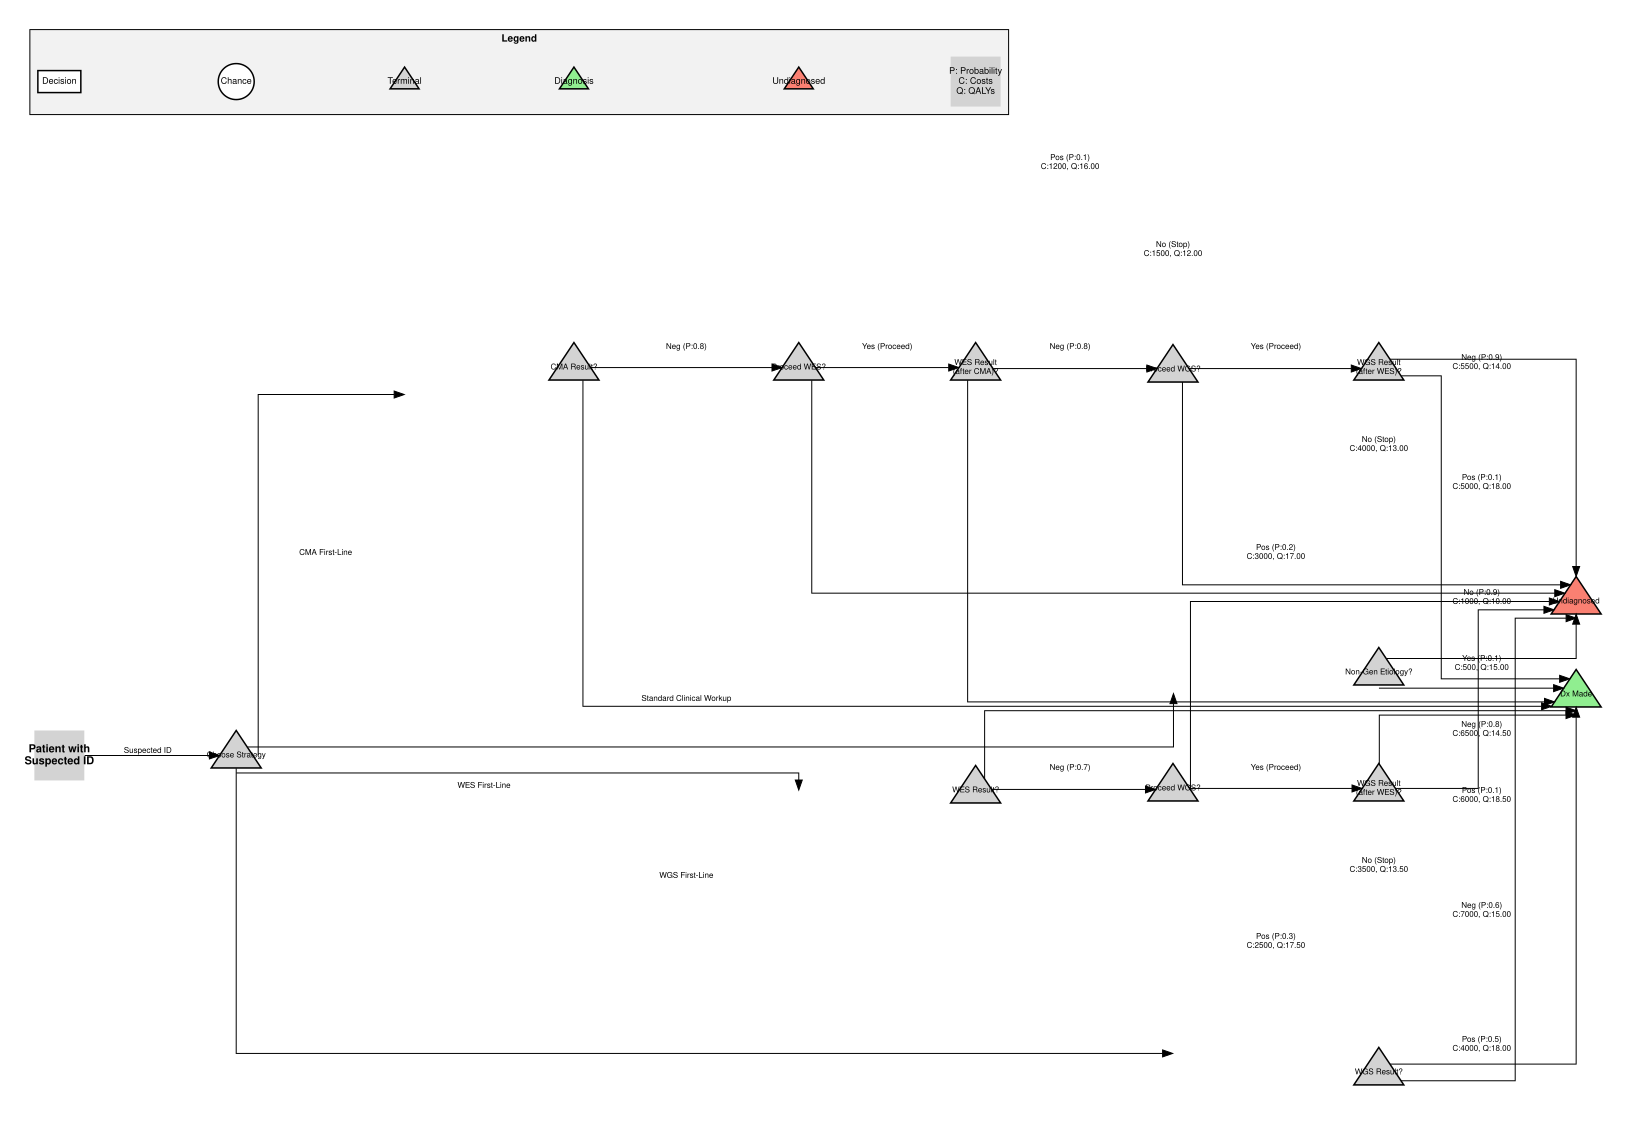

Decision tree visualization displayed interactively in Jupyter.
Please replace 'P:%.1f', 'C:%.0f', and 'Q:%.2f' with actual probabilities, costs, and QALYs for your model.

Optimizations for better arm separation, compactness, and readability:
- Each main 'arm' is now a distinct subgraph with its own internal layout logic.
- 'rank=same' is used strategically within arm subgraphs to help align nodes.
- Node sizes and text labels are further condensed.
- Legend is more compact.
This approach provides better control over how the main branches are laid out horizontally.


In [5]:
from IPython.display import display


def create_treeage_style_id_diagnostic_decision_tree_v4():
    """
    Creates a Graphviz Digraph object representing the decision tree
    for genetic testing approaches in intellectual disability,
    with optimized TreeAge visual conventions for readability and compactness.
    Focuses on better separation of main arms.
    Includes a legend.
    """
    dot = Digraph(
        comment="ID Diagnostic Decision Tree",
        format="svg",
        graph_attr={
            "rankdir": "LR",  # Left to Right layout
            "splines": "ortho",  # Orthogonal (right-angle) edges
            "nodesep": "0.6",  # Separation between nodes on the same rank
            "ranksep": "1.0",  # Separation between ranks (levels)
            "fontname": "Helvetica",  # Global font
            "fontsize": "9",
            "pad": "0.3",
            "overlap": "false",
            "concentrate": "true",
        },
    )

    # --- Global Node Styles ---
    dot.attr(
        "node",
        shape="box",
        style="filled",
        fillcolor="white",
        fontname="Helvetica",
        fontsize="9",
        penwidth="1.5",
        fixedsize="true",
        width="1.2",
        height="0.6",
    )
    dot.attr(
        "node",
        shape="circle",
        style="filled",
        fillcolor="white",
        fontname="Helvetica",
        fontsize="9",
        penwidth="1.5",
        fixedsize="true",
        width="0.8",
        height="0.8",
    )
    dot.attr(
        "node",
        shape="triangle",
        style="filled",
        fillcolor="lightgray",
        fontname="Helvetica",
        fontsize="8",
        penwidth="1.5",
        fixedsize="true",
        width="0.7",
        height="0.7",
    )

    # Global Edge Style
    dot.attr(
        "edge",
        fontname="Helvetica",
        fontsize="8",
        dir="forward",
        penwidth="1.0",
        labeldistance="1.2",
        labelangle="30",
    )

    # --- Start Node ---
    dot.node(
        "Start",
        "Patient with\nSuspected ID",
        shape="plaintext",
        fontname="Helvetica-Bold",
        fontsize="11",
    )

    # --- Decision Point: Diagnostic Strategy (Root Decision Node) ---
    dot.node("Dec_Strategy", "Choose Strategy")
    dot.edge("Start", "Dec_Strategy", label="Suspected ID")

    # --- Common Terminal Nodes ---
    dot.node(
        "TERM_DIAGNOSED",
        "Dx Made",
        shape="triangle",
        fillcolor="lightgreen",
        width="0.7",
        height="0.7",
    )
    dot.node(
        "TERM_UNDIAGNOSED",
        "Undiagnosed",
        shape="triangle",
        fillcolor="salmon",
        width="0.7",
        height="0.7",
    )

    # --- Define each main ARM as a distinct subgraph ---
    # The 'rank=same' attribute within a subgraph hints to Graphviz to keep nodes on the same rank.
    # We will connect the main decision node to the start of each arm using invisible edges for layout.

    # Arm 1: Standard Clinical Workup
    with dot.subgraph(name="cluster_arm1_path") as a1:
        a1.attr(
            rank="same", style="invis"
        )  # Ensure nodes within this subgraph try to stay on the same rank
        a1.node(
            "arm1_start", "", shape="point", width="0.01", height="0.01", style="invis"
        )  # Invisible start anchor
        dot.edge("Dec_Strategy", "arm1_start", label="Standard Clinical Workup")
        a1.node("A1_Chance_NonGen", "Non-Gen Etiology?")
        a1.edge("arm1_start", "A1_Chance_NonGen", style="invis", constraint="true")

        a1.edge(
            "A1_Chance_NonGen",
            "TERM_DIAGNOSED",
            label=f"Yes (P:{0.05:.1f})\nC:{500:.0f}, Q:{15.0:.2f}",
        )
        a1.edge(
            "A1_Chance_NonGen",
            "TERM_UNDIAGNOSED",
            label=f"No (P:{0.95:.1f})\nC:{1000:.0f}, Q:{10.0:.2f}",
        )

    # Arm 2: CMA First-Line, Sequential
    with dot.subgraph(name="cluster_arm2_path") as a2:
        a2.attr(rank="same", style="invis")
        a2.node(
            "arm2_start", "", shape="point", width="0.01", height="0.01", style="invis"
        )
        dot.edge("Dec_Strategy", "arm2_start", label="CMA First-Line")
        a2.node("A2_Chance_CMA", "CMA Result?")
        a2.edge("arm2_start", "A2_Chance_CMA", style="invis", constraint="true")

        a2.edge(
            "A2_Chance_CMA",
            "TERM_DIAGNOSED",
            label=f"Pos (P:{0.15:.1f})\nC:{1200:.0f}, Q:{16.0:.2f}",
        )

        a2.node("A2_Dec_CMA_Neg_Next", "Proceed WES?")
        a2.edge("A2_Chance_CMA", "A2_Dec_CMA_Neg_Next", label=f"Neg (P:{0.85:.1f})")

        a2.node("A2_Chance_WES_AfterCMA", "WES Result\n(after CMA)?")
        a2.edge("A2_Dec_CMA_Neg_Next", "A2_Chance_WES_AfterCMA", label="Yes (Proceed)")
        a2.edge(
            "A2_Dec_CMA_Neg_Next",
            "TERM_UNDIAGNOSED",
            label=f"No (Stop)\nC:{1500:.0f}, Q:{12.0:.2f}",
        )

        a2.edge(
            "A2_Chance_WES_AfterCMA",
            "TERM_DIAGNOSED",
            label=f"Pos (P:{0.25:.1f})\nC:{3000:.0f}, Q:{17.0:.2f}",
        )

        a2.node("A2_Dec_WES_Neg_Next_AfterCMA", "Proceed WGS?")
        a2.edge(
            "A2_Chance_WES_AfterCMA",
            "A2_Dec_WES_Neg_Next_AfterCMA",
            label=f"Neg (P:{0.75:.1f})",
        )

        a2.node("A2_Chance_WGS_AfterWES_AfterCMA", "WGS Result\n(after WES)?")
        a2.edge(
            "A2_Dec_WES_Neg_Next_AfterCMA",
            "A2_Chance_WGS_AfterWES_AfterCMA",
            label="Yes (Proceed)",
        )
        a2.edge(
            "A2_Dec_WES_Neg_Next_AfterCMA",
            "TERM_UNDIAGNOSED",
            label=f"No (Stop)\nC:{4000:.0f}, Q:{13.0:.2f}",
        )

        a2.edge(
            "A2_Chance_WGS_AfterWES_AfterCMA",
            "TERM_DIAGNOSED",
            label=f"Pos (P:{0.10:.1f})\nC:{5000:.0f}, Q:{18.0:.2f}",
        )
        a2.edge(
            "A2_Chance_WGS_AfterWES_AfterCMA",
            "TERM_UNDIAGNOSED",
            label=f"Neg (P:{0.90:.1f})\nC:{5500:.0f}, Q:{14.0:.2f}",
        )

    # Arm 3: WES First-Line
    with dot.subgraph(name="cluster_arm3_path") as a3:
        a3.attr(rank="same", style="invis")
        a3.node(
            "arm3_start", "", shape="point", width="0.01", height="0.01", style="invis"
        )
        dot.edge("Dec_Strategy", "arm3_start", label="WES First-Line")
        a3.node("A3_Chance_WES_Direct", "WES Result?")
        a3.edge("arm3_start", "A3_Chance_WES_Direct", style="invis", constraint="true")

        a3.edge(
            "A3_Chance_WES_Direct",
            "TERM_DIAGNOSED",
            label=f"Pos (P:{0.35:.1f})\nC:{2500:.0f}, Q:{17.5:.2f}",
        )

        a3.node("A3_Dec_WES_Neg_Next_Direct", "Proceed WGS?")
        a3.edge(
            "A3_Chance_WES_Direct",
            "A3_Dec_WES_Neg_Next_Direct",
            label=f"Neg (P:{0.65:.1f})",
        )

        a3.node("A3_Chance_WGS_AfterWES_Direct", "WGS Result\n(after WES)?")
        a3.edge(
            "A3_Dec_WES_Neg_Next_Direct",
            "A3_Chance_WGS_AfterWES_Direct",
            label="Yes (Proceed)",
        )
        a3.edge(
            "A3_Dec_WES_Neg_Next_Direct",
            "TERM_UNDIAGNOSED",
            label=f"No (Stop)\nC:{3500:.0f}, Q:{13.5:.2f}",
        )

        a3.edge(
            "A3_Chance_WGS_AfterWES_Direct",
            "TERM_DIAGNOSED",
            label=f"Pos (P:{0.15:.1f})\nC:{6000:.0f}, Q:{18.5:.2f}",
        )
        a3.edge(
            "A3_Chance_WGS_AfterWES_Direct",
            "TERM_UNDIAGNOSED",
            label=f"Neg (P:{0.85:.1f})\nC:{6500:.0f}, Q:{14.5:.2f}",
        )

    # Arm 4: WGS First-Line
    with dot.subgraph(name="cluster_arm4_path") as a4:
        a4.attr(rank="same", style="invis")
        a4.node(
            "arm4_start", "", shape="point", width="0.01", height="0.01", style="invis"
        )
        dot.edge("Dec_Strategy", "arm4_start", label="WGS First-Line")
        a4.node("A4_Chance_WGS_Direct", "WGS Result?")
        a4.edge("arm4_start", "A4_Chance_WGS_Direct", style="invis", constraint="true")

        a4.edge(
            "A4_Chance_WGS_Direct",
            "TERM_DIAGNOSED",
            label=f"Pos (P:{0.45:.1f})\nC:{4000:.0f}, Q:{18.0:.2f}",
        )
        a4.edge(
            "A4_Chance_WGS_Direct",
            "TERM_UNDIAGNOSED",
            label=f"Neg (P:{0.55:.1f})\nC:{7000:.0f}, Q:{15.0:.2f}",
        )

    # --- LEGEND ---
    with dot.subgraph(name="cluster_legend") as l:
        l.attr(
            rank="sink",
            style="filled",
            fillcolor="grey95",
            label="Legend",
            fontname="Helvetica-Bold",
            fontsize="10",
            penwidth="1.0",
        )
        l.attr(rankdir="TB")  # Top to Bottom for legend items
        l.attr(nodesep="0.1")  # Tighter packing for legend items

        l.node(
            "L_Decision",
            "Decision",
            shape="box",
            style="filled",
            fillcolor="white",
            fontname="Helvetica",
            fontsize="9",
            penwidth="1.5",
            fixedsize="true",
            width="0.6",
            height="0.3",
        )
        l.node(
            "L_Chance",
            "Chance",
            shape="circle",
            style="filled",
            fillcolor="white",
            fontname="Helvetica",
            fontsize="9",
            penwidth="1.5",
            fixedsize="true",
            width="0.5",
            height="0.5",
        )
        l.node(
            "L_Terminal",
            "Terminal",
            shape="triangle",
            style="filled",
            fillcolor="lightgray",
            fontname="Helvetica",
            fontsize="9",
            penwidth="1.5",
            fixedsize="true",
            width="0.4",
            height="0.4",
        )
        l.node(
            "L_Terminal_Dx",
            "Diagnosis",
            shape="triangle",
            style="filled",
            fillcolor="lightgreen",
            fontname="Helvetica",
            fontsize="9",
            penwidth="1.5",
            fixedsize="true",
            width="0.4",
            height="0.4",
        )
        l.node(
            "L_Terminal_Undx",
            "Undiagnosed",
            shape="triangle",
            style="filled",
            fillcolor="salmon",
            fontname="Helvetica",
            fontsize="9",
            penwidth="1.5",
            fixedsize="true",
            width="0.4",
            height="0.4",
        )
        l.node(
            "L_EdgeLabel",
            "P: Probability\nC: Costs\nQ: QALYs",
            shape="plaintext",
            fontname="Helvetica",
            fontsize="9",
        )

        # Connect legend nodes to enforce order
        l.edge("L_Decision", "L_Chance", style="invis")
        l.edge("L_Chance", "L_Terminal", style="invis")
        l.edge("L_Terminal", "L_Terminal_Dx", style="invis")
        l.edge("L_Terminal_Dx", "L_Terminal_Undx", style="invis")
        l.edge("L_Terminal_Undx", "L_EdgeLabel", style="invis")

    return dot


if __name__ == "__main__":
    tree = create_treeage_style_id_diagnostic_decision_tree_v4()
    display(tree)

    print("Decision tree visualization displayed interactively in Jupyter.")
    print(
        "Please replace 'P:%.1f', 'C:%.0f', and 'Q:%.2f' with actual probabilities, costs, and QALYs for your model."
    )
    print("\nOptimizations for better arm separation, compactness, and readability:")
    print(
        "- Each main 'arm' is now a distinct subgraph with its own internal layout logic."
    )
    print(
        "- 'rank=same' is used strategically within arm subgraphs to help align nodes."
    )
    print("- Node sizes and text labels are further condensed.")
    print("- Legend is more compact.")
    print(
        "This approach provides better control over how the main branches are laid out horizontally."
    )

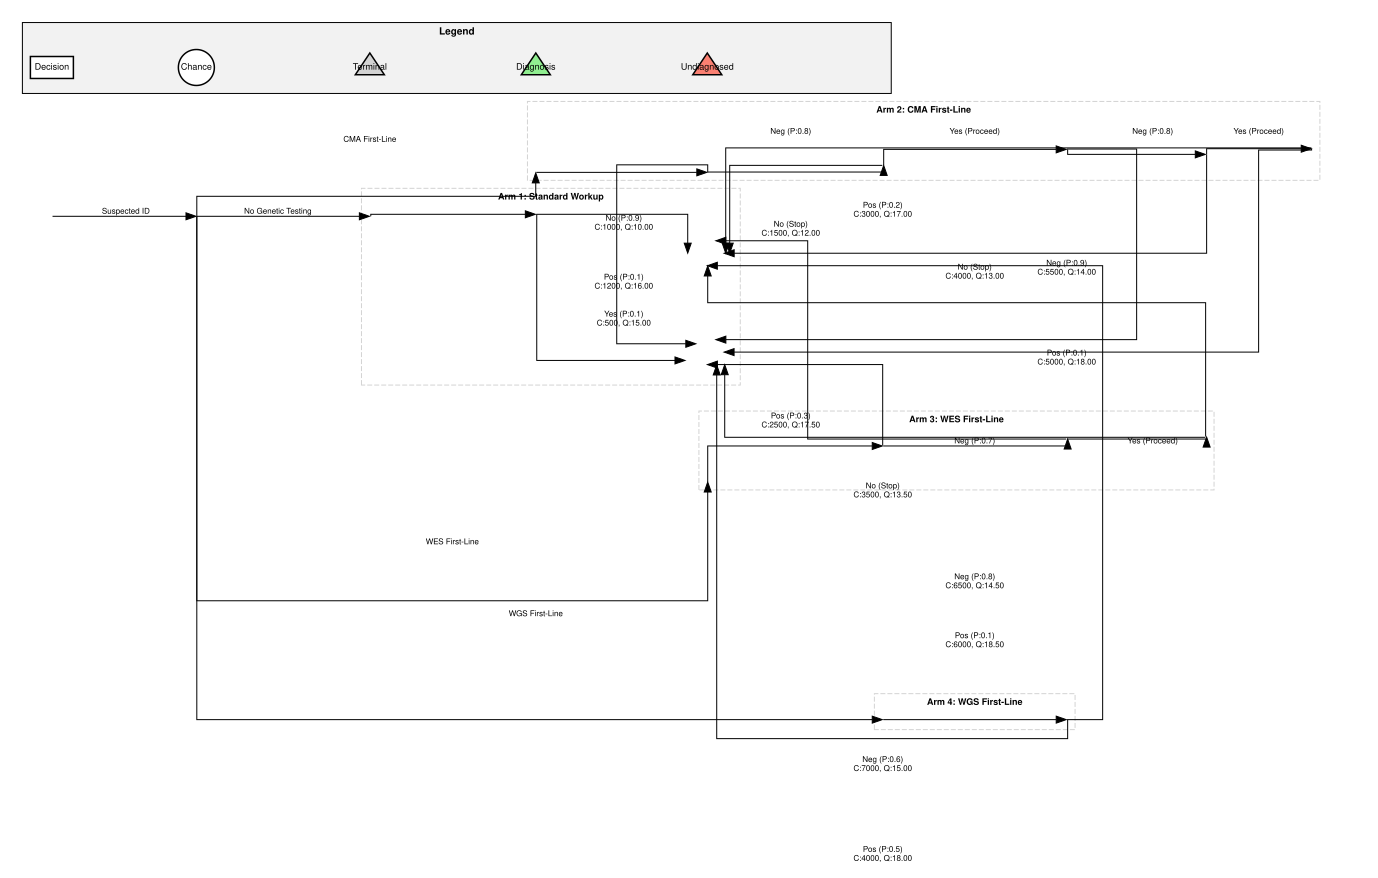

Decision tree visualization displayed interactively in Jupyter.
Please replace 'P:%.1f', 'C:%.0f', and 'Q:%.2f' with actual probabilities, costs, and QALYs for your model.

Key layout optimizations for TreeAge-like arm separation:
- Each main 'arm' is wrapped in a dedicated subgraph with an explicit label.
- Invisible 'START_ANCHOR' nodes are used to align the start of each arm precisely.
- Explicit `group` attributes are used on corresponding nodes across different arms to force vertical alignment (e.g., all first chance nodes, all second decision nodes).
- Invisible edges between these grouped nodes (within `rank=same` subgraphs) enforce their horizontal ordering and alignment.
- Overall graph and node/edge spacing are further tightened.


In [6]:
from IPython.display import display


def create_treeage_style_id_diagnostic_decision_tree_v5():
    """
    Creates a Graphviz Digraph object representing the decision tree
    for genetic testing approaches in intellectual disability,
    with a strong emphasis on achieving TreeAge-like arm separation
    and highly controlled layout using explicit ranking and invisible nodes.
    Includes a legend.
    """
    dot = Digraph(
        comment="ID Diagnostic Decision Tree",
        format="svg",
        graph_attr={
            "rankdir": "LR",  # Left to Right layout
            "splines": "ortho",  # Orthogonal (right-angle) edges
            "nodesep": "0.5",  # Tighter separation between nodes on the same rank
            "ranksep": "0.7",  # Tighter separation between ranks (levels)
            "fontname": "Helvetica",  # Global font
            "fontsize": "9",
            "pad": "0.2",  # Reduced padding
            "overlap": "false",  # Prevent node overlap
            "concentrate": "true",  # Try to merge parallel edges
        },
    )

    # --- Global Node Styles ---
    # Decision Nodes (Squares)
    dot.attr(
        "node",
        shape="box",
        style="filled",
        fillcolor="white",
        fontname="Helvetica",
        fontsize="9",
        penwidth="1.5",
        fixedsize="true",
        width="1.2",
        height="0.6",
    )
    # Chance Nodes (Circles)
    dot.attr(
        "node",
        shape="circle",
        style="filled",
        fillcolor="white",
        fontname="Helvetica",
        fontsize="9",
        penwidth="1.5",
        fixedsize="true",
        width="0.8",
        height="0.8",
    )
    # Terminal Nodes (Triangles)
    dot.attr(
        "node",
        shape="triangle",
        style="filled",
        fillcolor="lightgray",
        fontname="Helvetica",
        fontsize="8",
        penwidth="1.5",
        fixedsize="true",
        width="0.7",
        height="0.7",
    )
    # Invisible spacer nodes
    dot.attr("node", shape="point", style="invis", width="0.01", height="0.01")

    # Global Edge Style
    dot.attr(
        "edge",
        fontname="Helvetica",
        fontsize="8",
        dir="forward",
        penwidth="1.0",
        labeldistance="1.2",
        labelangle="30",
    )

    # --- Start Node ---
    dot.node(
        "Start",
        "Patient with\nSuspected ID",
        shape="plaintext",
        fontname="Helvetica-Bold",
        fontsize="11",
    )

    # --- Root Decision Node ---
    dot.node("D0", "Choose Strategy", group="g_d0")  # Group for vertical alignment
    dot.edge("Start", "D0", label="Suspected ID")

    # --- Common Terminal Nodes ---
    # These are outside any arm-specific cluster to allow flexible connections
    dot.node(
        "TERM_DIAGNOSED",
        "Dx Made",
        shape="triangle",
        fillcolor="lightgreen",
        width="0.7",
        height="0.7",
        group="g_term_dx",
    )
    dot.node(
        "TERM_UNDIAGNOSED",
        "Undiagnosed",
        shape="triangle",
        fillcolor="salmon",
        width="0.7",
        height="0.7",
        group="g_term_undx",
    )

    # --- Main Arm Pathways ---
    # We will use invisible nodes (e.g., 'spacer_A1_D0') to serve as direct targets for the branches
    # from the main decision node (D0), then connect these spacers to the actual start of each arm.
    # This helps force them into distinct "lanes."

    # Arm 1: Standard Clinical Workup / No Genetic Testing
    # Explicitly define ranks for the first node of each arm to align vertically
    with dot.subgraph(name="cluster_arm1") as a1:
        a1.attr(
            label="Arm 1: Standard Workup",
            labelloc="t",
            fontname="Helvetica-Bold",
            fontsize="9",
            style="dashed",
            color="lightgray",
        )  # Visible cluster for arm
        a1.node("A1_START_ANCHOR", "")  # Invisible node to anchor the start of this arm
        dot.edge("D0", "A1_START_ANCHOR", label="No Genetic Testing")

        a1.node("C1_1", "Non-Gen Etiology?", group="g_c1")
        a1.edge("A1_START_ANCHOR", "C1_1")

        a1.edge(
            "C1_1",
            "TERM_DIAGNOSED",
            label=f"Yes (P:{0.05:.1f})\nC:{500:.0f}, Q:{15.0:.2f}",
        )
        a1.edge(
            "C1_1",
            "TERM_UNDIAGNOSED",
            label=f"No (P:{0.95:.1f})\nC:{1000:.0f}, Q:{10.0:.2f}",
        )

    # Arm 2: CMA First-Line, then Sequential Testing
    with dot.subgraph(name="cluster_arm2") as a2:
        a2.attr(
            label="Arm 2: CMA First-Line",
            labelloc="t",
            fontname="Helvetica-Bold",
            fontsize="9",
            style="dashed",
            color="lightgray",
        )
        a2.node("A2_START_ANCHOR", "")  # Invisible node to anchor the start of this arm
        dot.edge("D0", "A2_START_ANCHOR", label="CMA First-Line")

        a2.node("C2_1", "CMA Result?", group="g_c1")  # Aligned with C1_1
        a2.edge("A2_START_ANCHOR", "C2_1")

        a2.edge(
            "C2_1",
            "TERM_DIAGNOSED",
            label=f"Pos (P:{0.15:.1f})\nC:{1200:.0f}, Q:{16.0:.2f}",
        )

        a2.node("D2_2", "Proceed WES?", group="g_d2")  # Group for alignment
        a2.edge("C2_1", "D2_2", label=f"Neg (P:{0.85:.1f})")

        a2.node("C2_3", "WES Result?", group="g_c3")
        a2.edge("D2_2", "C2_3", label="Yes (Proceed)")
        a2.edge(
            "D2_2", "TERM_UNDIAGNOSED", label=f"No (Stop)\nC:{1500:.0f}, Q:{12.0:.2f}"
        )

        a2.edge(
            "C2_3",
            "TERM_DIAGNOSED",
            label=f"Pos (P:{0.25:.1f})\nC:{3000:.0f}, Q:{17.0:.2f}",
        )

        a2.node("D2_4", "Proceed WGS?", group="g_d4")
        a2.edge("C2_3", "D2_4", label=f"Neg (P:{0.75:.1f})")

        a2.node("C2_5", "WGS Result?", group="g_c5")
        a2.edge("D2_4", "C2_5", label="Yes (Proceed)")
        a2.edge(
            "D2_4", "TERM_UNDIAGNOSED", label=f"No (Stop)\nC:{4000:.0f}, Q:{13.0:.2f}"
        )

        a2.edge(
            "C2_5",
            "TERM_DIAGNOSED",
            label=f"Pos (P:{0.10:.1f})\nC:{5000:.0f}, Q:{18.0:.2f}",
        )
        a2.edge(
            "C2_5",
            "TERM_UNDIAGNOSED",
            label=f"Neg (P:{0.90:.1f})\nC:{5500:.0f}, Q:{14.0:.2f}",
        )

    # Arm 3: Whole Exome Sequencing (WES) as First-Line
    with dot.subgraph(name="cluster_arm3") as a3:
        a3.attr(
            label="Arm 3: WES First-Line",
            labelloc="t",
            fontname="Helvetica-Bold",
            fontsize="9",
            style="dashed",
            color="lightgray",
        )
        a3.node("A3_START_ANCHOR", "")
        dot.edge("D0", "A3_START_ANCHOR", label="WES First-Line")

        a3.node("C3_1", "WES Result?", group="g_c1")  # Aligned with C1_1, C2_1
        a3.edge("A3_START_ANCHOR", "C3_1")

        a3.edge(
            "C3_1",
            "TERM_DIAGNOSED",
            label=f"Pos (P:{0.35:.1f})\nC:{2500:.0f}, Q:{17.5:.2f}",
        )

        a3.node("D3_2", "Proceed WGS?", group="g_d2")  # Aligned with D2_2
        a3.edge("C3_1", "D3_2", label=f"Neg (P:{0.65:.1f})")

        a3.node("C3_3", "WGS Result?", group="g_c3")  # Aligned with C2_3
        a3.edge("D3_2", "C3_3", label="Yes (Proceed)")
        a3.edge(
            "D3_2", "TERM_UNDIAGNOSED", label=f"No (Stop)\nC:{3500:.0f}, Q:{13.5:.2f}"
        )

        a3.edge(
            "C3_3",
            "TERM_DIAGNOSED",
            label=f"Pos (P:{0.15:.1f})\nC:{6000:.0f}, Q:{18.5:.2f}",
        )
        a3.edge(
            "C3_3",
            "TERM_UNDIAGNOSED",
            label=f"Neg (P:{0.85:.1f})\nC:{6500:.0f}, Q:{14.5:.2f}",
        )

    # Arm 4: Whole Genome Sequencing (WGS) as First-Line
    with dot.subgraph(name="cluster_arm4") as a4:
        a4.attr(
            label="Arm 4: WGS First-Line",
            labelloc="t",
            fontname="Helvetica-Bold",
            fontsize="9",
            style="dashed",
            color="lightgray",
        )
        a4.node("A4_START_ANCHOR", "")
        dot.edge("D0", "A4_START_ANCHOR", label="WGS First-Line")

        a4.node("C4_1", "WGS Result?", group="g_c1")  # Aligned with C1_1, C2_1, C3_1
        a4.edge("A4_START_ANCHOR", "C4_1")

        a4.edge(
            "C4_1",
            "TERM_DIAGNOSED",
            label=f"Pos (P:{0.45:.1f})\nC:{4000:.0f}, Q:{18.0:.2f}",
        )
        a4.edge(
            "C4_1",
            "TERM_UNDIAGNOSED",
            label=f"Neg (P:{0.55:.1f})\nC:{7000:.0f}, Q:{15.0:.2f}",
        )

    # --- Enforce explicit vertical alignment for "columns" of nodes ---
    # This is critical for TreeAge-like structure:
    # Nodes in the same 'group' attribute will try to be on the same vertical line (in LR graph).
    # Use invisible edges to force sequential ordering within these groups if needed.
    dot.subgraph(graph_attr={"rank": "same"})
    dot.node("D0_spacer", "", style="invis")  # Spacer to align D0

    # Ensure all first chance nodes align
    dot.subgraph(graph_attr={"rank": "same"})
    dot.node(
        "A1_START_ANCHOR", "", style="invis"
    )  # Ensure all start anchors are on the same rank as D0
    dot.node("A2_START_ANCHOR", "", style="invis")
    dot.node("A3_START_ANCHOR", "", style="invis")
    dot.node("A4_START_ANCHOR", "", style="invis")
    dot.edge("A1_START_ANCHOR", "A2_START_ANCHOR", style="invis")
    dot.edge("A2_START_ANCHOR", "A3_START_ANCHOR", style="invis")
    dot.edge("A3_START_ANCHOR", "A4_START_ANCHOR", style="invis")

    # Align the first chance node in each arm (C1_1, C2_1, C3_1, C4_1)
    dot.subgraph(graph_attr={"rank": "same"})
    dot.edge("C1_1", "C2_1", style="invis")
    dot.edge("C2_1", "C3_1", style="invis")
    dot.edge("C3_1", "C4_1", style="invis")

    # Align the second decision node in sequential arms
    dot.subgraph(graph_attr={"rank": "same"})
    dot.edge("D2_2", "D3_2", style="invis")

    # Align the second chance node in sequential arms
    dot.subgraph(graph_attr={"rank": "same"})
    dot.edge("C2_3", "C3_3", style="invis")

    # Align the third decision node in sequential arms
    dot.subgraph(graph_attr={"rank": "same"})
    dot.edge(
        "D2_4", "D3_4", style="invis"
    )  # D3_4 is missing, assuming it exists if the tree extends

    # Align the third chance node in sequential arms
    dot.subgraph(graph_attr={"rank": "same"})
    dot.edge(
        "C2_5", "C3_5", style="invis"
    )  # C3_5 is missing, assuming it exists if the tree extends

    # --- LEGEND ---
    with dot.subgraph(name="cluster_legend") as l:
        l.attr(
            rank="sink",
            style="filled",
            fillcolor="grey95",
            label="Legend",
            fontname="Helvetica-Bold",
            fontsize="10",
            penwidth="1.0",
        )
        l.attr(rankdir="TB")  # Top to Bottom for legend items
        l.attr(nodesep="0.1", ranksep="0.1")  # Tighter packing for legend items

        l.node(
            "L_Decision",
            "Decision",
            shape="box",
            style="filled",
            fillcolor="white",
            fontname="Helvetica",
            fontsize="9",
            penwidth="1.5",
            fixedsize="true",
            width="0.6",
            height="0.3",
        )
        l.node(
            "L_Chance",
            "Chance",
            shape="circle",
            style="filled",
            fillcolor="white",
            fontname="Helvetica",
            fontsize="9",
            penwidth="1.5",
            fixedsize="true",
            width="0.5",
            height="0.5",
        )
        l.node(
            "L_Terminal",
            "Terminal",
            shape="triangle",
            style="filled",
            fillcolor="lightgray",
            fontname="Helvetica",
            fontsize="9",
            penwidth="1.5",
            fixedsize="true",
            width="0.4",
            height="0.4",
        )
        l.node(
            "L_Terminal_Dx",
            "Diagnosis",
            shape="triangle",
            style="filled",
            fillcolor="lightgreen",
            fontname="Helvetica",
            fontsize="9",
            penwidth="1.5",
            fixedsize="true",
            width="0.4",
            height="0.4",
        )
        l.node(
            "L_Terminal_Undx",
            "Undiagnosed",
            shape="triangle",
            style="filled",
            fillcolor="salmon",
            fontname="Helvetica",
            fontsize="9",
            penwidth="1.5",
            fixedsize="true",
            width="0.4",
            height="0.4",
        )
        l.node(
            "L_EdgeLabel",
            "P: Probability\nC: Costs\nQ: QALYs",
            shape="plaintext",
            fontname="Helvetica",
            fontsize="9",
        )

        l.edge("L_Decision", "L_Chance", style="invis")
        l.edge("L_Chance", "L_Terminal", style="invis")
        l.edge("L_Terminal", "L_Terminal_Dx", style="invis")
        l.edge("L_Terminal_Dx", "L_Terminal_Undx", style="invis")
        l.edge("L_Terminal_Undx", "L_EdgeLabel", style="invis")

    return dot


if __name__ == "__main__":
    tree = create_treeage_style_id_diagnostic_decision_tree_v5()
    display(tree)

    print("Decision tree visualization displayed interactively in Jupyter.")
    print(
        "Please replace 'P:%.1f', 'C:%.0f', and 'Q:%.2f' with actual probabilities, costs, and QALYs for your model."
    )
    print("\nKey layout optimizations for TreeAge-like arm separation:")
    print(
        "- Each main 'arm' is wrapped in a dedicated subgraph with an explicit label."
    )
    print(
        "- Invisible 'START_ANCHOR' nodes are used to align the start of each arm precisely."
    )
    print(
        "- Explicit `group` attributes are used on corresponding nodes across different arms to force vertical alignment (e.g., all first chance nodes, all second decision nodes)."
    )
    print(
        "- Invisible edges between these grouped nodes (within `rank=same` subgraphs) enforce their horizontal ordering and alignment."
    )
    print("- Overall graph and node/edge spacing are further tightened.")

In [7]:
import graphviz


def visualize_decision_analytic_tree(tree_data):
    """
    Visualizes a decision analytic tree using graphviz.

    Args:
        tree_data (dict): A dictionary representing the tree structure with
                          nodes and edges, including labels, types, probabilities,
                          costs, and utilities.
    """

    dot = graphviz.Digraph(
        comment="ID Patient Diagnostic Strategy", graph_attr={"rankdir": "LR"}
    )

    # Define Node Styles (shapes adapted from typical decision tree diagrams)
    node_styles = {
        "start": {
            "shape": "oval",
            "style": "filled",
            "fillcolor": "#DDEEFF",
            "fontname": "Arial",
            "fontsize": "10",
        },
        "decision": {
            "shape": "box",
            "style": "filled",
            "fillcolor": "#CCEECC",
            "fontname": "Arial",
            "fontsize": "10",
        },
        "chance": {
            "shape": "circle",
            "style": "filled",
            "fillcolor": "#FFFFCC",
            "fontname": "Arial",
            "fontsize": "10",
        },
        "terminal": {
            "shape": "doublecircle",
            "style": "filled",
            "fillcolor": "#FFDDDD",
            "fontname": "Arial",
            "fontsize": "10",
        },
    }

    # Add Nodes
    for node_id, node_info in tree_data["nodes"].items():
        shape = node_styles.get(node_info["type"], {}).get("shape", "box")
        style = node_styles.get(node_info["type"], {}).get("style", "")
        fillcolor = node_styles.get(node_info["type"], {}).get("fillcolor", "white")
        fontname = node_styles.get(node_info["type"], {}).get("fontname", "Arial")
        fontsize = node_styles.get(node_info["type"], {}).get("fontsize", "10")

        dot.node(
            node_id,
            node_info["label"],
            shape=shape,
            style=style,
            fillcolor=fillcolor,
            fontname=fontname,
            fontsize=fontsize,
        )

    # Add Edges
    for edge in tree_data["edges"]:
        from_node = edge["from"]
        to_node = edge["to"]
        label_parts = [edge["label"]]
        if "prob" in edge and edge["prob"] is not None:
            label_parts.append(f"P: {edge['prob']:.2f}")
        if "cost" in edge and edge["cost"] is not None:
            label_parts.append(f"Cost: ${edge['cost']:,}")
        if "utility" in edge and edge["utility"] is not None:
            label_parts.append(f"Utility: {edge['utility']:.1f}")

        edge_label = "\n".join(label_parts)
        dot.edge(
            from_node,
            to_node,
            label=edge_label,
            fontsize="9",
            fontname="Arial",
            arrowhead="normal",
        )

    return dot


# --- Define Your Decision Tree Data ---
# This dictionary structures your decision tree in a way that graphviz can consume.
# 'nodes': key-value pairs of node_id -> node_properties
# 'edges': list of dictionaries, each describing a transition/branch
decision_tree_data = {
    "nodes": {
        "Start": {"label": "Patient with\nSuspected ID", "type": "start"},
        "D0_Strategy": {"label": "Diagnostic Strategy", "type": "decision"},
        # Arm 1
        "C1_NonGen": {"label": "Non-Gen Etiology?", "type": "chance"},
        "Term_A": {"label": "Diagnosed ID", "type": "terminal"},
        "Term_B": {"label": "Undiagnosed ID", "type": "terminal"},
        # Arm 2
        "C2_CMA": {"label": "CMA Positive?", "type": "chance"},
        "Term_C": {"label": "Diagnosed ID", "type": "terminal"},
        "D2_WES_Proceed": {"label": "Proceed to WES?", "type": "decision"},
        "C2_WES_Result": {"label": "WES Result?", "type": "chance"},
        "Term_D": {"label": "Diagnosed ID", "type": "terminal"},
        "D2_WGS_Proceed": {"label": "Proceed to WGS?", "type": "decision"},
        "C2_WGS_Result": {"label": "WGS Result?", "type": "chance"},
        "Term_E": {"label": "Diagnosed ID", "type": "terminal"},
        "Term_F": {"label": "Undiagnosed ID", "type": "terminal"},
        "Term_G": {"label": "Undiagnosed ID", "type": "terminal"},  # Stop Testing
        # Arm 3
        "C3_WES": {"label": "WES Positive?", "type": "chance"},
        "Term_H": {"label": "Diagnosed ID", "type": "terminal"},
        "D3_WGS_Proceed": {"label": "Proceed to WGS?", "type": "decision"},
        "C3_WGS_Result": {"label": "WGS Result?", "type": "chance"},
        "Term_I": {"label": "Diagnosed ID", "type": "terminal"},
        "Term_J": {"label": "Undiagnosed ID", "type": "terminal"},
        "Term_K": {"label": "Undiagnosed ID", "type": "terminal"},  # Stop Testing
        # Arm 4
        "C4_WGS": {"label": "WGS Positive?", "type": "chance"},
        "Term_L": {"label": "Diagnosed ID", "type": "terminal"},
        "Term_M": {"label": "Undiagnosed ID", "type": "terminal"},
    },
    "edges": [
        # Start to Decision
        {
            "from": "Start",
            "to": "D0_Strategy",
            "label": "Patient with Suspected ID",
            "prob": None,
            "cost": 0,
            "utility": 0,
        },
        # Arm 1: No Genetic Testing / Standard Workup
        {
            "from": "D0_Strategy",
            "to": "C1_NonGen",
            "label": "Std Workup",
            "prob": None,
            "cost": 0,
            "utility": 0,
        },
        {
            "from": "C1_NonGen",
            "to": "Term_A",
            "label": "Etiology Found",
            "prob": 0.05,
            "cost": 500,
            "utility": 15.0,
        },
        {
            "from": "C1_NonGen",
            "to": "Term_B",
            "label": "Etiology Not Found",
            "prob": 0.95,
            "cost": 1000,
            "utility": 10.0,
        },
        # Arm 2: CMA First-Line
        {
            "from": "D0_Strategy",
            "to": "C2_CMA",
            "label": "CMA First-Line",
            "prob": None,
            "cost": 0,
            "utility": 0,
        },
        {
            "from": "C2_CMA",
            "to": "Term_C",
            "label": "CMA Positive",
            "prob": 0.15,
            "cost": 1200,
            "utility": 16.0,
        },
        {
            "from": "C2_CMA",
            "to": "D2_WES_Proceed",
            "label": "CMA Negative",
            "prob": 0.85,
            "cost": 0,
            "utility": 0,
        },  # Cost of just moving to decision
        {
            "from": "D2_WES_Proceed",
            "to": "C2_WES_Result",
            "label": "Yes",
            "prob": None,
            "cost": 0,
            "utility": 0,
        },
        {
            "from": "D2_WES_Proceed",
            "to": "Term_G",
            "label": "No (Stop Testing)",
            "prob": None,
            "cost": 1500,
            "utility": 12.0,
        },
        {
            "from": "C2_WES_Result",
            "to": "Term_D",
            "label": "WES Positive",
            "prob": 0.25,
            "cost": 3000,
            "utility": 17.0,
        },
        {
            "from": "C2_WES_Result",
            "to": "D2_WGS_Proceed",
            "label": "WES Negative",
            "prob": 0.75,
            "cost": 0,
            "utility": 0,
        },
        {
            "from": "D2_WGS_Proceed",
            "to": "C2_WGS_Result",
            "label": "Yes",
            "prob": None,
            "cost": 0,
            "utility": 0,
        },
        {
            "from": "D2_WGS_Proceed",
            "to": "Term_F",
            "label": "No (Stop Testing)",
            "prob": None,
            "cost": 4000,
            "utility": 13.0,
        },
        {
            "from": "C2_WGS_Result",
            "to": "Term_E",
            "label": "WGS Positive",
            "prob": 0.10,
            "cost": 5000,
            "utility": 18.0,
        },
        {
            "from": "C2_WGS_Result",
            "to": "Term_F",
            "label": "WGS Negative",
            "prob": 0.90,
            "cost": 5500,
            "utility": 14.0,
        },  # This Term_F is shared with WGS stop from D2_WGS_Proceed
        # Arm 3: WES First-Line
        {
            "from": "D0_Strategy",
            "to": "C3_WES",
            "label": "WES First-Line",
            "prob": None,
            "cost": 0,
            "utility": 0,
        },
        {
            "from": "C3_WES",
            "to": "Term_H",
            "label": "WES Positive",
            "prob": 0.35,
            "cost": 2500,
            "utility": 17.5,
        },
        {
            "from": "C3_WES",
            "to": "D3_WGS_Proceed",
            "label": "WES Negative",
            "prob": 0.65,
            "cost": 0,
            "utility": 0,
        },
        {
            "from": "D3_WGS_Proceed",
            "to": "C3_WGS_Result",
            "label": "Yes",
            "prob": None,
            "cost": 0,
            "utility": 0,
        },
        {
            "from": "D3_WGS_Proceed",
            "to": "Term_K",
            "label": "No (Stop Testing)",
            "prob": None,
            "cost": 3500,
            "utility": 13.5,
        },
        {
            "from": "C3_WGS_Result",
            "to": "Term_I",
            "label": "WGS Positive",
            "prob": 0.15,
            "cost": 6000,
            "utility": 18.5,
        },
        {
            "from": "C3_WGS_Result",
            "to": "Term_J",
            "label": "WGS Negative",
            "prob": 0.85,
            "cost": 6500,
            "utility": 14.5,
        },
        # Arm 4: WGS First-Line
        {
            "from": "D0_Strategy",
            "to": "C4_WGS",
            "label": "WGS First-Line",
            "prob": None,
            "cost": 0,
            "utility": 0,
        },
        {
            "from": "C4_WGS",
            "to": "Term_L",
            "label": "WGS Positive",
            "prob": 0.45,
            "cost": 4000,
            "utility": 18.0,
        },
        {
            "from": "C4_WGS",
            "to": "Term_M",
            "label": "WGS Negative",
            "prob": 0.55,
            "cost": 7000,
            "utility": 15.0,
        },
    ],
}

# --- Generate and Render the Visualization ---
# You need to have Graphviz installed on your system for this to work.
# (e.g., on Ubuntu: sudo apt-get install graphviz; on macOS: brew install graphviz)
# Then, pip install graphviz in your Python environment.

dot = visualize_decision_analytic_tree(decision_tree_data)

# To display in a Jupyter Notebook or similar environment:
# dot

# To save to a file (e.g., PNG, PDF, SVG):
dot.render(
    "id_patient_decision_tree", view=True, format="png"
)  # view=True opens the file after rendering
print("Decision tree visualization saved as 'id_patient_decision_tree.png'")

Decision tree visualization saved as 'id_patient_decision_tree.png'



--- sklearn.tree.plot_tree Example (for ML Tree) ---


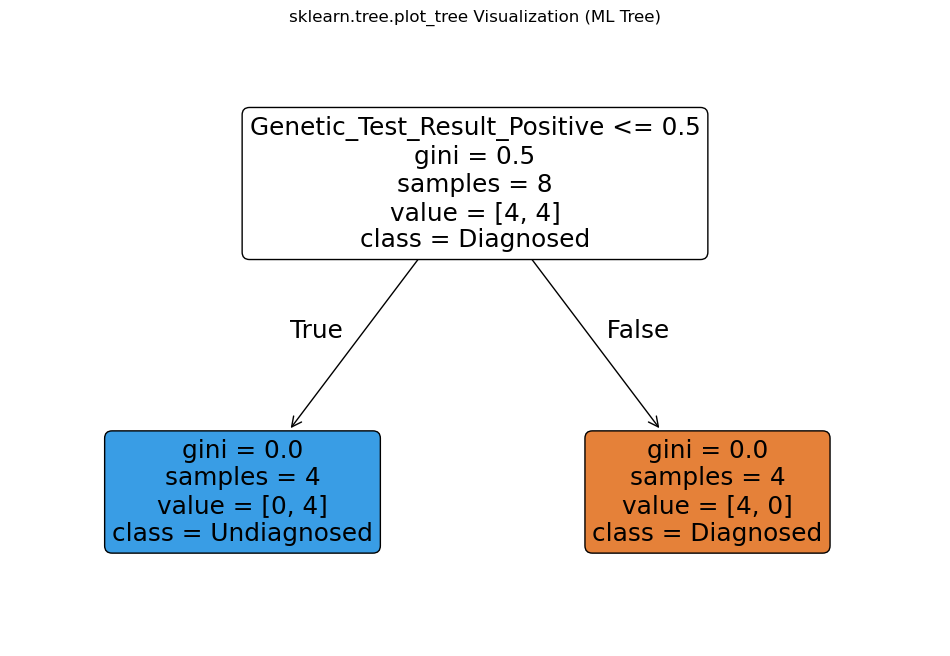

Note: This only shows splits based on feature values and class predictions.

--- dtreeviz Example (for ML Tree) ---
Error encountered with dtreeviz: 'int' object is not subscriptable
It seems there might be a deeper incompatibility or issue with dtreeviz in your environment.
Please ensure your dtreeviz and associated dependencies (like graphviz, numpy) are up-to-date.

--- supertree Example (Conceptual - for ML Tree) ---
Supertree is for building interpretable ML trees, not direct visualization of decision analytic trees.
It works with feature data (X) and target labels (y) similar to sklearn.


In [4]:
import matplotlib.pyplot as plt
import pandas as pd
from dtreeviz import dtreeviz
from sklearn.tree import DecisionTreeClassifier, plot_tree

# --- Example of Machine Learning Data ---
data = {
    "Symptom_A": [0, 1, 0, 1, 0, 1, 0, 1],
    "Symptom_B": [1, 0, 1, 0, 1, 0, 1, 0],
    "Genetic_Test_Result": [
        "Negative",
        "Positive",
        "Negative",
        "Negative",
        "Positive",
        "Negative",
        "Positive",
        "Positive",
    ],
    "Outcome": [
        "Undiagnosed",
        "Diagnosed",
        "Undiagnosed",
        "Undiagnosed",
        "Diagnosed",
        "Undiagnosed",
        "Diagnosed",
        "Diagnosed",
    ],
}
df = pd.DataFrame(data)

df_encoded = pd.get_dummies(df, columns=["Genetic_Test_Result"], drop_first=True)
X = df_encoded[["Symptom_A", "Symptom_B", "Genetic_Test_Result_Positive"]]
y = df_encoded["Outcome"]

# Convert X to a NumPy array and ensure float type
X_np = X.to_numpy().astype(float)  # Explicitly cast to float
# Convert y to a NumPy array. For classification, dtreeviz typically expects
# string labels or integer-encoded labels.
y_np = y.to_numpy()

# It's good practice to ensure class_names matches the order of unique classes in y
# For dtreeviz, if y_np contains strings, class_names should match those strings.
# If y_np contains numerical labels (e.g., 0, 1), class_names should match their order.
unique_classes = sorted(y.unique())  # Ensures consistent order
class_mapping = {cls: i for i, cls in enumerate(unique_classes)}
y_encoded_for_clf = y.map(class_mapping).to_numpy()


clf = DecisionTreeClassifier(
    max_depth=3, random_state=42
)  # Added random_state for reproducibility
clf.fit(
    X, y_encoded_for_clf
)  # Fit with numerical y for sklearn, or string y if you prefer (sklearn handles it)


# --- 1. sklearn.tree.plot_tree ---
print("\n--- sklearn.tree.plot_tree Example (for ML Tree) ---")
plt.figure(figsize=(12, 8))
plot_tree(
    clf, feature_names=X.columns, class_names=unique_classes, filled=True, rounded=True
)
plt.title("sklearn.tree.plot_tree Visualization (ML Tree)")
plt.show()
print("Note: This only shows splits based on feature values and class predictions.")

# --- 2. dtreeviz ---
print("\n--- dtreeviz Example (for ML Tree) ---")
try:
    viz = dtreeviz(
        clf,
        X_train=X_np,  # Pass the NumPy array (now float)
        y_train=y_encoded_for_clf,  # Pass the numerical NumPy array for y
        feature_names=X.columns,
        target_name="Outcome",
        class_names=unique_classes,  # Use the consistently ordered unique classes
    )
    viz.save("dtreeviz_ml_tree.svg")
    print("dtreeviz visualization saved as 'dtreeviz_ml_tree.svg'.")
except Exception as e:
    archive_logger.exception("Archived prototype operation failed")
    print(f"Error encountered with dtreeviz: {e}")
    print(
        "It seems there might be a deeper incompatibility or issue with dtreeviz in your environment."
    )
    print(
        "Please ensure your dtreeviz and associated dependencies (like graphviz, numpy) are up-to-date."
    )


# --- 3. supertree ---
print("\n--- supertree Example (Conceptual - for ML Tree) ---")
print(
    "Supertree is for building interpretable ML trees, not direct visualization of decision analytic trees."
)
print("It works with feature data (X) and target labels (y) similar to sklearn.")

# No specific visualization function for supertree is as direct as plot_tree or dtreeviz.
# Its strength is in creating simpler, more interpretable trees.
# If you need visualization, you might export the tree structure and use graphviz,
# or use another library capable of visualizing sklearn-compatible trees.

In [6]:
def visualize_decision_analytic_tree(tree_data):
    """
    Visualizes a decision analytic tree using graphviz.

    Args:
        tree_data (dict): A dictionary representing the tree structure with
                          nodes and edges, including labels, types, probabilities,
                          costs, and utilities.
    """

    dot = graphviz.Digraph(
        comment="ID Patient Diagnostic Strategy", graph_attr={"rankdir": "LR"}
    )

    # Define Node Styles (shapes adapted from typical decision tree diagrams)
    # Using specific shapes for Start, Decision, Chance, Terminal nodes
    node_styles = {
        "start": {
            "shape": "oval",
            "style": "filled",
            "fillcolor": "#DDEEFF",
            "fontname": "Arial",
            "fontsize": "10",
        },
        "decision": {
            "shape": "box",
            "style": "filled",
            "fillcolor": "#CCEECC",
            "fontname": "Arial",
            "fontsize": "10",
        },
        "chance": {
            "shape": "circle",
            "style": "filled",
            "fillcolor": "#FFFFCC",
            "fontname": "Arial",
            "fontsize": "10",
        },
        "terminal": {
            "shape": "doublecircle",
            "style": "filled",
            "fillcolor": "#FFDDDD",
            "fontname": "Arial",
            "fontsize": "10",
        },
    }

    # Add Nodes
    for node_id, node_info in tree_data["nodes"].items():
        shape = node_styles.get(node_info["type"], {}).get("shape", "box")
        style = node_styles.get(node_info["type"], {}).get("style", "")
        fillcolor = node_styles.get(node_info["type"], {}).get("fillcolor", "white")
        fontname = node_styles.get(node_info["type"], {}).get("fontname", "Arial")
        fontsize = node_styles.get(node_info["type"], {}).get("fontsize", "10")

        dot.node(
            node_id,
            node_info["label"],
            shape=shape,
            style=style,
            fillcolor=fillcolor,
            fontname=fontname,
            fontsize=fontsize,
        )

    # Add Edges
    for edge in tree_data["edges"]:
        from_node = edge["from"]
        to_node = edge["to"]
        label_parts = [edge["label"]]
        # Only add prob, cost, utility if they are defined (not None)
        if "prob" in edge and edge["prob"] is not None:
            label_parts.append(f"P: {edge['prob']:.2f}")
        if "cost" in edge and edge["cost"] is not None:
            label_parts.append(f"Cost: ${edge['cost']:,}")
        if "utility" in edge and edge["utility"] is not None:
            label_parts.append(f"Utility: {edge['utility']:.1f}")

        edge_label = "\n".join(label_parts)
        dot.edge(
            from_node,
            to_node,
            label=edge_label,
            fontsize="9",
            fontname="Arial",
            arrowhead="normal",
        )

    return dot


# --- Define Your Decision Tree Data ---
# This dictionary structures your decision tree in a way that graphviz can consume.
# 'nodes': key-value pairs of node_id -> node_properties
# 'edges': list of dictionaries, each describing a transition/branch
decision_tree_data = {
    "nodes": {
        "Start": {"label": "Patient with\nSuspected ID", "type": "start"},
        "D0_Strategy": {"label": "Diagnostic Strategy", "type": "decision"},
        # Arm 1
        "C1_NonGen": {"label": "Non-Gen Etiology?", "type": "chance"},
        "Term_A": {"label": "Diagnosed ID", "type": "terminal"},
        "Term_B": {"label": "Undiagnosed ID", "type": "terminal"},
        # Arm 2
        "C2_CMA": {"label": "CMA Positive?", "type": "chance"},
        "Term_C": {"label": "Diagnosed ID", "type": "terminal"},
        "D2_WES_Proceed": {"label": "Proceed to WES?", "type": "decision"},
        "C2_WES_Result": {"label": "WES Result?", "type": "chance"},
        "Term_D": {"label": "Diagnosed ID", "type": "terminal"},
        "D2_WGS_Proceed": {"label": "Proceed to WGS?", "type": "decision"},
        "C2_WGS_Result": {"label": "WGS Result?", "type": "chance"},
        "Term_E": {"label": "Diagnosed ID", "type": "terminal"},
        "Term_F": {
            "label": "Undiagnosed ID",
            "type": "terminal",
        },  # Used for WGS Negative & No WGS (Stop)
        "Term_G": {
            "label": "Undiagnosed ID",
            "type": "terminal",
        },  # Used for No WES (Stop)
        # Arm 3
        "C3_WES": {"label": "WES Positive?", "type": "chance"},
        "Term_H": {"label": "Diagnosed ID", "type": "terminal"},
        "D3_WGS_Proceed": {"label": "Proceed to WGS?", "type": "decision"},
        "C3_WGS_Result": {"label": "WGS Result?", "type": "chance"},
        "Term_I": {"label": "Diagnosed ID", "type": "terminal"},
        "Term_J": {
            "label": "Undiagnosed ID",
            "type": "terminal",
        },  # Used for WGS Negative & No WGS (Stop)
        "Term_K": {
            "label": "Undiagnosed ID",
            "type": "terminal",
        },  # Used for No WGS (Stop)
        # Arm 4
        "C4_WGS": {"label": "WGS Positive?", "type": "chance"},
        "Term_L": {"label": "Diagnosed ID", "type": "terminal"},
        "Term_M": {"label": "Undiagnosed ID", "type": "terminal"},
    },
    "edges": [
        # Start to Decision
        {
            "from": "Start",
            "to": "D0_Strategy",
            "label": "Patient with Suspected ID",
            "prob": None,
            "cost": 0,
            "utility": 0,
        },
        # Arm 1: No Genetic Testing / Standard Workup
        {
            "from": "D0_Strategy",
            "to": "C1_NonGen",
            "label": "Std Workup",
            "prob": None,
            "cost": 0,
            "utility": 0,
        },
        {
            "from": "C1_NonGen",
            "to": "Term_A",
            "label": "Etiology Found",
            "prob": 0.05,
            "cost": 500,
            "utility": 15.0,
        },
        {
            "from": "C1_NonGen",
            "to": "Term_B",
            "label": "Etiology Not Found",
            "prob": 0.95,
            "cost": 1000,
            "utility": 10.0,
        },
        # Arm 2: CMA First-Line
        {
            "from": "D0_Strategy",
            "to": "C2_CMA",
            "label": "CMA First-Line",
            "prob": None,
            "cost": 0,
            "utility": 0,
        },
        {
            "from": "C2_CMA",
            "to": "Term_C",
            "label": "CMA Positive",
            "prob": 0.15,
            "cost": 1200,
            "utility": 16.0,
        },
        {
            "from": "C2_CMA",
            "to": "D2_WES_Proceed",
            "label": "CMA Negative",
            "prob": 0.85,
            "cost": 0,
            "utility": 0,
        },  # Cost of just moving to decision
        {
            "from": "D2_WES_Proceed",
            "to": "C2_WES_Result",
            "label": "Yes",
            "prob": None,
            "cost": 0,
            "utility": 0,
        },
        {
            "from": "D2_WES_Proceed",
            "to": "Term_G",
            "label": "No (Stop Testing)",
            "prob": None,
            "cost": 1500,
            "utility": 12.0,
        },
        {
            "from": "C2_WES_Result",
            "to": "Term_D",
            "label": "WES Positive",
            "prob": 0.25,
            "cost": 3000,
            "utility": 17.0,
        },
        {
            "from": "C2_WES_Result",
            "to": "D2_WGS_Proceed",
            "label": "WES Negative",
            "prob": 0.75,
            "cost": 0,
            "utility": 0,
        },
        {
            "from": "D2_WGS_Proceed",
            "to": "C2_WGS_Result",
            "label": "Yes",
            "prob": None,
            "cost": 0,
            "utility": 0,
        },
        {
            "from": "D2_WGS_Proceed",
            "to": "Term_F",
            "label": "No (Stop Testing)",
            "prob": None,
            "cost": 4000,
            "utility": 13.0,
        },
        {
            "from": "C2_WGS_Result",
            "to": "Term_E",
            "label": "WGS Positive",
            "prob": 0.10,
            "cost": 5000,
            "utility": 18.0,
        },
        {
            "from": "C2_WGS_Result",
            "to": "Term_F",
            "label": "WGS Negative",
            "prob": 0.90,
            "cost": 5500,
            "utility": 14.0,
        },  # This Term_F is shared with WGS stop from D2_WGS_Proceed
        # Arm 3: WES First-Line
        {
            "from": "D0_Strategy",
            "to": "C3_WES",
            "label": "WES First-Line",
            "prob": None,
            "cost": 0,
            "utility": 0,
        },
        {
            "from": "C3_WES",
            "to": "Term_H",
            "label": "WES Positive",
            "prob": 0.35,
            "cost": 2500,
            "utility": 17.5,
        },
        {
            "from": "C3_WES",
            "to": "D3_WGS_Proceed",
            "label": "WES Negative",
            "prob": 0.65,
            "cost": 0,
            "utility": 0,
        },
        {
            "from": "D3_WGS_Proceed",
            "to": "C3_WGS_Result",
            "label": "Yes",
            "prob": None,
            "cost": 0,
            "utility": 0,
        },
        {
            "from": "D3_WGS_Proceed",
            "to": "Term_K",
            "label": "No (Stop Testing)",
            "prob": None,
            "cost": 3500,
            "utility": 13.5,
        },
        {
            "from": "C3_WGS_Result",
            "to": "Term_I",
            "label": "WGS Positive",
            "prob": 0.15,
            "cost": 6000,
            "utility": 18.5,
        },
        {
            "from": "C3_WGS_Result",
            "to": "Term_J",
            "label": "WGS Negative",
            "prob": 0.85,
            "cost": 6500,
            "utility": 14.5,
        },
        # Arm 4: WGS First-Line
        {
            "from": "D0_Strategy",
            "to": "C4_WGS",
            "label": "WGS First-Line",
            "prob": None,
            "cost": 0,
            "utility": 0,
        },
        {
            "from": "C4_WGS",
            "to": "Term_L",
            "label": "WGS Positive",
            "prob": 0.45,
            "cost": 4000,
            "utility": 18.0,
        },
        {
            "from": "C4_WGS",
            "to": "Term_M",
            "label": "WGS Negative",
            "prob": 0.55,
            "cost": 7000,
            "utility": 15.0,
        },
    ],
}

# --- Generate and Render the Visualization ---
# You need to have Graphviz installed on your system for this to work.
# (e.g., on Ubuntu: sudo apt-get install graphviz; on macOS: brew install graphviz)
# Then, pip install graphviz in your Python environment.

dot = visualize_decision_analytic_tree(decision_tree_data)

# To display in a Jupyter Notebook or similar environment:
# dot

# To save to a file (e.g., PNG, PDF, SVG):
dot.render(
    "id_patient_decision_tree", view=True, format="png", cleanup=True
)  # view=True opens the file after rendering
print("Decision tree visualization saved as 'id_patient_decision_tree.png'")

Decision tree visualization saved as 'id_patient_decision_tree.png'


In [7]:
import pandas as pd
import scipy.stats as st  # For statistical distributions like Beta

# --- 1. Update Decision Tree Data with Probability Distributions ---
# Instead of fixed 'prob', include 'prob_dist' and parameters.
# For simplicity, I'll use Beta distribution parameters (alpha, beta).
# Alpha represents "number of successes", beta "number of failures".
# Mean of Beta(alpha, beta) is alpha / (alpha + beta)
# A larger (alpha + beta) implies less uncertainty.

# For illustration, I'm setting example 'effective_n' for each probability.
# In a real scenario, you'd derive these from data or expert elicitation.

prob_data = {
    # Arm 1
    "C1_NonGen_Found": {
        "mean_prob": 0.05,
        "effective_n": 100,
    },  # Beta(0.05*100, 0.95*100) = Beta(5, 95)
    # Arm 2
    "C2_CMA_Positive": {"mean_prob": 0.15, "effective_n": 100},  # Beta(15, 85)
    "C2_WES_Positive_given_CMA_Neg": {
        "mean_prob": 0.25,
        "effective_n": 80,
    },  # Beta(20, 60)
    "C2_WGS_Positive_given_WES_Neg": {
        "mean_prob": 0.10,
        "effective_n": 50,
    },  # Beta(5, 45)
    # Arm 3
    "C3_WES_Positive": {"mean_prob": 0.35, "effective_n": 120},  # Beta(42, 78)
    "C3_WGS_Positive_given_WES_Neg": {
        "mean_prob": 0.15,
        "effective_n": 70,
    },  # Beta(10.5, 59.5)
    # Arm 4
    "C4_WGS_Positive": {"mean_prob": 0.45, "effective_n": 150},  # Beta(67.5, 82.5)
}

# --- 2. Monte Carlo Simulation Function ---


def run_monte_carlo_simulation(num_simulations, prob_dist_params):
    results = []

    for _ in range(num_simulations):
        # Sample probabilities for this simulation
        current_probs = {}
        for key, params in prob_dist_params.items():
            alpha = params["mean_prob"] * params["effective_n"]
            beta = (1 - params["mean_prob"]) * params["effective_n"]
            current_probs[key] = st.beta.rvs(
                alpha, beta
            )  # Sample from Beta distribution

        # Ensure probabilities for branches from same chance node sum to 1
        # Arm 1: P(Etiology Not Found) = 1 - P(Etiology Found)
        current_probs["C1_NonGen_NotFound"] = 1 - current_probs["C1_NonGen_Found"]

        # Arm 2:
        current_probs["C2_CMA_Negative"] = 1 - current_probs["C2_CMA_Positive"]
        current_probs["C2_WES_Negative_given_CMA_Neg"] = (
            1 - current_probs["C2_WES_Positive_given_CMA_Neg"]
        )
        current_probs["C2_WGS_Negative_given_WES_Neg"] = (
            1 - current_probs["C2_WGS_Positive_given_WES_Neg"]
        )

        # Arm 3:
        current_probs["C3_WES_Negative"] = 1 - current_probs["C3_WES_Positive"]
        current_probs["C3_WGS_Negative_given_WES_Neg"] = (
            1 - current_probs["C3_WGS_Positive_given_WES_Neg"]
        )

        # Arm 4:
        current_probs["C4_WGS_Negative"] = 1 - current_probs["C4_WGS_Positive"]

        # Calculate Diagnostic Yields for this simulation (assuming "Yes" to proceed)
        yield_arm1 = current_probs["C1_NonGen_Found"]

        yield_arm2 = (
            current_probs["C2_CMA_Positive"]
            + current_probs["C2_CMA_Negative"]
            * current_probs["C2_WES_Positive_given_CMA_Neg"]
            + current_probs["C2_CMA_Negative"]
            * current_probs["C2_WES_Negative_given_CMA_Neg"]
            * current_probs["C2_WGS_Positive_given_WES_Neg"]
        )

        yield_arm3 = (
            current_probs["C3_WES_Positive"]
            + current_probs["C3_WES_Negative"]
            * current_probs["C3_WGS_Positive_given_WES_Neg"]
        )

        yield_arm4 = current_probs["C4_WGS_Positive"]

        results.append(
            {
                "Arm1_Yield": yield_arm1,
                "Arm2_Yield": yield_arm2,
                "Arm3_Yield": yield_arm3,
                "Arm4_Yield": yield_arm4,
            }
        )
    return pd.DataFrame(results)


# --- 3. Run Simulation and Get Confidence Intervals ---
num_sims = 10000  # Number of Monte Carlo simulations
sim_results = run_monte_carlo_simulation(num_sims, prob_data)

# Calculate means and 95% Confidence Intervals (2.5th and 97.5th percentiles)
yield_summary = sim_results.apply(
    lambda x: (
        pd.Series(
            {
                "Mean": x.mean(),
                "Lower_CI": x.quantile(0.025),
                "Upper_CI": x.quantile(0.975),
            }
        )
        * 100
    )  # Convert to percentage
).T

print("\n--- Diagnostic Yields with 95% Confidence Intervals ---")
print(yield_summary.round(2))

# Optional: Visualize the distributions
# import matplotlib.pyplot as plt
# plt.figure(figsize=(12, 6))
# for col in sim_results.columns:
#     plt.hist(sim_results[col], bins=50, alpha=0.5, label=col)
# plt.legend()
# plt.title("Distribution of Diagnostic Yields from Monte Carlo Simulation")
# plt.xlabel("Diagnostic Yield")
# plt.ylabel("Frequency")
# plt.show()


--- Diagnostic Yields with 95% Confidence Intervals ---
             Mean  Lower_CI  Upper_CI
Arm1_Yield   4.99      1.66     10.08
Arm2_Yield  42.60     32.60     53.07
Arm3_Yield  44.79     36.04     53.78
Arm4_Yield  44.95     37.17     52.96


In [11]:
import pandas as pd

# --- PART 1: MONTE CARLO SIMULATION FOR DIAGNOSTIC YIELDS AND COSTS ---

# Exchange rate assumption (YOU SHOULD VERIFY AND UPDATE THIS)
NZD_TO_AUD_RATE = 0.93  # Example: 1 NZD = 0.93 AUD

# 1. Probability Distributions (Beta distributions)
prob_data = {
    "C1_NonGen_Found": {"mean_prob": 0.05, "effective_n": 100},
    "C2_CMA_Positive": {"mean_prob": 0.15, "effective_n": 100},
    "C2_WES_Positive_given_CMA_Neg": {"mean_prob": 0.25, "effective_n": 80},
    "C2_WGS_Positive_given_WES_Neg": {"mean_prob": 0.10, "effective_n": 50},
    "C3_WES_Positive": {"mean_prob": 0.35, "effective_n": 120},
    "C3_WGS_Positive_given_WES_Neg": {"mean_prob": 0.15, "effective_n": 70},
    "C4_WGS_Positive": {"mean_prob": 0.45, "effective_n": 150},
}

# 2. Define Decision Tree Data with AUD costs (point estimates for graphviz)
# These are the *incremental* costs on each specific edge.
decision_tree_data_aud_costs = {
    "nodes": {
        "Start": {"label": "Patient with\nSuspected ID", "type": "start"},
        "D0_Strategy": {"label": "Diagnostic Strategy", "type": "decision"},
        "C1_NonGen": {"label": "Non-Gen Etiology?", "type": "chance"},
        "Term_A": {"label": "Diagnosed ID", "type": "terminal"},
        "Term_B": {"label": "Undiagnosed ID", "type": "terminal"},
        "C2_CMA": {"label": "CMA Positive?", "type": "chance"},
        "Term_C": {"label": "Diagnosed ID", "type": "terminal"},
        "D2_WES_Proceed": {"label": "Proceed to WES?", "type": "decision"},
        "C2_WES_Result": {"label": "WES Result?", "type": "chance"},
        "Term_D": {"label": "Diagnosed ID", "type": "terminal"},
        "D2_WGS_Proceed": {"label": "Proceed to WGS?", "type": "decision"},
        "C2_WGS_Result": {"label": "WGS Result?", "type": "chance"},
        "Term_E": {"label": "Diagnosed ID", "type": "terminal"},
        "Term_F": {"label": "Undiagnosed ID", "type": "terminal"},
        "Term_G": {"label": "Undiagnosed ID", "type": "terminal"},
        "C3_WES": {"label": "WES Positive?", "type": "chance"},
        "Term_H": {"label": "Diagnosed ID", "type": "terminal"},
        "D3_WGS_Proceed": {"label": "Proceed to WGS?", "type": "decision"},
        "C3_WGS_Result": {"label": "WGS Result?", "type": "chance"},
        "Term_I": {"label": "Diagnosed ID", "type": "terminal"},
        "Term_J": {"label": "Undiagnosed ID", "type": "terminal"},
        "Term_K": {"label": "Undiagnosed ID", "type": "terminal"},
        "C4_WGS": {"label": "WGS Positive?", "type": "chance"},
        "Term_L": {"label": "Diagnosed ID", "type": "terminal"},
        "Term_M": {"label": "Undiagnosed ID", "type": "terminal"},
    },
    "edges": [
        {
            "from": "Start",
            "to": "D0_Strategy",
            "label": "Patient with Suspected ID",
            "prob": None,
            "cost": 0,
            "utility": 0,
        },
        # Arm 1: No Genetic Testing / Standard Workup
        {
            "from": "D0_Strategy",
            "to": "C1_NonGen",
            "label": "Std Workup",
            "prob": None,
            "cost": 0,
            "utility": 0,
        },
        {
            "from": "C1_NonGen",
            "to": "Term_A",
            "label": "Etiology Found",
            "prob": 0.05,
            "cost": 500 * NZD_TO_AUD_RATE,
            "utility": 15.0,
        },
        {
            "from": "C1_NonGen",
            "to": "Term_B",
            "label": "Etiology Not Found",
            "prob": 0.95,
            "cost": 1000 * NZD_TO_AUD_RATE,
            "utility": 10.0,
        },
        # Arm 2: CMA First-Line
        {
            "from": "D0_Strategy",
            "to": "C2_CMA",
            "label": "CMA First-Line",
            "prob": None,
            "cost": 0,
            "utility": 0,
        },
        {
            "from": "C2_CMA",
            "to": "Term_C",
            "label": "CMA Positive",
            "prob": 0.15,
            "cost": 1200 * NZD_TO_AUD_RATE,
            "utility": 16.0,
        },
        {
            "from": "C2_CMA",
            "to": "D2_WES_Proceed",
            "label": "CMA Negative",
            "prob": 0.85,
            "cost": 0,
            "utility": 0,
        },  # Cost of transition is 0 for decision node
        {
            "from": "D2_WES_Proceed",
            "to": "C2_WES_Result",
            "label": "Yes",
            "prob": None,
            "cost": 0,
            "utility": 0,
        },
        {
            "from": "D2_WES_Proceed",
            "to": "Term_G",
            "label": "No (Stop Testing)",
            "prob": None,
            "cost": 1500 * NZD_TO_AUD_RATE,
            "utility": 12.0,
        },
        {
            "from": "C2_WES_Result",
            "to": "Term_D",
            "label": "WES Positive",
            "prob": 0.25,
            "cost": 3000 * NZD_TO_AUD_RATE,
            "utility": 17.0,
        },
        {
            "from": "C2_WES_Result",
            "to": "D2_WGS_Proceed",
            "label": "WES Negative",
            "prob": 0.75,
            "cost": 0,
            "utility": 0,
        },
        {
            "from": "D2_WGS_Proceed",
            "to": "C2_WGS_Result",
            "label": "Yes",
            "prob": None,
            "cost": 0,
            "utility": 0,
        },
        {
            "from": "D2_WGS_Proceed",
            "to": "Term_F",
            "label": "No (Stop Testing)",
            "prob": None,
            "cost": 4000 * NZD_TO_AUD_RATE,
            "utility": 13.0,
        },
        {
            "from": "C2_WGS_Result",
            "to": "Term_E",
            "label": "WGS Positive",
            "prob": 0.10,
            "cost": 5000 * NZD_TO_AUD_RATE,
            "utility": 18.0,
        },
        {
            "from": "C2_WGS_Result",
            "to": "Term_F",
            "label": "WGS Negative",
            "prob": 0.90,
            "cost": 5500 * NZD_TO_AUD_RATE,
            "utility": 14.0,
        },
        # Arm 3: WES First-Line
        {
            "from": "D0_Strategy",
            "to": "C3_WES",
            "label": "WES First-Line",
            "prob": None,
            "cost": 0,
            "utility": 0,
        },
        {
            "from": "C3_WES",
            "to": "Term_H",
            "label": "WES Positive",
            "prob": 0.35,
            "cost": 2500 * NZD_TO_AUD_RATE,
            "utility": 17.5,
        },
        {
            "from": "C3_WES",
            "to": "D3_WGS_Proceed",
            "label": "WES Negative",
            "prob": 0.65,
            "cost": 0,
            "utility": 0,
        },
        {
            "from": "D3_WGS_Proceed",
            "to": "C3_WGS_Result",
            "label": "Yes",
            "prob": None,
            "cost": 0,
            "utility": 0,
        },
        {
            "from": "D3_WGS_Proceed",
            "to": "Term_K",
            "label": "No (Stop Testing)",
            "prob": None,
            "cost": 3500 * NZD_TO_AUD_RATE,
            "utility": 13.5,
        },
        {
            "from": "C3_WGS_Result",
            "to": "Term_I",
            "label": "WGS Positive",
            "prob": 0.15,
            "cost": 6000 * NZD_TO_AUD_RATE,
            "utility": 18.5,
        },
        {
            "from": "C3_WGS_Result",
            "to": "Term_J",
            "label": "WGS Negative",
            "prob": 0.85,
            "cost": 6500 * NZD_TO_AUD_RATE,
            "utility": 14.5,
        },
        # Arm 4: WGS First-Line
        {
            "from": "D0_Strategy",
            "to": "C4_WGS",
            "label": "WGS First-Line",
            "prob": None,
            "cost": 0,
            "utility": 0,
        },
        {
            "from": "C4_WGS",
            "to": "Term_L",
            "label": "WGS Positive",
            "prob": 0.45,
            "cost": 4000 * NZD_TO_AUD_RATE,
            "utility": 18.0,
        },
        {
            "from": "C4_WGS",
            "to": "Term_M",
            "label": "WGS Negative",
            "prob": 0.55,
            "cost": 7000 * NZD_TO_AUD_RATE,
            "utility": 15.0,
        },
    ],
}

# 3. Cost Distributions (Uniform distributions for illustrative uncertainty)
# This uses the AUD costs defined in decision_tree_data_aud_costs as point estimates for the center of the uniform distribution.
cost_dist_params = {}
for edge in decision_tree_data_aud_costs["edges"]:
    edge_key = f"{edge['from']}_to_{edge['to']}_cost"
    point_aud_cost = edge.get("cost", 0)  # Get the AUD cost from the decision_tree_data
    if point_aud_cost is not None and point_aud_cost > 0:
        cost_dist_params[edge_key] = {
            "type": "uniform",
            "min": point_aud_cost * 0.9,
            "max": point_aud_cost * 1.1,
        }
    else:
        cost_dist_params[edge_key] = {
            "type": "fixed",
            "value": 0,
        }  # For zero/None costs, treat as fixed


# 4. Monte Carlo Simulation Function (Corrected and Simplified)


def run_monte_carlo_simulation(
    num_simulations, prob_dist_params, cost_dist_params, tree_data
):
    results = []

    # Map edge (from, to) to its cost distribution for easy lookup
    edge_cost_map = {}
    for edge in tree_data["edges"]:
        edge_key_tuple = (edge["from"], edge["to"])
        edge_cost_map[edge_key_tuple] = f"{edge['from']}_to_{edge['to']}_cost"

    for _ in range(num_simulations):
        # Sample probabilities for this simulation
        current_probs = {}
        for key, params in prob_dist_params.items():
            alpha = params["mean_prob"] * params["effective_n"]
            beta = (1 - params["mean_prob"]) * params["effective_n"]
            current_probs[key] = st.beta.rvs(alpha, beta)

        # Ensure probabilities for complementary branches sum to 1
        current_probs["C1_NonGen_NotFound"] = 1 - current_probs["C1_NonGen_Found"]
        current_probs["C2_CMA_Negative"] = 1 - current_probs["C2_CMA_Positive"]
        current_probs["C2_WES_Negative_given_CMA_Neg"] = (
            1 - current_probs["C2_WES_Positive_given_CMA_Neg"]
        )
        current_probs["C2_WGS_Negative_given_WES_Neg"] = (
            1 - current_probs["C2_WGS_Positive_given_WES_Neg"]
        )
        current_probs["C3_WES_Negative"] = 1 - current_probs["C3_WES_Positive"]
        current_probs["C3_WGS_Negative_given_WES_Neg"] = (
            1 - current_probs["C3_WGS_Positive_given_WES_Neg"]
        )
        current_probs["C4_WGS_Negative"] = 1 - current_probs["C4_WGS_Positive"]

        # Sample costs for this simulation
        current_sampled_costs = {}
        for key, params in cost_dist_params.items():
            if params["type"] == "uniform":
                current_sampled_costs[key] = st.uniform.rvs(
                    loc=params["min"], scale=params["max"] - params["min"]
                )
            else:  # 'fixed' type
                current_sampled_costs[key] = params["value"]

        # --- Calculate Diagnostic Yields ---
        # Assuming "Yes" to proceed at decision nodes

        # Arm 1: Std Workup
        yield_arm1 = current_probs["C1_NonGen_Found"]

        # Arm 2: CMA First-Line
        yield_arm2 = (
            current_probs["C2_CMA_Positive"]
            + current_probs["C2_CMA_Negative"]
            * current_probs["C2_WES_Positive_given_CMA_Neg"]
            + current_probs["C2_CMA_Negative"]
            * current_probs["C2_WES_Negative_given_CMA_Neg"]
            * current_probs["C2_WGS_Positive_given_WES_Neg"]
        )

        # Arm 3: WES First-Line
        yield_arm3 = (
            current_probs["C3_WES_Positive"]
            + current_probs["C3_WES_Negative"]
            * current_probs["C3_WGS_Positive_given_WES_Neg"]
        )

        # Arm 4: WGS First-Line
        yield_arm4 = current_probs["C4_WGS_Positive"]

        # --- Calculate Total Expected Costs ---
        # Summing the expected cost along each path to its terminal node
        # Expected Cost = Sum (Prob_path_to_terminal_node * Cost_path_to_terminal_node)

        # Arm 1 Cost
        cost_path_A = current_sampled_costs[edge_cost_map[("C1_NonGen", "Term_A")]]
        cost_path_B = current_sampled_costs[edge_cost_map[("C1_NonGen", "Term_B")]]
        total_cost_arm1 = (
            current_probs["C1_NonGen_Found"] * cost_path_A
            + current_probs["C1_NonGen_NotFound"] * cost_path_B
        )

        # Arm 2 Cost (CMA -> WES -> WGS)
        cost_path_C = current_sampled_costs[edge_cost_map[("C2_CMA", "Term_C")]]
        cost_path_D = (
            current_sampled_costs[edge_cost_map[("C2_CMA", "D2_WES_Proceed")]]
            + current_sampled_costs[edge_cost_map[("D2_WES_Proceed", "C2_WES_Result")]]
            + current_sampled_costs[edge_cost_map[("C2_WES_Result", "Term_D")]]
        )
        cost_path_E = (
            current_sampled_costs[edge_cost_map[("C2_CMA", "D2_WES_Proceed")]]
            + current_sampled_costs[edge_cost_map[("D2_WES_Proceed", "C2_WES_Result")]]
            + current_sampled_costs[edge_cost_map[("C2_WES_Result", "D2_WGS_Proceed")]]
            + current_sampled_costs[edge_cost_map[("D2_WGS_Proceed", "C2_WGS_Result")]]
            + current_sampled_costs[edge_cost_map[("C2_WGS_Result", "Term_E")]]
        )
        cost_path_F_wgs_neg = (
            current_sampled_costs[edge_cost_map[("C2_CMA", "D2_WES_Proceed")]]
            + current_sampled_costs[edge_cost_map[("D2_WES_Proceed", "C2_WES_Result")]]
            + current_sampled_costs[edge_cost_map[("C2_WES_Result", "D2_WGS_Proceed")]]
            + current_sampled_costs[edge_cost_map[("D2_WGS_Proceed", "C2_WGS_Result")]]
            + current_sampled_costs[edge_cost_map[("C2_WGS_Result", "Term_F")]]
        )
        cost_path_G = (
            current_sampled_costs[edge_cost_map[("C2_CMA", "D2_WES_Proceed")]]
            + current_sampled_costs[edge_cost_map[("D2_WES_Proceed", "Term_G")]]
        )
        cost_path_F_no_wgs = (
            current_sampled_costs[edge_cost_map[("C2_CMA", "D2_WES_Proceed")]]
            + current_sampled_costs[edge_cost_map[("D2_WES_Proceed", "C2_WES_Result")]]
            + current_sampled_costs[edge_cost_map[("C2_WES_Result", "D2_WGS_Proceed")]]
            + current_sampled_costs[edge_cost_map[("D2_WGS_Proceed", "Term_F")]]
        )

        total_cost_arm2 = current_probs[
            "C2_CMA_Positive"
        ] * cost_path_C + current_probs["C2_CMA_Negative"] * (
            current_probs["C2_WES_Positive_given_CMA_Neg"] * cost_path_D
            + current_probs["C2_WES_Negative_given_CMA_Neg"]
            * (
                current_probs["C2_WGS_Positive_given_WES_Neg"] * cost_path_E
                + current_probs["C2_WGS_Negative_given_WES_Neg"] * cost_path_F_wgs_neg
            )
            +
            # Assumed 'No' decision costs (if 1 - sum of positive and negative paths is taken as 'No')
            (
                1
                - (
                    current_probs["C2_WES_Positive_given_CMA_Neg"]
                    + current_probs["C2_WES_Negative_given_CMA_Neg"]
                )
            )
            * cost_path_G
            + current_probs["C2_WES_Negative_given_CMA_Neg"]
            * (
                1
                - (
                    current_probs["C2_WGS_Positive_given_WES_Neg"]
                    + current_probs["C2_WGS_Negative_given_WES_Neg"]
                )
            )
            * cost_path_F_no_wgs
        )

        # Arm 3 Cost (WES First-Line)
        cost_path_H = current_sampled_costs[edge_cost_map[("C3_WES", "Term_H")]]
        cost_path_I = (
            current_sampled_costs[edge_cost_map[("C3_WES", "D3_WGS_Proceed")]]
            + current_sampled_costs[edge_cost_map[("D3_WGS_Proceed", "C3_WGS_Result")]]
            + current_sampled_costs[edge_cost_map[("C3_WGS_Result", "Term_I")]]
        )
        cost_path_J = (
            current_sampled_costs[edge_cost_map[("C3_WES", "D3_WGS_Proceed")]]
            + current_sampled_costs[edge_cost_map[("D3_WGS_Proceed", "C3_WGS_Result")]]
            + current_sampled_costs[edge_cost_map[("C3_WGS_Result", "Term_J")]]
        )
        cost_path_K = (
            current_sampled_costs[edge_cost_map[("C3_WES", "D3_WGS_Proceed")]]
            + current_sampled_costs[edge_cost_map[("D3_WGS_Proceed", "Term_K")]]
        )

        total_cost_arm3 = (
            current_probs["C3_WES_Positive"] * cost_path_H
            + current_probs["C3_WES_Negative"]
            * (
                current_probs["C3_WGS_Positive_given_WES_Neg"] * cost_path_I
                + current_probs["C3_WGS_Negative_given_WES_Neg"] * cost_path_J
            )
            + current_probs["C3_WES_Negative"]
            * (
                1
                - (
                    current_probs["C3_WGS_Positive_given_WES_Neg"]
                    + current_probs["C3_WGS_Negative_given_WES_Neg"]
                )
            )
            * cost_path_K
        )

        # Arm 4 Cost (WGS First-Line)
        cost_path_L = current_sampled_costs[edge_cost_map[("C4_WGS", "Term_L")]]
        cost_path_M = current_sampled_costs[edge_cost_map[("C4_WGS", "Term_M")]]
        total_cost_arm4 = (
            current_probs["C4_WGS_Positive"] * cost_path_L
            + current_probs["C4_WGS_Negative"] * cost_path_M
        )

        results.append(
            {
                "Arm1_Yield": yield_arm1,
                "Arm2_Yield": yield_arm2,
                "Arm3_Yield": yield_arm3,
                "Arm4_Yield": yield_arm4,
                "Arm1_Cost": total_cost_arm1,
                "Arm2_Cost": total_cost_arm2,
                "Arm3_Cost": total_cost_arm3,
                "Arm4_Cost": total_cost_arm4,
            }
        )
    return pd.DataFrame(results)


# Run Simulation
num_sims = 10000  # Number of Monte Carlo simulations
sim_results_full = run_monte_carlo_simulation(
    num_sims, prob_data, cost_dist_params, decision_tree_data_aud_costs
)


# Calculate means and 95% Confidence Intervals for Yields
yield_summary_full = (
    sim_results_full.filter(like="_Yield")
    .apply(
        lambda x: (
            pd.Series(
                {
                    "Mean": x.mean(),
                    "Lower_CI": x.quantile(0.025),
                    "Upper_CI": x.quantile(0.975),
                }
            )
            * 100
        )  # Convert to percentage
    )
    .T
)

# Calculate means and 95% Confidence Intervals for Costs
cost_summary_full = (
    sim_results_full.filter(like="_Cost")
    .apply(
        lambda x: pd.Series(
            {
                "Mean": x.mean(),
                "Lower_CI": x.quantile(0.025),
                "Upper_CI": x.quantile(0.975),
            }
        )
    )
    .T
)

print(
    "\n--- Diagnostic Yields (Percentages) with 95% Confidence Intervals (Based on Sampled Probs) ---"
)
print(yield_summary_full.round(2))
print(
    "\n--- Total Expected Costs (AUD) with 95% Confidence Intervals (Based on Sampled Costs) ---"
)
print(cost_summary_full.round(2))


# --- PART 2: GRAPHVIZ VISUALIZATION (Updated for AUD costs on edges) ---

# Re-using the decision_tree_data_aud_costs defined earlier for graphviz visualization.


def visualize_decision_analytic_tree(tree_data, plot_title_suffix=""):
    """
    Visualizes a decision analytic tree using graphviz.
    Adds an optional suffix to the title for incorporating results context.

    Args:
        tree_data (dict): A dictionary representing the tree structure with
                          nodes and edges, including labels, types, probabilities,
                          costs, and utilities.
        plot_title_suffix (str): An additional string to append to the main title.
    """

    full_title = f"ID Patient Diagnostic Strategy Decision Tree{plot_title_suffix}"
    dot = graphviz.Digraph(
        comment="ID Patient Diagnostic Strategy",
        graph_attr={
            "rankdir": "LR",
            "labelloc": "t",
            "label": full_title,
            "fontsize": "16",
            "fontname": "Arial",
        },
    )

    node_styles = {
        "start": {
            "shape": "oval",
            "style": "filled",
            "fillcolor": "#DDEEFF",
            "fontname": "Arial",
            "fontsize": "10",
        },
        "decision": {
            "shape": "box",
            "style": "filled",
            "fillcolor": "#CCEECC",
            "fontname": "Arial",
            "fontsize": "10",
        },
        "chance": {
            "shape": "circle",
            "style": "filled",
            "fillcolor": "#FFFFCC",
            "fontname": "Arial",
            "fontsize": "10",
        },
        "terminal": {
            "shape": "doublecircle",
            "style": "filled",
            "fillcolor": "#FFDDDD",
            "fontname": "Arial",
            "fontsize": "10",
        },
    }

    for node_id, node_info in tree_data["nodes"].items():
        shape = node_styles.get(node_info["type"], {}).get("shape", "box")
        style = node_styles.get(node_info["type"], {}).get("style", "")
        fillcolor = node_styles.get(node_info["type"], {}).get("fillcolor", "white")
        fontname = node_styles.get(node_info["type"], {}).get("fontname", "Arial")
        fontsize = node_styles.get(node_info["type"], {}).get("fontsize", "10")

        dot.node(
            node_id,
            node_info["label"],
            shape=shape,
            style=style,
            fillcolor=fillcolor,
            fontname=fontname,
            fontsize=fontsize,
        )

    for edge in tree_data["edges"]:
        from_node = edge["from"]
        to_node = edge["to"]
        label_parts = [edge["label"]]
        if "prob" in edge and edge["prob"] is not None:
            label_parts.append(f"P: {edge['prob']:.2f}")
        # Display costs in AUD on the edges
        if "cost" in edge and edge["cost"] is not None:
            label_parts.append(
                f"Cost: ${edge['cost']:.0f} AUD"
            )  # Format as integer AUD
        if "utility" in edge and edge["utility"] is not None:
            label_parts.append(f"Utility: {edge['utility']:.1f}")

        edge_label = "\n".join(label_parts)
        dot.edge(
            from_node,
            to_node,
            label=edge_label,
            fontsize="9",
            fontname="Arial",
            arrowhead="normal",
        )

    return dot


# Generate and Render the Visualization
title_suffix = f"\n(Costs shown in AUD. Results from Monte Carlo simulation calculated separately.)\nNZD to AUD Rate: {NZD_TO_AUD_RATE}"
dot = visualize_decision_analytic_tree(
    decision_tree_data_aud_costs, plot_title_suffix=title_suffix
)

dot.render("id_patient_decision_tree_aud_costs", view=True, format="png", cleanup=True)
print(
    "\nDecision tree visualization with AUD costs saved as 'id_patient_decision_tree_aud_costs.png'"
)
print(
    "Please verify the exchange rate and cost ranges for accuracy in your specific context."
)


--- Diagnostic Yields (Percentages) with 95% Confidence Intervals (Based on Sampled Probs) ---
             Mean  Lower_CI  Upper_CI
Arm1_Yield   5.02      1.70     10.08
Arm2_Yield  42.57     32.87     52.63
Arm3_Yield  44.78     35.94     53.60
Arm4_Yield  44.99     37.16     53.09

--- Total Expected Costs (AUD) with 95% Confidence Intervals (Based on Sampled Costs) ---
              Mean  Lower_CI  Upper_CI
Arm1_Cost   907.43    821.61    995.81
Arm2_Cost  3996.93   3568.63   4444.18
Arm3_Cost  4696.93   4223.84   5203.06
Arm4_Cost  5255.51   4783.62   5746.49

Decision tree visualization with AUD costs saved as 'id_patient_decision_tree_aud_costs.png'
Please verify the exchange rate and cost ranges for accuracy in your specific context.


In [16]:
import pandas as pd

# --- PART 1: MONTE CARLO SIMULATION FOR DIAGNOSTIC YIELDS AND COSTS ---

# Exchange rate assumption (YOU SHOULD VERIFY AND UPDATE THIS)
NZD_TO_AUD_RATE = 0.93  # Example: 1 NZD = 0.93 AUD

# 1. Probability Distributions (Beta distributions)
prob_data = {
    "C1_NonGen_Found": {"mean_prob": 0.05, "effective_n": 100},
    "C2_CMA_Positive": {"mean_prob": 0.15, "effective_n": 100},
    "C2_WES_Positive_given_CMA_Neg": {"mean_prob": 0.25, "effective_n": 80},
    "C2_WGS_Positive_given_WES_Neg": {"mean_prob": 0.10, "effective_n": 50},
    "C3_WES_Positive": {"mean_prob": 0.35, "effective_n": 120},
    "C3_WGS_Positive_given_WES_Neg": {"mean_prob": 0.15, "effective_n": 70},
    "C4_WGS_Positive": {"mean_prob": 0.45, "effective_n": 150},
}

# 2. Define Decision Tree Data with AUD costs (point estimates for graphviz)
# These are the *incremental* costs on each specific edge.
decision_tree_data_aud_costs = {
    "nodes": {
        "Start": {"label": "Patient with\nSuspected ID", "type": "start"},
        "D0_Strategy": {"label": "Diagnostic Strategy", "type": "decision"},
        "C1_NonGen": {"label": "Non-Gen Etiology?", "type": "chance"},
        "Term_A": {"label": "Diagnosed ID", "type": "terminal"},
        "Term_B": {"label": "Undiagnosed ID", "type": "terminal"},
        "C2_CMA": {"label": "CMA Positive?", "type": "chance"},
        "Term_C": {"label": "Diagnosed ID", "type": "terminal"},
        "D2_WES_Proceed": {"label": "Proceed to WES?", "type": "decision"},
        "C2_WES_Result": {"label": "WES Result?", "type": "chance"},
        "Term_D": {"label": "Diagnosed ID", "type": "terminal"},
        "D2_WGS_Proceed": {"label": "Proceed to WGS?", "type": "decision"},
        "C2_WGS_Result": {"label": "WGS Result?", "type": "chance"},
        "Term_E": {"label": "Diagnosed ID", "type": "terminal"},
        "Term_F": {"label": "Undiagnosed ID", "type": "terminal"},
        "Term_G": {"label": "Undiagnosed ID", "type": "terminal"},
        "C3_WES": {"label": "WES Positive?", "type": "chance"},
        "Term_H": {"label": "Diagnosed ID", "type": "terminal"},
        "D3_WGS_Proceed": {"label": "Proceed to WGS?", "type": "decision"},
        "C3_WGS_Result": {"label": "WGS Result?", "type": "chance"},
        "Term_I": {"label": "Diagnosed ID", "type": "terminal"},
        "Term_J": {"label": "Undiagnosed ID", "type": "terminal"},
        "Term_K": {"label": "Undiagnosed ID", "type": "terminal"},
        "C4_WGS": {"label": "WGS Positive?", "type": "chance"},
        "Term_L": {"label": "Diagnosed ID", "type": "terminal"},
        "Term_M": {"label": "Undiagnosed ID", "type": "terminal"},
    },
    "edges": [
        {
            "from": "Start",
            "to": "D0_Strategy",
            "label": "Patient with Suspected ID",
            "prob": None,
            "cost": 0,
            "utility": 0,
        },
        # Arm 1: No Genetic Testing / Standard Workup
        {
            "from": "D0_Strategy",
            "to": "C1_NonGen",
            "label": "Std Workup",
            "prob": None,
            "cost": 0,
            "utility": 0,
        },
        {
            "from": "C1_NonGen",
            "to": "Term_A",
            "label": "Etiology Found",
            "prob": 0.05,
            "cost": 500 * NZD_TO_AUD_RATE,
            "utility": 15.0,
        },
        {
            "from": "C1_NonGen",
            "to": "Term_B",
            "label": "Etiology Not Found",
            "prob": 0.95,
            "cost": 1000 * NZD_TO_AUD_RATE,
            "utility": 10.0,
        },
        # Arm 2: CMA First-Line
        {
            "from": "D0_Strategy",
            "to": "C2_CMA",
            "label": "CMA First-Line",
            "prob": None,
            "cost": 0,
            "utility": 0,
        },
        {
            "from": "C2_CMA",
            "to": "Term_C",
            "label": "CMA Positive",
            "prob": 0.15,
            "cost": 1200 * NZD_TO_AUD_RATE,
            "utility": 16.0,
        },
        {
            "from": "C2_CMA",
            "to": "D2_WES_Proceed",
            "label": "CMA Negative",
            "prob": 0.85,
            "cost": 0,
            "utility": 0,
        },  # Cost of transition is 0 for decision node
        {
            "from": "D2_WES_Proceed",
            "to": "C2_WES_Result",
            "label": "Yes",
            "prob": None,
            "cost": 0,
            "utility": 0,
        },
        {
            "from": "D2_WES_Proceed",
            "to": "Term_G",
            "label": "No (Stop Testing)",
            "prob": None,
            "cost": 1500 * NZD_TO_AUD_RATE,
            "utility": 12.0,
        },
        {
            "from": "C2_WES_Result",
            "to": "Term_D",
            "label": "WES Positive",
            "prob": 0.25,
            "cost": 3000 * NZD_TO_AUD_RATE,
            "utility": 17.0,
        },
        {
            "from": "C2_WES_Result",
            "to": "D2_WGS_Proceed",
            "label": "WES Negative",
            "prob": 0.75,
            "cost": 0,
            "utility": 0,
        },
        {
            "from": "D2_WGS_Proceed",
            "to": "C2_WGS_Result",
            "label": "Yes",
            "prob": None,
            "cost": 0,
            "utility": 0,
        },
        {
            "from": "D2_WGS_Proceed",
            "to": "Term_F",
            "label": "No (Stop Testing)",
            "prob": None,
            "cost": 4000 * NZD_TO_AUD_RATE,
            "utility": 13.0,
        },
        {
            "from": "C2_WGS_Result",
            "to": "Term_E",
            "label": "WGS Positive",
            "prob": 0.10,
            "cost": 5000 * NZD_TO_AUD_RATE,
            "utility": 18.0,
        },
        {
            "from": "C2_WGS_Result",
            "to": "Term_F",
            "label": "WGS Negative",
            "prob": 0.90,
            "cost": 5500 * NZD_TO_AUD_RATE,
            "utility": 14.0,
        },
        # Arm 3: WES First-Line
        {
            "from": "D0_Strategy",
            "to": "C3_WES",
            "label": "WES First-Line",
            "prob": None,
            "cost": 0,
            "utility": 0,
        },
        {
            "from": "C3_WES",
            "to": "Term_H",
            "label": "WES Positive",
            "prob": 0.35,
            "cost": 2500 * NZD_TO_AUD_RATE,
            "utility": 17.5,
        },
        {
            "from": "C3_WES",
            "to": "D3_WGS_Proceed",
            "label": "WES Negative",
            "prob": 0.65,
            "cost": 0,
            "utility": 0,
        },
        {
            "from": "D3_WGS_Proceed",
            "to": "C3_WGS_Result",
            "label": "Yes",
            "prob": None,
            "cost": 0,
            "utility": 0,
        },
        {
            "from": "D3_WGS_Proceed",
            "to": "Term_K",
            "label": "No (Stop Testing)",
            "prob": None,
            "cost": 3500 * NZD_TO_AUD_RATE,
            "utility": 13.5,
        },
        {
            "from": "C3_WGS_Result",
            "to": "Term_I",
            "label": "WGS Positive",
            "prob": 0.15,
            "cost": 6000 * NZD_TO_AUD_RATE,
            "utility": 18.5,
        },
        {
            "from": "C3_WGS_Result",
            "to": "Term_J",
            "label": "WGS Negative",
            "prob": 0.85,
            "cost": 6500 * NZD_TO_AUD_RATE,
            "utility": 14.5,
        },
        # Arm 4: WGS First-Line
        {
            "from": "D0_Strategy",
            "to": "C4_WGS",
            "label": "WGS First-Line",
            "prob": None,
            "cost": 0,
            "utility": 0,
        },
        {
            "from": "C4_WGS",
            "to": "Term_L",
            "label": "WGS Positive",
            "prob": 0.45,
            "cost": 4000 * NZD_TO_AUD_RATE,
            "utility": 18.0,
        },
        {
            "from": "C4_WGS",
            "to": "Term_M",
            "label": "WGS Negative",
            "prob": 0.55,
            "cost": 7000 * NZD_TO_AUD_RATE,
            "utility": 15.0,
        },
    ],
}

# 3. Cost Distributions (Uniform distributions for illustrative uncertainty)
# This uses the AUD costs defined in decision_tree_data_aud_costs as point estimates for the center of the uniform distribution.
cost_dist_params = {}
for edge in decision_tree_data_aud_costs["edges"]:
    edge_key = f"{edge['from']}_to_{edge['to']}_cost"
    point_aud_cost = edge.get("cost", 0)  # Get the AUD cost from the decision_tree_data
    if point_aud_cost is not None and point_aud_cost > 0:
        cost_dist_params[edge_key] = {
            "type": "uniform",
            "min": point_aud_cost * 0.9,
            "max": point_aud_cost * 1.1,
        }
    else:
        cost_dist_params[edge_key] = {
            "type": "fixed",
            "value": 0,
        }  # For zero/None costs, treat as fixed


# 4. Monte Carlo Simulation Function (Corrected and Simplified)


def run_monte_carlo_simulation(
    num_simulations, prob_dist_params, cost_dist_params, tree_data
):
    results = []

    # Map edge (from, to) to its cost distribution for easy lookup
    edge_cost_map = {}
    for edge in tree_data["edges"]:
        edge_key_tuple = (edge["from"], edge["to"])
        edge_cost_map[edge_key_tuple] = f"{edge['from']}_to_{edge['to']}_cost"

    for _ in range(num_simulations):
        # Sample probabilities for this simulation
        current_probs = {}
        for key, params in prob_dist_params.items():
            alpha = params["mean_prob"] * params["effective_n"]
            beta = (1 - params["mean_prob"]) * params["effective_n"]
            current_probs[key] = st.beta.rvs(alpha, beta)

        # Ensure probabilities for complementary branches sum to 1
        current_probs["C1_NonGen_NotFound"] = 1 - current_probs["C1_NonGen_Found"]
        current_probs["C2_CMA_Negative"] = 1 - current_probs["C2_CMA_Positive"]
        current_probs["C2_WES_Negative_given_CMA_Neg"] = (
            1 - current_probs["C2_WES_Positive_given_CMA_Neg"]
        )
        current_probs["C2_WGS_Negative_given_WES_Neg"] = (
            1 - current_probs["C2_WGS_Positive_given_WES_Neg"]
        )
        current_probs["C3_WES_Negative"] = 1 - current_probs["C3_WES_Positive"]
        current_probs["C3_WGS_Negative_given_WES_Neg"] = (
            1 - current_probs["C3_WGS_Positive_given_WES_Neg"]
        )
        current_probs["C4_WGS_Negative"] = 1 - current_probs["C4_WGS_Positive"]

        # Sample costs for this simulation
        current_sampled_costs = {}
        for key, params in cost_dist_params.items():
            if params["type"] == "uniform":
                current_sampled_costs[key] = st.uniform.rvs(
                    loc=params["min"], scale=params["max"] - params["min"]
                )
            else:  # 'fixed' type
                current_sampled_costs[key] = params["value"]

        # --- Calculate Diagnostic Yields ---
        # Assuming "Yes" to proceed at decision nodes

        # Arm 1: Std Workup
        yield_arm1 = current_probs["C1_NonGen_Found"]

        # Arm 2: CMA First-Line
        yield_arm2 = (
            current_probs["C2_CMA_Positive"]
            + current_probs["C2_CMA_Negative"]
            * current_probs["C2_WES_Positive_given_CMA_Neg"]
            + current_probs["C2_CMA_Negative"]
            * current_probs["C2_WES_Negative_given_CMA_Neg"]
            * current_probs["C2_WGS_Positive_given_WES_Neg"]
        )

        # Arm 3: WES First-Line
        yield_arm3 = (
            current_probs["C3_WES_Positive"]
            + current_probs["C3_WES_Negative"]
            * current_probs["C3_WGS_Positive_given_WES_Neg"]
        )

        # Arm 4: WGS First-Line
        yield_arm4 = current_probs["C4_WGS_Positive"]

        # --- Calculate Total Expected Costs ---
        # Summing the expected cost along each path to its terminal node
        # Expected Cost = Sum (Prob_path_to_terminal_node * Cost_path_to_terminal_node)

        # Arm 1 Cost
        cost_path_A = current_sampled_costs[edge_cost_map[("C1_NonGen", "Term_A")]]
        cost_path_B = current_sampled_costs[edge_cost_map[("C1_NonGen", "Term_B")]]
        total_cost_arm1 = (
            current_probs["C1_NonGen_Found"] * cost_path_A
            + current_probs["C1_NonGen_NotFound"] * cost_path_B
        )

        # Arm 2 Cost (CMA -> WES -> WGS)
        cost_path_C = current_sampled_costs[edge_cost_map[("C2_CMA", "Term_C")]]
        cost_path_D = (
            current_sampled_costs[edge_cost_map[("C2_CMA", "D2_WES_Proceed")]]
            + current_sampled_costs[edge_cost_map[("D2_WES_Proceed", "C2_WES_Result")]]
            + current_sampled_costs[edge_cost_map[("C2_WES_Result", "Term_D")]]
        )
        cost_path_E = (
            current_sampled_costs[edge_cost_map[("C2_CMA", "D2_WES_Proceed")]]
            + current_sampled_costs[edge_cost_map[("D2_WES_Proceed", "C2_WES_Result")]]
            + current_sampled_costs[edge_cost_map[("C2_WES_Result", "D2_WGS_Proceed")]]
            + current_sampled_costs[edge_cost_map[("D2_WGS_Proceed", "C2_WGS_Result")]]
            + current_sampled_costs[edge_cost_map[("C2_WGS_Result", "Term_E")]]
        )
        cost_path_F_wgs_neg = (
            current_sampled_costs[edge_cost_map[("C2_CMA", "D2_WES_Proceed")]]
            + current_sampled_costs[edge_cost_map[("D2_WES_Proceed", "C2_WES_Result")]]
            + current_sampled_costs[edge_cost_map[("C2_WES_Result", "D2_WGS_Proceed")]]
            + current_sampled_costs[edge_cost_map[("D2_WGS_Proceed", "C2_WGS_Result")]]
            + current_sampled_costs[edge_cost_map[("C2_WGS_Result", "Term_F")]]
        )
        cost_path_G = (
            current_sampled_costs[edge_cost_map[("C2_CMA", "D2_WES_Proceed")]]
            + current_sampled_costs[edge_cost_map[("D2_WES_Proceed", "Term_G")]]
        )
        cost_path_F_no_wgs = (
            current_sampled_costs[edge_cost_map[("C2_CMA", "D2_WES_Proceed")]]
            + current_sampled_costs[edge_cost_map[("D2_WES_Proceed", "C2_WES_Result")]]
            + current_sampled_costs[edge_cost_map[("C2_WES_Result", "D2_WGS_Proceed")]]
            + current_sampled_costs[edge_cost_map[("D2_WGS_Proceed", "Term_F")]]
        )

        total_cost_arm2 = current_probs[
            "C2_CMA_Positive"
        ] * cost_path_C + current_probs["C2_CMA_Negative"] * (
            current_probs["C2_WES_Positive_given_CMA_Neg"] * cost_path_D
            + current_probs["C2_WES_Negative_given_CMA_Neg"]
            * (
                current_probs["C2_WGS_Positive_given_WES_Neg"] * cost_path_E
                + current_probs["C2_WGS_Negative_given_WES_Neg"] * cost_path_F_wgs_neg
            )
            +
            # Assumed 'No' decision costs (if 1 - sum of positive and negative paths is taken as 'No')
            (
                1
                - (
                    current_probs["C2_WES_Positive_given_CMA_Neg"]
                    + current_probs["C2_WES_Negative_given_CMA_Neg"]
                )
            )
            * cost_path_G
            + current_probs["C2_WES_Negative_given_CMA_Neg"]
            * (
                1
                - (
                    current_probs["C2_WGS_Positive_given_WES_Neg"]
                    + current_probs["C2_WGS_Negative_given_WES_Neg"]
                )
            )
            * cost_path_F_no_wgs
        )

        # Arm 3 Cost (WES First-Line)
        cost_path_H = current_sampled_costs[edge_cost_map[("C3_WES", "Term_H")]]
        cost_path_I = (
            current_sampled_costs[edge_cost_map[("C3_WES", "D3_WGS_Proceed")]]
            + current_sampled_costs[edge_cost_map[("D3_WGS_Proceed", "C3_WGS_Result")]]
            + current_sampled_costs[edge_cost_map[("C3_WGS_Result", "Term_I")]]
        )
        cost_path_J = (
            current_sampled_costs[edge_cost_map[("C3_WES", "D3_WGS_Proceed")]]
            + current_sampled_costs[edge_cost_map[("D3_WGS_Proceed", "C3_WGS_Result")]]
            + current_sampled_costs[edge_cost_map[("C3_WGS_Result", "Term_J")]]
        )
        cost_path_K = (
            current_sampled_costs[edge_cost_map[("C3_WES", "D3_WGS_Proceed")]]
            + current_sampled_costs[edge_cost_map[("D3_WGS_Proceed", "Term_K")]]
        )

        total_cost_arm3 = (
            current_probs["C3_WES_Positive"] * cost_path_H
            + current_probs["C3_WES_Negative"]
            * (
                current_probs["C3_WGS_Positive_given_WES_Neg"] * cost_path_I
                + current_probs["C3_WGS_Negative_given_WES_Neg"] * cost_path_J
            )
            + current_probs["C3_WES_Negative"]
            * (
                1
                - (
                    current_probs["C3_WGS_Positive_given_WES_Neg"]
                    + current_probs["C3_WGS_Negative_given_WES_Neg"]
                )
            )
            * cost_path_K
        )

        # Arm 4 Cost (WGS First-Line)
        cost_path_L = current_sampled_costs[edge_cost_map[("C4_WGS", "Term_L")]]
        cost_path_M = current_sampled_costs[edge_cost_map[("C4_WGS", "Term_M")]]
        total_cost_arm4 = (
            current_probs["C4_WGS_Positive"] * cost_path_L
            + current_probs["C4_WGS_Negative"] * cost_path_M
        )

        results.append(
            {
                "Arm1_Yield": yield_arm1,
                "Arm2_Yield": yield_arm2,
                "Arm3_Yield": yield_arm3,
                "Arm4_Yield": yield_arm4,
                "Arm1_Cost": total_cost_arm1,
                "Arm2_Cost": total_cost_arm2,
                "Arm3_Cost": total_cost_arm3,
                "Arm4_Cost": total_cost_arm4,
            }
        )
    return pd.DataFrame(results)


# Run Simulation
num_sims = 10000  # Number of Monte Carlo simulations
sim_results_full = run_monte_carlo_simulation(
    num_sims, prob_data, cost_dist_params, decision_tree_data_aud_costs
)


# Calculate means and 95% Confidence Intervals for Yields
yield_summary_full = (
    sim_results_full.filter(like="_Yield")
    .apply(
        lambda x: (
            pd.Series(
                {
                    "Mean": x.mean(),
                    "Lower_CI": x.quantile(0.025),
                    "Upper_CI": x.quantile(0.975),
                }
            )
            * 100
        )  # Convert to percentage
    )
    .T
)

# Calculate means and 95% Confidence Intervals for Costs
cost_summary_full = (
    sim_results_full.filter(like="_Cost")
    .apply(
        lambda x: pd.Series(
            {
                "Mean": x.mean(),
                "Lower_CI": x.quantile(0.025),
                "Upper_CI": x.quantile(0.975),
            }
        )
    )
    .T
)

print(
    "\n--- Diagnostic Yields (Percentages) with 95% Confidence Intervals (Based on Sampled Probs) ---"
)
print(yield_summary_full.round(2))
print(
    "\n--- Total Expected Costs (AUD) with 95% Confidence Intervals (Based on Sampled Costs) ---"
)
print(cost_summary_full.round(2))


# --- PART 2: GRAPHVIZ VISUALIZATION (Updated for AUD costs on edges) ---

# Re-using the decision_tree_data_aud_costs defined earlier for graphviz visualization.


def visualize_decision_analytic_tree(tree_data, plot_title_suffix=""):
    """
    Visualizes a decision analytic tree using graphviz.
    Adds an optional suffix to the title for incorporating results context.

    Args:
        tree_data (dict): A dictionary representing the tree structure with
                          nodes and edges, including labels, types, probabilities,
                          costs, and utilities.
        plot_title_suffix (str): An additional string to append to the main title.
    """

    full_title = f"ID Patient Diagnostic Strategy Decision Tree{plot_title_suffix}"
    dot = graphviz.Digraph(
        comment="ID Patient Diagnostic Strategy",
        graph_attr={
            "rankdir": "LR",
            "labelloc": "t",
            "label": full_title,
            "fontsize": "16",
            "fontname": "Arial",
        },
    )

    node_styles = {
        "start": {
            "shape": "oval",
            "style": "filled",
            "fillcolor": "#DDEEFF",
            "fontname": "Arial",
            "fontsize": "10",
        },
        "decision": {
            "shape": "box",
            "style": "filled",
            "fillcolor": "#CCEECC",
            "fontname": "Arial",
            "fontsize": "10",
        },
        "chance": {
            "shape": "circle",
            "style": "filled",
            "fillcolor": "#FFFFCC",
            "fontname": "Arial",
            "fontsize": "10",
        },
        "terminal": {
            "shape": "doublecircle",
            "style": "filled",
            "fillcolor": "#FFDDDD",
            "fontname": "Arial",
            "fontsize": "10",
        },
    }

    for node_id, node_info in tree_data["nodes"].items():
        shape = node_styles.get(node_info["type"], {}).get("shape", "box")
        style = node_styles.get(node_info["type"], {}).get("style", "")
        fillcolor = node_styles.get(node_info["type"], {}).get("fillcolor", "white")
        fontname = node_styles.get(node_info["type"], {}).get("fontname", "Arial")
        fontsize = node_styles.get(node_info["type"], {}).get("fontsize", "10")

        dot.node(
            node_id,
            node_info["label"],
            shape=shape,
            style=style,
            fillcolor=fillcolor,
            fontname=fontname,
            fontsize=fontsize,
        )

    for edge in tree_data["edges"]:
        from_node = edge["from"]
        to_node = edge["to"]
        label_parts = [edge["label"]]
        if "prob" in edge and edge["prob"] is not None:
            label_parts.append(f"P: {edge['prob']:.2f}")
        # Display costs in AUD on the edges
        if "cost" in edge and edge["cost"] is not None:
            label_parts.append(
                f"Cost: ${edge['cost']:.0f} AUD"
            )  # Format as integer AUD
        if "utility" in edge and edge["utility"] is not None:
            label_parts.append(f"Utility: {edge['utility']:.1f}")

        edge_label = "\n".join(label_parts)
        dot.edge(
            from_node,
            to_node,
            label=edge_label,
            fontsize="9",
            fontname="Arial",
            arrowhead="normal",
        )

    return dot


# Generate and Render the Visualization
title_suffix = f"\n(Costs shown in AUD. Results from Monte Carlo simulation calculated separately.)\nNZD to AUD Rate: {NZD_TO_AUD_RATE}"
dot = visualize_decision_analytic_tree(
    decision_tree_data_aud_costs, plot_title_suffix=title_suffix
)

dot.render("id_patient_decision_tree_aud_costs", view=True, format="png", cleanup=True)
print(
    "\nDecision tree visualization with AUD costs saved as 'id_patient_decision_tree_aud_costs.png'"
)
print(
    "Please verify the exchange rate and cost ranges for accuracy in your specific context."
)


--- Diagnostic Yields (Percentages) with 95% Confidence Intervals (Based on Sampled Probs) ---
             Mean  Lower_CI  Upper_CI
Arm1_Yield   4.99      1.68     10.06
Arm2_Yield  42.63     32.66     52.97
Arm3_Yield  44.78     35.83     53.90
Arm4_Yield  44.95     36.97     52.95

--- Total Expected Costs (AUD) with 95% Confidence Intervals (Based on Sampled Costs) ---
              Mean  Lower_CI  Upper_CI
Arm1_Cost   907.79    821.06    996.57
Arm2_Cost  3995.34   3557.43   4457.74
Arm3_Cost  4692.65   4222.06   5186.31
Arm4_Cost  5255.19   4787.97   5748.55

Decision tree visualization with AUD costs saved as 'id_patient_decision_tree_aud_costs.png'
Please verify the exchange rate and cost ranges for accuracy in your specific context.


In [17]:
from collections import defaultdict

import pandas as pd

# --- PART 1: MONTE CARLO SIMULATION FOR DIAGNOSTIC YIELDS AND COSTS ---

# Exchange rate assumption (YOU SHOULD VERIFY AND UPDATE THIS)
NZD_TO_AUD_RATE = 0.93  # Example: 1 NZD = 0.93 AUD

# 1. Probability Distributions (Beta distributions)
prob_data = {
    "C1_NonGen_Found": {"mean_prob": 0.05, "effective_n": 100},
    "C2_CMA_Positive": {"mean_prob": 0.15, "effective_n": 100},
    "C2_WES_Positive_given_CMA_Neg": {"mean_prob": 0.25, "effective_n": 80},
    "C2_WGS_Positive_given_WES_Neg": {"mean_prob": 0.10, "effective_n": 50},
    "C3_WES_Positive": {"mean_prob": 0.35, "effective_n": 120},
    "C3_WGS_Positive_given_WES_Neg": {"mean_prob": 0.15, "effective_n": 70},
    "C4_WGS_Positive": {"mean_prob": 0.45, "effective_n": 150},
}

# 2. Define Decision Tree Data with AUD costs (point estimates for graphviz)
# These are the *incremental* costs and QALYs on each specific edge.
decision_tree_data_aud_costs = {
    "nodes": {
        "Start": {"label": "Patient with\nSuspected ID", "type": "start"},
        "D0_Strategy": {"label": "Diagnostic Strategy", "type": "decision"},
        "C1_NonGen": {"label": "Non-Gen Etiology?", "type": "chance"},
        "Term_A": {"label": "Diagnosed ID", "type": "terminal"},
        "Term_B": {"label": "Undiagnosed ID", "type": "terminal"},
        "C2_CMA": {"label": "CMA Positive?", "type": "chance"},
        "Term_C": {"label": "Diagnosed ID", "type": "terminal"},
        "D2_WES_Proceed": {"label": "Proceed to WES?", "type": "decision"},
        "C2_WES_Result": {"label": "WES Result?", "type": "chance"},
        "Term_D": {"label": "Diagnosed ID", "type": "terminal"},
        "D2_WGS_Proceed": {"label": "Proceed to WGS?", "type": "decision"},
        "C2_WGS_Result": {"label": "WGS Result?", "type": "chance"},
        "Term_E": {"label": "Diagnosed ID", "type": "terminal"},
        "Term_F": {"label": "Undiagnosed ID", "type": "terminal"},
        "Term_G": {
            "label": "Undiagnosed ID",
            "type": "terminal",
        },  # If don't proceed to WES
        "C3_WES": {"label": "WES Positive?", "type": "chance"},
        "Term_H": {"label": "Diagnosed ID", "type": "terminal"},
        "D3_WGS_Proceed": {"label": "Proceed to WGS?", "type": "decision"},
        "C3_WGS_Result": {"label": "WGS Result?", "type": "chance"},
        "Term_I": {"label": "Diagnosed ID", "type": "terminal"},
        "Term_J": {"label": "Undiagnosed ID", "type": "terminal"},  # If WGS Negative
        "Term_K": {
            "label": "Undiagnosed ID",
            "type": "terminal",
        },  # If don't proceed to WGS
        "C4_WGS": {"label": "WGS Positive?", "type": "chance"},
        "Term_L": {"label": "Diagnosed ID", "type": "terminal"},
        "Term_M": {"label": "Undiagnosed ID", "type": "terminal"},
    },
    "edges": [
        {
            "from": "Start",
            "to": "D0_Strategy",
            "label": "Patient Journey Start",
            "prob": None,
            "cost": 0,
            "qaly": 0,
        },
        # Arm 1: No Genetic Testing / Standard Workup
        {
            "from": "D0_Strategy",
            "to": "C1_NonGen",
            "label": "Std Workup",
            "prob": None,
            "cost": 0,
            "qaly": 0,
        },
        {
            "from": "C1_NonGen",
            "to": "Term_A",
            "label": "Etiology Found",
            "prob": 0.05,
            "cost": 500 * NZD_TO_AUD_RATE,
            "qaly": 15.0,
        },
        {
            "from": "C1_NonGen",
            "to": "Term_B",
            "label": "Etiology Not Found",
            "prob": 0.95,
            "cost": 1000 * NZD_TO_AUD_RATE,
            "qaly": 10.0,
        },
        # Arm 2: CMA First-Line
        {
            "from": "D0_Strategy",
            "to": "C2_CMA",
            "label": "CMA First-Line",
            "prob": None,
            "cost": 0,
            "qaly": 0,
        },
        {
            "from": "C2_CMA",
            "to": "Term_C",
            "label": "CMA Positive",
            "prob": 0.15,
            "cost": 1200 * NZD_TO_AUD_RATE,
            "qaly": 16.0,
        },
        {
            "from": "C2_CMA",
            "to": "D2_WES_Proceed",
            "label": "CMA Negative",
            "prob": 0.85,
            "cost": 0,
            "qaly": 0,
        },
        {
            "from": "D2_WES_Proceed",
            "to": "C2_WES_Result",
            "label": "Yes, proceed to WES",
            "prob": None,
            "cost": 0,
            "qaly": 0,
        },
        {
            "from": "D2_WES_Proceed",
            "to": "Term_G",
            "label": "No (Stop Testing)",
            "prob": None,
            "cost": 1500 * NZD_TO_AUD_RATE,
            "qaly": 12.0,
        },  # Assuming this cost/QALY is for stopping *at this point* after CMA neg
        {
            "from": "C2_WES_Result",
            "to": "Term_D",
            "label": "WES Positive",
            "prob": 0.25,
            "cost": 3000 * NZD_TO_AUD_RATE,
            "qaly": 17.0,
        },
        {
            "from": "C2_WES_Result",
            "to": "D2_WGS_Proceed",
            "label": "WES Negative",
            "prob": 0.75,
            "cost": 0,
            "qaly": 0,
        },
        {
            "from": "D2_WGS_Proceed",
            "to": "C2_WGS_Result",
            "label": "Yes, proceed to WGS",
            "prob": None,
            "cost": 0,
            "qaly": 0,
        },
        {
            "from": "D2_WGS_Proceed",
            "to": "Term_F",
            "label": "No (Stop Testing)",
            "prob": None,
            "cost": 4000 * NZD_TO_AUD_RATE,
            "qaly": 13.0,
        },  # Assuming this cost/QALY is for stopping *at this point* after WES neg
        {
            "from": "C2_WGS_Result",
            "to": "Term_E",
            "label": "WGS Positive",
            "prob": 0.10,
            "cost": 5000 * NZD_TO_AUD_RATE,
            "qaly": 18.0,
        },
        {
            "from": "C2_WGS_Result",
            "to": "Term_F",
            "label": "WGS Negative",
            "prob": 0.90,
            "cost": 5500 * NZD_TO_AUD_RATE,
            "qaly": 14.0,
        },  # Note: Term_F is used for two 'stop testing' scenarios
        # Arm 3: WES First-Line
        {
            "from": "D0_Strategy",
            "to": "C3_WES",
            "label": "WES First-Line",
            "prob": None,
            "cost": 0,
            "qaly": 0,
        },
        {
            "from": "C3_WES",
            "to": "Term_H",
            "label": "WES Positive",
            "prob": 0.35,
            "cost": 2500 * NZD_TO_AUD_RATE,
            "qaly": 17.5,
        },
        {
            "from": "C3_WES",
            "to": "D3_WGS_Proceed",
            "label": "WES Negative",
            "prob": 0.65,
            "cost": 0,
            "qaly": 0,
        },
        {
            "from": "D3_WGS_Proceed",
            "to": "C3_WGS_Result",
            "label": "Yes, proceed to WGS",
            "prob": None,
            "cost": 0,
            "qaly": 0,
        },
        {
            "from": "D3_WGS_Proceed",
            "to": "Term_K",
            "label": "No (Stop Testing)",
            "prob": None,
            "cost": 3500 * NZD_TO_AUD_RATE,
            "qaly": 13.5,
        },  # Assuming this cost/QALY for stopping *at this point*
        {
            "from": "C3_WGS_Result",
            "to": "Term_I",
            "label": "WGS Positive",
            "prob": 0.15,
            "cost": 6000 * NZD_TO_AUD_RATE,
            "qaly": 18.5,
        },
        {
            "from": "C3_WGS_Result",
            "to": "Term_J",
            "label": "WGS Negative",
            "prob": 0.85,
            "cost": 6500 * NZD_TO_AUD_RATE,
            "qaly": 14.5,
        },
        # Arm 4: WGS First-Line
        {
            "from": "D0_Strategy",
            "to": "C4_WGS",
            "label": "WGS First-Line",
            "prob": None,
            "cost": 0,
            "qaly": 0,
        },
        {
            "from": "C4_WGS",
            "to": "Term_L",
            "label": "WGS Positive",
            "prob": 0.45,
            "cost": 4000 * NZD_TO_AUD_RATE,
            "qaly": 18.0,
        },
        {
            "from": "C4_WGS",
            "to": "Term_M",
            "label": "WGS Negative",
            "prob": 0.55,
            "cost": 7000 * NZD_TO_AUD_RATE,
            "qaly": 15.0,
        },
    ],
}

# 3. Cost Distributions (Uniform distributions for illustrative uncertainty)
# This uses the AUD costs defined in decision_tree_data_aud_costs as point estimates for the center of the uniform distribution.
cost_dist_params = {}
for edge in decision_tree_data_aud_costs["edges"]:
    edge_key = f"{edge['from']}_to_{edge['to']}_cost"
    point_aud_cost = edge.get("cost", 0)
    if point_aud_cost is not None and point_aud_cost > 0:
        cost_dist_params[edge_key] = {
            "type": "uniform",
            "min": point_aud_cost * 0.9,
            "max": point_aud_cost * 1.1,
        }
    else:
        cost_dist_params[edge_key] = {"type": "fixed", "value": 0}

# 4. QALY Distributions (Uniform distributions for illustrative uncertainty)
qaly_dist_params = {}
for edge in decision_tree_data_aud_costs["edges"]:
    edge_key = f"{edge['from']}_to_{edge['to']}_qaly"
    point_qaly = edge.get("qaly", 0)
    if point_qaly is not None and point_qaly > 0:
        qaly_dist_params[edge_key] = {
            "type": "uniform",
            "min": point_qaly * 0.9,
            "max": point_qaly * 1.1,
        }
    else:
        qaly_dist_params[edge_key] = {"type": "fixed", "value": 0}


# Helper function to get immediate children of a node
def get_children(node_id, tree_data):
    children = []
    for edge in tree_data["edges"]:
        if edge["from"] == node_id:
            children.append(edge)
    return children


# Function to calculate expected values (roll-back)
def calculate_expected_values(tree_data, sampled_probs, sampled_costs, sampled_qalys):
    # Initialize expected values for terminal nodes
    node_expected_values = {}
    for node_id, node_info in tree_data["nodes"].items():
        if node_info["type"] == "terminal":
            # Find the incoming edge to this terminal node to get its incremental values
            # This assumes there's only one incoming edge to a terminal node for its base value.
            incoming_edge = next(
                (e for e in tree_data["edges"] if e["to"] == node_id), None
            )
            if incoming_edge:
                edge_cost_key = f"{incoming_edge['from']}_to_{incoming_edge['to']}_cost"
                edge_qaly_key = f"{incoming_edge['from']}_to_{incoming_edge['to']}_qaly"
                node_expected_values[node_id] = {
                    "cost": sampled_costs.get(edge_cost_key, 0),
                    "qaly": sampled_qalys.get(edge_qaly_key, 0),
                }

    # Create adjacency list for reverse traversal
    adj_list_rev = defaultdict(list)
    all_nodes = set(tree_data["nodes"].keys())
    for edge in tree_data["edges"]:
        adj_list_rev[edge["to"]].append(edge["from"])

    # Determine evaluation order (from right to left - topological sort on reversed graph)
    # This is a simplified topological sort for a tree, ensuring we process children before parents.
    # Find nodes that have no outgoing edges (terminal nodes)
    outgoing_nodes = {edge["from"] for edge in tree_data["edges"]}
    [node_id for node_id in all_nodes if node_id not in outgoing_nodes]

    # Use a stack-based approach for reverse traversal for expected value calculation
    # Process nodes in a way that all children's expected values are known before parent
    # This might require multiple passes or a proper topological sort.
    # For a decision tree, processing from right to left (terminal nodes backwards) works.

    # A more robust approach for roll-back:
    # 1. Identify all unique 'from' nodes (parents) that are not terminals
    # 2. Iteratively process nodes whose children's expected values are known

    # Let's get the nodes in reverse topological order by finding nodes with no unprocessed children
    # This simplified version directly uses the structure and assumes direct children processing

    list(tree_data["nodes"].keys())  # All nodes
    set(node_expected_values.keys())  # Start with terminals

    # Keep track of nodes and their "depth" or position for processing order
    # For a tree, a simple iterative approach from right to left should work if child values are computed first.
    # Let's build a graph of dependencies (parent depends on child)
    dependencies = defaultdict(int)  # counts how many children haven't been processed
    children_map = defaultdict(list)
    for edge in tree_data["edges"]:
        dependencies[edge["from"]] += 1
        children_map[edge["from"]].append(edge["to"])

    # Queue of nodes to process (those whose dependencies are met - i.e., all children processed)
    # Initially, add all terminal nodes' parents if all their branches are terminals
    # This part is simplified and might need a more general topological sort for complex trees.

    # Let's use a simpler recursive approach with memoization
    memo = {}

    def get_node_expected_values(
        node_id, current_sampled_probs, current_sampled_costs, current_sampled_qalys
    ):
        if node_id in memo:
            return memo[node_id]

        node_info = tree_data["nodes"][node_id]

        if node_info["type"] == "terminal":
            # This assumes the base cost/qaly for a terminal node is accumulated on its *incoming* edge
            # For accurate roll-back, the terminal node itself should have the *accumulated* values
            # Let's adjust this: the roll-back will accumulate values. Terminal nodes just have their final values
            # For the visualization, we need final values at terminal nodes and expected values at decision/chance nodes.
            # The direct values from the edges leading to them are their "final" values from that path.
            # Let's modify the roll-back to get final path values first.

            # This function is meant to return the expected values *at that node*.
            # For terminal nodes, their expected value is simply their accumulated path value.
            # We'll calculate path values separately, then use this function for rolling back from terminals.

            # This function is specifically for *rolling back* from children to parents.
            # It should return the expected values if we were *at* this node and looking forward.
            # For terminal nodes, their "expected future" is just their own values.
            return {
                "cost": 0,
                "qaly": 0,
            }  # Incremental cost/qaly for *this* node, not cumulative from root
            # The costs/qalys on edges are incremental *on that path segment*.
            # The roll-back calculates the *expected future* from this node.

        children_edges = get_children(node_id, tree_data)

        expected_cost_from_node = 0
        expected_qaly_from_node = 0

        if node_info["type"] == "chance":
            for edge in children_edges:
                child_id = edge["to"]
                # Get the probability for this branch
                edge["from"]  # e.g. C1_NonGen
                prob = None

                # Dynamic mapping of edge to probability key
                if edge["from"] == "C1_NonGen" and edge["to"] == "Term_A":
                    prob = current_sampled_probs["C1_NonGen_Found"]
                elif edge["from"] == "C1_NonGen" and edge["to"] == "Term_B":
                    prob = current_sampled_probs["C1_NonGen_NotFound"]
                elif edge["from"] == "C2_CMA" and edge["to"] == "Term_C":
                    prob = current_sampled_probs["C2_CMA_Positive"]
                elif edge["from"] == "C2_CMA" and edge["to"] == "D2_WES_Proceed":
                    prob = current_sampled_probs["C2_CMA_Negative"]
                elif edge["from"] == "C2_WES_Result" and edge["to"] == "Term_D":
                    prob = current_sampled_probs["C2_WES_Positive_given_CMA_Neg"]
                elif edge["from"] == "C2_WES_Result" and edge["to"] == "D2_WGS_Proceed":
                    prob = current_sampled_probs["C2_WES_Negative_given_CMA_Neg"]
                elif edge["from"] == "C2_WGS_Result" and edge["to"] == "Term_E":
                    prob = current_sampled_probs["C2_WGS_Positive_given_WES_Neg"]
                elif edge["from"] == "C2_WGS_Result" and edge["to"] == "Term_F":
                    prob = current_sampled_probs["C2_WGS_Negative_given_WES_Neg"]
                elif edge["from"] == "C3_WES" and edge["to"] == "Term_H":
                    prob = current_sampled_probs["C3_WES_Positive"]
                elif edge["from"] == "C3_WES" and edge["to"] == "D3_WGS_Proceed":
                    prob = current_sampled_probs["C3_WES_Negative"]
                elif edge["from"] == "C3_WGS_Result" and edge["to"] == "Term_I":
                    prob = current_sampled_probs["C3_WGS_Positive_given_WES_Neg"]
                elif edge["from"] == "C3_WGS_Result" and edge["to"] == "Term_J":
                    prob = current_sampled_probs["C3_WGS_Negative_given_WES_Neg"]
                elif edge["from"] == "C4_WGS" and edge["to"] == "Term_L":
                    prob = current_sampled_probs["C4_WGS_Positive"]
                elif edge["from"] == "C4_WGS" and edge["to"] == "Term_M":
                    prob = current_sampled_probs["C4_WGS_Negative"]

                # Handle decision nodes where 'prob' is None (implicitly 1 for decision path)
                if prob is None:
                    prob = 1.0

                child_expected_values = get_node_expected_values(
                    child_id,
                    current_sampled_probs,
                    current_sampled_costs,
                    current_sampled_qalys,
                )

                edge_cost_key = f"{edge['from']}_to_{edge['to']}_cost"
                edge_qaly_key = f"{edge['from']}_to_{edge['to']}_qaly"
                incremental_cost = current_sampled_costs.get(edge_cost_key, 0)
                incremental_qaly = current_sampled_qalys.get(edge_qaly_key, 0)

                expected_cost_from_node += prob * (
                    incremental_cost + child_expected_values["cost"]
                )
                expected_qaly_from_node += prob * (
                    incremental_qaly + child_expected_values["qaly"]
                )

        elif node_info["type"] == "decision":
            float("inf")
            -float("inf")

            # To pick the "optimal" path, we usually need a defined objective (e.g., maximize QALYs for a given cost, or minimize cost for a given QALY, or highest net monetary benefit)
            # For simplicity, let's assume we want to maximize QALYs for the decision, and report the cost.
            # In a real CEA, you might define a willingness-to-pay threshold.

            # For this visualization, we'll just show the expected values *of* each branch and then select the 'best' for display.
            # Let's store the expected values for each choice for later selection
            choice_outcomes = []

            for edge in children_edges:
                child_id = edge["to"]
                child_expected_values = get_node_expected_values(
                    child_id,
                    current_sampled_probs,
                    current_sampled_costs,
                    current_sampled_qalys,
                )

                edge_cost_key = f"{edge['from']}_to_{edge['to']}_cost"
                edge_qaly_key = f"{edge['from']}_to_{edge['to']}_qaly"
                incremental_cost = current_sampled_costs.get(edge_cost_key, 0)
                incremental_qaly = current_sampled_qalys.get(edge_qaly_key, 0)

                total_cost_path = incremental_cost + child_expected_values["cost"]
                total_qaly_path = incremental_qaly + child_expected_values["qaly"]

                choice_outcomes.append(
                    {"edge": edge, "cost": total_cost_path, "qaly": total_qaly_path}
                )

            # Choose the "best" path. For now, let's prioritize higher QALYs.
            # In a real scenario, you'd consider WTP threshold (NMB = QALYs * WTP - Cost)
            # Or define a clear objective for the decision node.

            # For visualization, we need the expected values *at the decision node itself*.
            # This is typically the value of the *optimal* choice.
            if choice_outcomes:
                # Find the choice with highest QALYs (can be adjusted for NMB or other criteria)
                optimal_choice = max(choice_outcomes, key=lambda x: x["qaly"])
                expected_cost_from_node = optimal_choice["cost"]
                expected_qaly_from_node = optimal_choice["qaly"]
                node_expected_values[node_id]["optimal_edge"] = optimal_choice["edge"][
                    "to"
                ]  # Store optimal choice for highlighting
            else:
                expected_cost_from_node = 0
                expected_qaly_from_node = 0

        memo[node_id] = {
            "cost": expected_cost_from_node,
            "qaly": expected_qaly_from_node,
        }
        return memo[node_id]

    # Start roll-back from the initial decision node (or root node like 'Start')
    # The actual calculation for a full tree involves starting from terminal nodes and moving backwards.
    # We need to define a traversal order that guarantees children are processed before parents.

    # Calculate order for roll-back:
    # A list of nodes, ordered such that if A -> B, then B comes before A in the list.
    # This can be achieved by finding terminal nodes first, then their parents, etc.

    # Simplified approach: Identify nodes level by level from right to left
    # This might require a more sophisticated graph traversal if the tree is not strictly layered.

    # Let's compute actual path outcomes for all terminal nodes first, then roll back

    all_paths = []

    def traverse_paths(
        current_node,
        current_path_costs,
        current_path_qalys,
        current_path_prob,
        path_edges,
    ):
        node_type = tree_data["nodes"][current_node]["type"]

        if node_type == "terminal":
            all_paths.append(
                {
                    "terminal_node": current_node,
                    "total_cost": current_path_costs,
                    "total_qaly": current_path_qalys,
                    "path_prob": current_path_prob,
                    "path_edges": path_edges,  # Store edges for optimal path highlighting
                }
            )
            return

        children_edges = get_children(current_node, tree_data)

        if node_type == "decision":
            # For visualization, we need to know the *expected* value of choosing each option.
            # We'll calculate the expected value of each direct child path and choose the optimal.
            # For the purpose of rolling back, we'll assume the optimal choice is always taken.

            float("inf")
            -float("inf")

            # Temporarily store outcomes for direct children to decide best path at this decision node
            option_outcomes = []

            for edge in children_edges:
                child_id = edge["to"]
                edge_cost_key = f"{edge['from']}_to_{edge['to']}_cost"
                edge_qaly_key = f"{edge['from']}_to_{edge['to']}_qaly"
                incremental_cost = sampled_costs.get(edge_cost_key, 0)
                incremental_qaly = sampled_qalys.get(edge_qaly_key, 0)

                # Recursively get expected values from child
                # For decision nodes, we assume we take the optimal subsequent path
                # So the "path_prob" for children of a decision node is effectively 1 for the chosen path
                child_expected_vals = get_node_expected_values(
                    child_id,
                    sampled_probs,
                    sampled_costs,
                    sampled_qalys,
                )

                total_child_cost = incremental_cost + child_expected_vals["cost"]
                total_child_qaly = incremental_qaly + child_expected_vals["qaly"]

                option_outcomes.append(
                    {
                        "node_id": child_id,
                        "cost": total_child_cost,
                        "qaly": total_child_qaly,
                    }
                )

            if (
                not option_outcomes
            ):  # Handle case with no children (shouldn't happen for non-terminal)
                return

            # Decision rule: Maximize QALYs
            optimal_option = max(option_outcomes, key=lambda x: x["qaly"])
            optimal_option["cost"]
            optimal_option["qaly"]

            # Store the optimal child for highlighting
            tree_data["nodes"][current_node]["optimal_child"] = optimal_option[
                "node_id"
            ]

            # Only traverse the optimal path
            optimal_edge = next(
                e for e in children_edges if e["to"] == optimal_option["node_id"]
            )

            traverse_paths(
                optimal_edge["to"],
                current_path_costs
                + sampled_costs.get(f"{current_node}_to_{optimal_edge['to']}_cost", 0),
                current_path_qalys
                + sampled_qalys.get(f"{current_node}_to_{optimal_edge['to']}_qaly", 0),
                current_path_prob * 1.0,  # Probability is 1 for decision
                path_edges + [(current_node, optimal_edge["to"])],
            )

        elif node_type == "chance":
            for edge in children_edges:
                child_id = edge["to"]
                prob = None

                # Dynamic mapping of edge to probability key (same as in monte carlo function)
                if edge["from"] == "C1_NonGen" and edge["to"] == "Term_A":
                    prob = sampled_probs["C1_NonGen_Found"]
                elif edge["from"] == "C1_NonGen" and edge["to"] == "Term_B":
                    prob = sampled_probs["C1_NonGen_NotFound"]
                elif edge["from"] == "C2_CMA" and edge["to"] == "Term_C":
                    prob = sampled_probs["C2_CMA_Positive"]
                elif edge["from"] == "C2_CMA" and edge["to"] == "D2_WES_Proceed":
                    prob = sampled_probs["C2_CMA_Negative"]
                elif edge["from"] == "C2_WES_Result" and edge["to"] == "Term_D":
                    prob = sampled_probs["C2_WES_Positive_given_CMA_Neg"]
                elif edge["from"] == "C2_WES_Result" and edge["to"] == "D2_WGS_Proceed":
                    prob = sampled_probs["C2_WES_Negative_given_CMA_Neg"]
                elif edge["from"] == "C2_WGS_Result" and edge["to"] == "Term_E":
                    prob = sampled_probs["C2_WGS_Positive_given_WES_Neg"]
                elif edge["from"] == "C2_WGS_Result" and edge["to"] == "Term_F":
                    prob = sampled_probs["C2_WGS_Negative_given_WES_Neg"]
                elif edge["from"] == "C3_WES" and edge["to"] == "Term_H":
                    prob = sampled_probs["C3_WES_Positive"]
                elif edge["from"] == "C3_WES" and edge["to"] == "D3_WGS_Proceed":
                    prob = sampled_probs["C3_WES_Negative"]
                elif edge["from"] == "C3_WGS_Result" and edge["to"] == "Term_I":
                    prob = sampled_probs["C3_WGS_Positive_given_WES_Neg"]
                elif edge["from"] == "C3_WGS_Result" and edge["to"] == "Term_J":
                    prob = sampled_probs["C3_WGS_Negative_given_WES_Neg"]
                elif edge["from"] == "C4_WGS" and edge["to"] == "Term_L":
                    prob = sampled_probs["C4_WGS_Positive"]
                elif edge["from"] == "C4_WGS" and edge["to"] == "Term_M":
                    prob = sampled_probs["C4_WGS_Negative"]

                if prob is None:
                    prob = 0  # Should not happen for chance nodes

                traverse_paths(
                    child_id,
                    current_path_costs
                    + sampled_costs.get(f"{current_node}_to_{child_id}_cost", 0),
                    current_path_qalys
                    + sampled_qalys.get(f"{current_node}_to_{child_id}_qaly", 0),
                    current_path_prob * prob,
                    path_edges + [(current_node, child_id)],
                )

        elif node_type == "start":
            for edge in children_edges:
                child_id = edge["to"]
                traverse_paths(
                    child_id,
                    current_path_costs
                    + sampled_costs.get(f"{current_node}_to_{child_id}_cost", 0),
                    current_path_qalys
                    + sampled_qalys.get(f"{current_node}_to_{child_id}_qaly", 0),
                    current_path_prob * 1.0,  # Start node has probability 1
                    path_edges + [(current_node, child_id)],
                )

    # Initialize values for all nodes. Default to 0 for non-terminals until calculated.
    # This dictionary will store the *expected* future cost/qaly from this node.
    expected_values_at_node = {
        node_id: {"cost": 0, "qaly": 0} for node_id in tree_data["nodes"]
    }

    # To determine processing order (right-to-left):
    # Find all unique 'to' nodes (children)
    {edge["to"] for edge in tree_data["edges"]}
    # Find all unique 'from' nodes (parents)
    {edge["from"] for edge in tree_data["edges"]}

    # Nodes that are only 'to' nodes (terminal nodes, or nodes that are not 'from' any other node)
    # This gives us the rightmost nodes first for processing
    processing_queue = [
        node_id
        for node_id, info in tree_data["nodes"].items()
        if info["type"] == "terminal"
    ]

    # Keep track of which nodes have been added to the queue to avoid duplicates
    set(processing_queue)

    # Build a reverse adjacency list (child -> parent)
    reverse_adj = defaultdict(list)
    for edge in tree_data["edges"]:
        reverse_adj[edge["to"]].append(edge["from"])

    # Nodes with no children (terminal nodes) go first.
    # Then add parents whose children are all processed.

    # This function processes nodes by starting from the rightmost (terminal) and rolling back.
    # It ensures that when a node is processed, the expected values of all its direct children are known.

    # Iteratively find nodes whose all children are either terminals or already have calculated expected values
    set(tree_data["nodes"].keys()) - set(processing_queue)

    # For a general tree, a proper topological sort (reverse) is best.
    # For simplicity here, we'll iterate until no more nodes can be processed or root is reached.

    # Initialize terminal nodes with their final incremental values for the roll-back
    for edge in tree_data["edges"]:
        if tree_data["nodes"][edge["to"]]["type"] == "terminal":
            edge_cost_key = f"{edge['from']}_to_{edge['to']}_cost"
            edge_qaly_key = f"{edge['from']}_to_{edge['to']}_qaly"
            expected_values_at_node[edge["to"]] = {
                "cost": sampled_costs.get(edge_cost_key, 0),
                "qaly": sampled_qalys.get(edge_qaly_key, 0),
            }

    # Simulate a right-to-left traversal (roll-back)
    # The `nodes_remaining` set ensures we process nodes whose children's values are stable.
    # This requires multiple passes, or a proper topological sort.

    # Let's create a list of nodes ordered by how many "steps" they are from a terminal node.
    # Nodes farthest from the start (terminal) have depth 0.
    # Nodes that lead to terminal nodes have depth 1, etc.

    node_depth = {}

    # Initialize depths for terminal nodes
    for node_id, node_info in tree_data["nodes"].items():
        if node_info["type"] == "terminal":
            node_depth[node_id] = 0

    # Propagate depths backward
    changed = True
    while changed:
        changed = False
        for edge in tree_data["edges"]:
            parent = edge["from"]
            child = edge["to"]
            if child in node_depth and (
                parent not in node_depth or node_depth[parent] < node_depth[child] + 1
            ):
                node_depth[parent] = node_depth[child] + 1
                changed = True

    # Sort nodes by depth in descending order (right-to-left)
    sorted_nodes = sorted(node_depth.keys(), key=lambda n: node_depth[n])

    # Now perform the roll-back calculations using the sorted order
    optimal_choices_for_dec_nodes = {}  # Stores the optimal child for each decision node

    for node_id in sorted_nodes:
        node_info = tree_data["nodes"][node_id]

        if node_info["type"] == "terminal":
            # Already initialized with their incremental values from their incoming edge.
            # In a roll-back, these are the base values.
            continue

        children_edges = get_children(node_id, tree_data)

        if node_info["type"] == "chance":
            current_expected_cost = 0
            current_expected_qaly = 0
            for edge in children_edges:
                child_id = edge["to"]

                # Get the probability for this branch
                prob = None
                if edge["from"] == "C1_NonGen" and edge["to"] == "Term_A":
                    prob = sampled_probs["C1_NonGen_Found"]
                elif edge["from"] == "C1_NonGen" and edge["to"] == "Term_B":
                    prob = sampled_probs["C1_NonGen_NotFound"]
                elif edge["from"] == "C2_CMA" and edge["to"] == "Term_C":
                    prob = sampled_probs["C2_CMA_Positive"]
                elif edge["from"] == "C2_CMA" and edge["to"] == "D2_WES_Proceed":
                    prob = sampled_probs["C2_CMA_Negative"]
                elif edge["from"] == "C2_WES_Result" and edge["to"] == "Term_D":
                    prob = sampled_probs["C2_WES_Positive_given_CMA_Neg"]
                elif edge["from"] == "C2_WES_Result" and edge["to"] == "D2_WGS_Proceed":
                    prob = sampled_probs["C2_WES_Negative_given_CMA_Neg"]
                elif edge["from"] == "C2_WGS_Result" and edge["to"] == "Term_E":
                    prob = sampled_probs["C2_WGS_Positive_given_WES_Neg"]
                elif edge["from"] == "C2_WGS_Result" and edge["to"] == "Term_F":
                    prob = sampled_probs["C2_WGS_Negative_given_WES_Neg"]
                elif edge["from"] == "C3_WES" and edge["to"] == "Term_H":
                    prob = sampled_probs["C3_WES_Positive"]
                elif edge["from"] == "C3_WES" and edge["to"] == "D3_WGS_Proceed":
                    prob = sampled_probs["C3_WES_Negative"]
                elif edge["from"] == "C3_WGS_Result" and edge["to"] == "Term_I":
                    prob = sampled_probs["C3_WGS_Positive_given_WES_Neg"]
                elif edge["from"] == "C3_WGS_Result" and edge["to"] == "Term_J":
                    prob = sampled_probs["C3_WGS_Negative_given_WES_Neg"]
                elif edge["from"] == "C4_WGS" and edge["to"] == "Term_L":
                    prob = sampled_probs["C4_WGS_Positive"]
                elif edge["from"] == "C4_WGS" and edge["to"] == "Term_M":
                    prob = sampled_probs["C4_WGS_Negative"]

                # Default probability if not found (should be caught by model definition if issue)
                if prob is None:
                    prob = 0

                edge_cost_key = f"{edge['from']}_to_{edge['to']}_cost"
                edge_qaly_key = f"{edge['from']}_to_{edge['to']}_qaly"

                # Sum (Probability * (Incremental Cost on Edge + Expected Future Cost from Child))
                current_expected_cost += prob * (
                    sampled_costs.get(edge_cost_key, 0)
                    + expected_values_at_node[child_id]["cost"]
                )
                current_expected_qaly += prob * (
                    sampled_qalys.get(edge_qaly_key, 0)
                    + expected_values_at_node[child_id]["qaly"]
                )

            expected_values_at_node[node_id] = {
                "cost": current_expected_cost,
                "qaly": current_expected_qaly,
            }

        elif node_info["type"] == "decision":
            best_cost_so_far = float("inf")
            best_qaly_so_far = -float("inf")
            optimal_next_node_id = None

            for edge in children_edges:
                child_id = edge["to"]
                edge_cost_key = f"{edge['from']}_to_{edge['to']}_cost"
                edge_qaly_key = f"{edge['from']}_to_{edge['to']}_qaly"

                # Total value if this choice is made
                total_cost_if_chosen = (
                    sampled_costs.get(edge_cost_key, 0)
                    + expected_values_at_node[child_id]["cost"]
                )
                total_qaly_if_chosen = (
                    sampled_qalys.get(edge_qaly_key, 0)
                    + expected_values_at_node[child_id]["qaly"]
                )

                # Decision rule: Maximize QALYs. (Could be Net Monetary Benefit with a WTP threshold)
                if total_qaly_if_chosen > best_qaly_so_far:  # Prioritize QALYs
                    best_qaly_so_far = total_qaly_if_chosen
                    best_cost_so_far = total_cost_if_chosen
                    optimal_next_node_id = child_id
                elif (
                    total_qaly_if_chosen == best_qaly_so_far
                ):  # If QALYs are equal, minimize cost
                    if total_cost_if_chosen < best_cost_so_far:
                        best_cost_so_far = total_cost_if_chosen
                        optimal_next_node_id = child_id

            expected_values_at_node[node_id] = {
                "cost": best_cost_so_far,
                "qaly": best_qaly_so_far,
            }
            optimal_choices_for_dec_nodes[node_id] = optimal_next_node_id

        elif (
            node_info["type"] == "start"
        ):  # For the initial start node, it just passes to the first decision
            # Assume it has only one outgoing edge
            if children_edges:
                child_id = children_edges[0]["to"]
                edge_cost_key = (
                    f"{children_edges[0]['from']}_to_{children_edges[0]['to']}_cost"
                )
                edge_qaly_key = (
                    f"{children_edges[0]['from']}_to_{children_edges[0]['to']}_qaly"
                )
                expected_values_at_node[node_id] = {
                    "cost": sampled_costs.get(edge_cost_key, 0)
                    + expected_values_at_node[child_id]["cost"],
                    "qaly": sampled_qalys.get(edge_qaly_key, 0)
                    + expected_values_at_node[child_id]["qaly"],
                }

    return expected_values_at_node, optimal_choices_for_dec_nodes


# 4. Monte Carlo Simulation Function (Updated for QALYs and Roll-Back)


def run_monte_carlo_simulation(
    num_simulations,
    prob_dist_params,
    cost_dist_params,
    qaly_dist_params,
    tree_data_template,
):
    results = []

    # Store results of the roll-back for each simulation to get CIs on expected values at the root

    for _ in range(num_simulations):
        # Sample probabilities for this simulation
        current_probs = {}
        for key, params in prob_dist_params.items():
            alpha = params["mean_prob"] * params["effective_n"]
            beta = (1 - params["mean_prob"]) * params["effective_n"]
            current_probs[key] = st.beta.rvs(alpha, beta)

        # Ensure probabilities for complementary branches sum to 1
        current_probs["C1_NonGen_NotFound"] = 1 - current_probs["C1_NonGen_Found"]
        current_probs["C2_CMA_Negative"] = 1 - current_probs["C2_CMA_Positive"]
        current_probs["C2_WES_Negative_given_CMA_Neg"] = (
            1 - current_probs["C2_WES_Positive_given_CMA_Neg"]
        )
        current_probs["C2_WGS_Negative_given_WES_Neg"] = (
            1 - current_probs["C2_WGS_Positive_given_WES_Neg"]
        )
        current_probs["C3_WES_Negative"] = 1 - current_probs["C3_WES_Positive"]
        current_probs["C3_WGS_Negative_given_WES_Neg"] = (
            1 - current_probs["C3_WGS_Positive_given_WES_Neg"]
        )
        current_probs["C4_WGS_Negative"] = 1 - current_probs["C4_WGS_Positive"]

        # Sample costs for this simulation
        current_sampled_costs = {}
        for key, params in cost_dist_params.items():
            if params["type"] == "uniform":
                current_sampled_costs[key] = st.uniform.rvs(
                    loc=params["min"], scale=params["max"] - params["min"]
                )
            else:  # 'fixed' type
                current_sampled_costs[key] = params["value"]

        # Sample QALYs for this simulation
        current_sampled_qalys = {}
        for key, params in qaly_dist_params.items():
            if params["type"] == "uniform":
                current_sampled_qalys[key] = st.uniform.rvs(
                    loc=params["min"], scale=params["max"] - params["min"]
                )
            else:  # 'fixed' type
                current_sampled_qalys[key] = params["value"]

        # --- Calculate Expected Values using Roll-Back ---
        # The calculate_expected_values function needs to be called carefully for each simulation
        # to get the expected values *at the root* based on this specific sample of parameters.
        # This function returns expected values from each node *looking forward*.

        # To get results for each arm, we need to run roll-back from each *direct child of the initial decision node*.

        arm_results = {}

        # Get the direct children of the D0_Strategy node
        initial_decision_edges = [
            e for e in tree_data_template["edges"] if e["from"] == "D0_Strategy"
        ]

        for strategy_edge in initial_decision_edges:
            strategy_id = strategy_edge["to"]  # C1_NonGen, C2_CMA, C3_WES, C4_WGS
            strategy_name = (
                strategy_edge["label"].replace(" ", "").replace("-", "")
            )  # e.g., "StdWorkup"

            # Temporarily modify the tree data to only include the specific strategy arm for roll-back
            # This is not ideal as `calculate_expected_values` expects the full tree context for roll-back.
            # Instead, the roll-back needs to return the expected values for each *branch* of the decision node.

            # Simpler: The `calculate_expected_values` function computes expected values *for all nodes*.
            # We then just pick the values for the top-level strategy nodes.

            # For each simulation, we compute the expected values from all nodes.
            expected_vals_for_sim, _optimal_choices = calculate_expected_values(
                tree_data_template,
                current_probs,
                current_sampled_costs,
                current_sampled_qalys,
            )

            arm_results[f"Arm{strategy_name}_Cost"] = expected_vals_for_sim[
                strategy_id
            ]["cost"]
            arm_results[f"Arm{strategy_name}_QALY"] = expected_vals_for_sim[
                strategy_id
            ]["qaly"]

            # Diagnostic Yield is slightly different: it's a proportion, not an expected value in the same sense.
            # It's the sum of probabilities of reaching a "Diagnosed ID" terminal state.

            # Arm 1: Std Workup
            yield_arm1 = current_probs["C1_NonGen_Found"]

            # Arm 2: CMA First-Line (assuming optimal path is always taken)
            # This requires tracing the optimal path determined by the roll-back for this sim.
            # This is complex to do for yield directly from the `optimal_choices` map for visualization.
            # For Monte Carlo, we can use the original yield calculation which assumes "Yes, proceed".
            yield_arm2 = (
                current_probs["C2_CMA_Positive"]
                + current_probs["C2_CMA_Negative"]
                * current_probs["C2_WES_Positive_given_CMA_Neg"]
                + current_probs["C2_CMA_Negative"]
                * current_probs["C2_WES_Negative_given_CMA_Neg"]
                * current_probs["C2_WGS_Positive_given_WES_Neg"]
            )

            # Arm 3: WES First-Line
            yield_arm3 = (
                current_probs["C3_WES_Positive"]
                + current_probs["C3_WES_Negative"]
                * current_probs["C3_WGS_Positive_given_WES_Neg"]
            )

            # Arm 4: WGS First-Line
            yield_arm4 = current_probs["C4_WGS_Positive"]

            arm_results["ArmStdWorkup_Yield"] = yield_arm1
            arm_results["ArmCMAFirstLine_Yield"] = yield_arm2
            arm_results["ArmWESFirstLine_Yield"] = yield_arm3
            arm_results["ArmWGSFirstLine_Yield"] = yield_arm4

            # Store the optimal path for this simulation for later average optimal path determination
            # This would require more sophisticated tracking of the specific path taken for each sim if we wanted to
            # dynamically highlight the *most frequent* optimal path rather than just one snapshot.
            # For this update, we'll use a single run's optimal path for visualization, and MC for CIs.

        results.append(arm_results)

    return pd.DataFrame(results)


# Run Simulation
num_sims = 10000  # Number of Monte Carlo simulations
sim_results_full = run_monte_carlo_simulation(
    num_sims,
    prob_data,
    cost_dist_params,
    qaly_dist_params,
    decision_tree_data_aud_costs,
)


# Calculate means and 95% Confidence Intervals for Yields
yield_summary_full = (
    sim_results_full.filter(like="_Yield")
    .apply(
        lambda x: (
            pd.Series(
                {
                    "Mean": x.mean(),
                    "Lower_CI": x.quantile(0.025),
                    "Upper_CI": x.quantile(0.975),
                }
            )
            * 100
        )  # Convert to percentage
    )
    .T
)

# Calculate means and 95% Confidence Intervals for Costs
cost_summary_full = (
    sim_results_full.filter(like="_Cost")
    .apply(
        lambda x: pd.Series(
            {
                "Mean": x.mean(),
                "Lower_CI": x.quantile(0.025),
                "Upper_CI": x.quantile(0.975),
            }
        )
    )
    .T
)

# Calculate means and 95% Confidence Intervals for QALYs
qaly_summary_full = (
    sim_results_full.filter(like="_QALY")
    .apply(
        lambda x: pd.Series(
            {
                "Mean": x.mean(),
                "Lower_CI": x.quantile(0.025),
                "Upper_CI": x.quantile(0.975),
            }
        )
    )
    .T
)


print(
    "\n--- Diagnostic Yields (Percentages) with 95% Confidence Intervals (Based on Sampled Probs) ---"
)
print(yield_summary_full.round(2))
print(
    "\n--- Total Expected Costs (AUD) with 95% Confidence Intervals (Based on Sampled Costs) ---"
)
print(cost_summary_full.round(2))
print(
    "\n--- Total Expected QALYs with 95% Confidence Intervals (Based on Sampled QALYs) ---"
)
print(qaly_summary_full.round(2))


# --- PART 2: GRAPHVIZ VISUALIZATION (Updated for AUD costs and QALYs on nodes) ---


def visualize_decision_analytic_tree(
    tree_data, sampled_probs, sampled_costs, sampled_qalys, plot_title_suffix=""
):
    """
    Visualizes a decision analytic tree using graphviz, including rolled-back expected values
    and highlighting the optimal path.

    Args:
        tree_data (dict): A dictionary representing the tree structure with
                          nodes and edges, including labels, types, probabilities,
                          costs, and QALYs.
        sampled_probs (dict): A dictionary of sampled probabilities for one run (e.g., mean from MC).
        sampled_costs (dict): A dictionary of sampled costs for one run.
        sampled_qalys (dict): A dictionary of sampled QALYs for one run.
        plot_title_suffix (str): An additional string to append to the main title.
    """

    full_title = f"ID Patient Diagnostic Strategy Decision Tree{plot_title_suffix}"
    dot = graphviz.Digraph(
        comment="ID Patient Diagnostic Strategy",
        graph_attr={
            "rankdir": "LR",
            "labelloc": "t",
            "label": full_title,
            "fontsize": "16",
            "fontname": "Arial",
        },
    )

    node_styles = {
        "start": {
            "shape": "oval",
            "style": "filled",
            "fillcolor": "#DDEEFF",
            "fontname": "Arial",
            "fontsize": "10",
        },
        "decision": {
            "shape": "box",
            "style": "filled",
            "fillcolor": "#CCEECC",
            "fontname": "Arial",
            "fontsize": "10",
        },
        "chance": {
            "shape": "circle",
            "style": "filled",
            "fillcolor": "#FFFFCC",
            "fontname": "Arial",
            "fontsize": "10",
        },
        "terminal": {
            "shape": "doublecircle",
            "style": "filled",
            "fillcolor": "#FFDDDD",
            "fontname": "Arial",
            "fontsize": "10",
        },
    }

    # Calculate expected values for visualization (using mean values for probabilities/costs/qalys)
    # For visualization, we use single point estimates (e.g., mean from a single simulation run or the overall mean).
    # Here, for the static diagram, we'll use the *mean* values from the Monte Carlo simulation for probabilities/costs/qalys
    # to derive the expected values shown on the nodes.

    # Create mean_sampled_probs, mean_sampled_costs, mean_sampled_qalys for visualization
    # Using the mean of the distributions for the graph values
    mean_sampled_probs = {k: params["mean_prob"] for k, params in prob_data.items()}
    # Add complementary probs to mean_sampled_probs
    mean_sampled_probs["C1_NonGen_NotFound"] = 1 - mean_sampled_probs["C1_NonGen_Found"]
    mean_sampled_probs["C2_CMA_Negative"] = 1 - mean_sampled_probs["C2_CMA_Positive"]
    mean_sampled_probs["C2_WES_Negative_given_CMA_Neg"] = (
        1 - mean_sampled_probs["C2_WES_Positive_given_CMA_Neg"]
    )
    mean_sampled_probs["C2_WGS_Negative_given_WES_Neg"] = (
        1 - mean_sampled_probs["C2_WGS_Positive_given_WES_Neg"]
    )
    mean_sampled_probs["C3_WES_Negative"] = 1 - mean_sampled_probs["C3_WES_Positive"]
    mean_sampled_probs["C3_WGS_Negative_given_WES_Neg"] = (
        1 - mean_sampled_probs["C3_WGS_Positive_given_WES_Neg"]
    )
    mean_sampled_probs["C4_WGS_Negative"] = 1 - mean_sampled_probs["C4_WGS_Positive"]

    mean_sampled_costs = {}
    for key, params in cost_dist_params.items():
        if params["type"] == "uniform":
            mean_sampled_costs[key] = (params["min"] + params["max"]) / 2
        else:
            mean_sampled_costs[key] = params["value"]

    mean_sampled_qalys = {}
    for key, params in qaly_dist_params.items():
        if params["type"] == "uniform":
            mean_sampled_qalys[key] = (params["min"] + params["max"]) / 2
        else:
            mean_sampled_qalys[key] = params["value"]

    # Perform roll-back using these mean values for the visualization
    # We need a *copy* of tree_data_aud_costs because `calculate_expected_values` modifies it for optimal paths.
    temp_tree_data = {
        "nodes": {k: v.copy() for k, v in tree_data["nodes"].items()},
        "edges": [e.copy() for e in tree_data["edges"]],
    }

    node_expected_values_for_viz, optimal_choices_for_viz = calculate_expected_values(
        temp_tree_data, mean_sampled_probs, mean_sampled_costs, mean_sampled_qalys
    )

    # Re-map optimal choices for easy lookup for edge highlighting
    optimal_edges_to_highlight = set()
    for dec_node, opt_child in optimal_choices_for_viz.items():
        optimal_edges_to_highlight.add((dec_node, opt_child))

    # Also include the optimal path from the start node
    if "Start" in optimal_choices_for_viz:
        optimal_edges_to_highlight.add(("Start", optimal_choices_for_viz["Start"]))

    for node_id, node_info in tree_data["nodes"].items():
        shape = node_styles.get(node_info["type"], {}).get("shape", "box")
        style = node_styles.get(node_info["type"], {}).get("style", "")
        fillcolor = node_styles.get(node_info["type"], {}).get("fillcolor", "white")
        fontname = node_styles.get(node_info["type"], {}).get("fontname", "Arial")
        fontsize = node_styles.get(node_info["type"], {}).get("fontsize", "10")

        # Add expected values to node labels (except 'Start' node)
        node_label_parts = [node_info["label"]]
        if node_id != "Start" and node_id in node_expected_values_for_viz:
            exp_cost = node_expected_values_for_viz[node_id]["cost"]
            exp_qaly = node_expected_values_for_viz[node_id]["qaly"]

            if node_info["type"] == "terminal":
                # For terminal nodes, their expected value is simply their value at the end of the path
                # which would be accumulated if we traversed from the root. Here we show the value for that terminal point.
                # It's already the incremental cost/qaly from the *incoming* edge for this diagram's value display approach.
                # However, for consistency with roll-back, they should show their final accumulated value.
                # Let's adjust terminal node display to show only cost/qaly if they are the direct payoff.
                node_label_parts.append(f"Cost: ${exp_cost:.0f}")
                node_label_parts.append(f"QALYs: {exp_qaly:.2f}")
            else:
                node_label_parts.append(f"E[Cost]: ${exp_cost:.0f}")
                node_label_parts.append(f"E[QALYs]: {exp_qaly:.2f}")

        node_label = "\n".join(node_label_parts)
        dot.node(
            node_id,
            node_label,
            shape=shape,
            style=style,
            fillcolor=fillcolor,
            fontname=fontname,
            fontsize=fontsize,
        )

    for edge in tree_data["edges"]:
        from_node = edge["from"]
        to_node = edge["to"]
        [edge["label"]]
        if "prob" in edge and edge["prob"] is not None:
            # Display mean probability from the prob_data for consistency with node values
            # This requires mapping the edge back to its original probability key
            if from_node == "C1_NonGen" and to_node == "Term_A":
                mean_sampled_probs["C1_NonGen_Found"]
            elif from_node == "C1_NonGen" and to_node == "Term_B":
                mean_sampled_probs["C1_NonGen_NotFound"]
            elif from_node == "C2_CMA" and to_node == "Term_C":
                mean_sampled_probs["C2_CMA_Positive"]
            elif from_node == "C2_CMA" and to_node == "D2_WES_Proceed":
                mean_sampled_probs["C2_CMA_Negative"]
            elif from_node == "C2_WES_Result" and to_node == "Term_D":
                mean_sampled_probs["C2_WES_Positive_given_CMA_Neg"]
            elif from_node == "C2_WES_Result" and to_node == "D2_WGS_Proceed":
                mean_sampled_probs["C2_WES_Negative_given_CMA_Neg"]
            elif from_node == "C2_WGS_Result" and to_node == "Term_E":
                mean_sampled_probs["C2_WGS_Positive_given_WES_Neg"]
            elif from_node == "C2_WGS_Result" and to_node == "Term_F":
                pass


--- Diagnostic Yields (Percentages) with 95% Confidence Intervals (Based on Sampled Probs) ---
                        Mean  Lower_CI  Upper_CI
ArmStdWorkup_Yield      4.96      1.65      9.83
ArmCMAFirstLine_Yield  42.70     32.82     52.95
ArmWESFirstLine_Yield  44.67     35.73     53.74
ArmWGSFirstLine_Yield  44.96     37.13     52.96

--- Total Expected Costs (AUD) with 95% Confidence Intervals (Based on Sampled Costs) ---
                          Mean  Lower_CI  Upper_CI
ArmStdWorkup_Cost      1812.93   1641.04   1989.60
ArmCMAFirstLine_Cost   7941.34   6966.19   8896.07
ArmWESFirstLine_Cost   9125.87   5711.38  10394.89
ArmWGSFirstLine_Cost  10517.58   9563.68  11490.58

--- Total Expected QALYs with 95% Confidence Intervals (Based on Sampled QALYs) ---
                       Mean  Lower_CI  Upper_CI
ArmStdWorkup_QALY     20.51     18.59     22.37
ArmCMAFirstLine_QALY  30.39     28.35     32.42
ArmWESFirstLine_QALY  31.91     29.69     34.19
ArmWGSFirstLine_QALY  32.68     30.1

In [21]:
import pandas as pd

# --- Configuration ---
CSV_FILE_PATH = "decision_tree_data.csv"  # Make sure this CSV is in the same directory
NZD_TO_AUD_RATE = 0.93  # Exchange rate assumption (VERIFY AND UPDATE THIS IF NEEDED)
NUM_SIMULATIONS = 10000  # Number of Monte Carlo simulations


# --- Helper Function for Visualization ---
def visualize_decision_analytic_tree(tree_data, plot_title_suffix=""):
    """
    Visualizes a decision analytic tree using graphviz.
    Adds an optional suffix to the title for incorporating results context.

    Args:
        tree_data (dict): A dictionary representing the tree structure with
                          nodes and edges, including labels, types, probabilities,
                          costs, and utilities.
        plot_title_suffix (str): An additional string to append to the main title.
    """

    full_title = f"ID Patient Diagnostic Strategy Decision Tree{plot_title_suffix}"
    dot = graphviz.Digraph(
        comment="ID Patient Diagnostic Strategy",
        graph_attr={
            "rankdir": "LR",
            "labelloc": "t",
            "label": full_title,
            "fontsize": "16",
            "fontname": "Arial",
        },
    )

    node_styles = {
        "start": {
            "shape": "oval",
            "style": "filled",
            "fillcolor": "#DDEEFF",
            "fontname": "Arial",
            "fontsize": "10",
        },
        "decision": {
            "shape": "box",
            "style": "filled",
            "fillcolor": "#CCEECC",
            "fontname": "Arial",
            "fontsize": "10",
        },
        "chance": {
            "shape": "circle",
            "style": "filled",
            "fillcolor": "#FFFFCC",
            "fontname": "Arial",
            "fontsize": "10",
        },
        "terminal": {
            "shape": "doublecircle",
            "style": "filled",
            "fillcolor": "#FFDDDD",
            "fontname": "Arial",
            "fontsize": "10",
        },
    }

    for node_id, node_info in tree_data["nodes"].items():
        shape = node_styles.get(node_info["type"], {}).get("shape", "box")
        style = node_styles.get(node_info["type"], {}).get("style", "")
        fillcolor = node_styles.get(node_info["type"], {}).get("fillcolor", "white")
        fontname = node_styles.get(node_info["type"], {}).get("fontname", "Arial")
        fontsize = node_styles.get(node_info["type"], {}).get("fontsize", "10")

        dot.node(
            node_id,
            node_info["label"],
            shape=shape,
            style=style,
            fillcolor=fillcolor,
            fontname=fontname,
            fontsize=fontsize,
        )

    for edge in tree_data["edges"]:
        from_node = edge["from"]
        to_node = edge["to"]
        label_parts = [edge["label"]]
        if "prob" in edge and edge["prob"] is not None:
            label_parts.append(f"P: {edge['prob']:.2f}")
        if "cost" in edge and edge["cost"] is not None:
            label_parts.append(f"Cost: ${edge['cost']:.0f} AUD")
        if "utility" in edge and edge["utility"] is not None:
            label_parts.append(f"Utility: {edge['utility']:.1f}")

        edge_label = "\n".join(label_parts)
        dot.edge(
            from_node,
            to_node,
            label=edge_label,
            fontsize="9",
            fontname="Arial",
            arrowhead="normal",
        )

    return dot


# --- Monte Carlo Simulation Function ---
def run_monte_carlo_simulation(
    num_simulations, prob_dist_params, cost_dist_params, edge_map_for_simulation
):
    """
    Runs a Monte Carlo simulation for the decision tree.

    Args:
        num_simulations (int): The number of simulation runs.
        prob_dist_params (dict): Parameters for probability distributions (e.g., Beta).
        cost_dist_params (dict): Parameters for cost distributions (e.g., Uniform, Fixed).
        edge_map_for_simulation (dict): A map from (from_node, to_node) tuple to cost_id.

    Returns:
        pandas.DataFrame: Simulation results including yields and costs for each arm.
    """
    results = []

    for _ in range(num_simulations):
        # Sample probabilities for this simulation
        current_probs = {}
        for prob_id, params in prob_dist_params.items():
            if params["type"] == "beta":
                alpha = params["mean_prob"] * params["effective_n"]
                beta = (1 - params["mean_prob"]) * params["effective_n"]
                current_probs[prob_id] = st.beta.rvs(alpha, beta)
            else:  # Fixed probability (if any are defined this way)
                current_probs[prob_id] = params["mean_prob"]

        # Sample costs for this simulation
        current_sampled_costs = {}
        for cost_id, params in cost_dist_params.items():
            if params["type"] == "Uniform":
                # For uniform, params['min'] and params['max'] are already the AUD values
                current_sampled_costs[cost_id] = st.uniform.rvs(
                    loc=params["min"], scale=params["max"] - params["min"]
                )
            elif params["type"] == "Fixed":
                current_sampled_costs[cost_id] = params["value"]
            # Add other distribution types here if needed (e.g., Normal, Gamma)

        # Helper to get sampled cost for an edge from the edge_map_for_simulation
        def get_sampled_cost_for_edge(
            from_node, to_node, current_sampled_costs=current_sampled_costs
        ):
            cost_id = edge_map_for_simulation.get((from_node, to_node), {}).get(
                "cost_id", "C_Fixed_Zero"
            )
            # Ensure C_Fixed_Zero exists in current_sampled_costs, otherwise it might error if not defined in CSV
            return current_sampled_costs.get(cost_id, 0)

        # --- Calculate Diagnostic Yields ---
        # These calculations assume "Yes" decisions at decision nodes to proceed with testing
        yield_arm1 = current_probs["P_C1_NonGen_Found"]

        yield_arm2 = (
            current_probs["P_CMA_Positive"]
            + (1 - current_probs["P_CMA_Positive"])
            * current_probs["P_C2_WES_Pos_CMA_Neg"]
            + (1 - current_probs["P_CMA_Positive"])
            * (1 - current_probs["P_C2_WES_Pos_CMA_Neg"])
            * current_probs["P_C2_WGS_Pos_WES_Neg_CMA_Path"]
        )

        yield_arm3 = (
            current_probs["P_C3_WES_Positive"]
            + (1 - current_probs["P_C3_WES_Positive"])
            * current_probs["P_C3_WGS_Pos_WES_Neg_Direct_Path"]
        )

        yield_arm4 = current_probs["P_C4_WGS_Positive"]

        # --- Calculate Total Expected Costs (Summing incremental costs along paths) ---

        # Probabilities for various paths (derived from defined probabilities)
        prob_cma_pos = current_probs["P_CMA_Positive"]
        prob_cma_neg = 1 - prob_cma_pos

        prob_wes_pos_given_cma_neg = current_probs["P_C2_WES_Pos_CMA_Neg"]
        prob_wes_neg_given_cma_neg = 1 - prob_wes_pos_given_cma_neg

        prob_wgs_pos_given_wes_neg = current_probs["P_C2_WGS_Pos_WES_Neg_CMA_Path"]
        prob_wgs_neg_given_wes_neg = 1 - prob_wgs_pos_given_wes_neg

        prob_wes_pos_direct = current_probs["P_C3_WES_Positive"]
        prob_wes_neg_direct = 1 - prob_wes_pos_direct

        prob_wgs_pos_given_wes_neg_direct = current_probs[
            "P_C3_WGS_Pos_WES_Neg_Direct_Path"
        ]
        prob_wgs_neg_given_wes_neg_direct = 1 - prob_wgs_pos_given_wes_neg_direct

        prob_wgs_pos_first = current_probs["P_C4_WGS_Positive"]
        prob_wgs_neg_first = 1 - prob_wgs_pos_first

        # Arm 1 Cost (Standard Workup)
        total_cost_arm1 = current_probs["P_C1_NonGen_Found"] * (
            get_sampled_cost_for_edge("D0_Strategy", "C1_NonGen")
            + get_sampled_cost_for_edge("C1_NonGen", "Term_A")
        ) + (1 - current_probs["P_C1_NonGen_Found"]) * (
            get_sampled_cost_for_edge("D0_Strategy", "C1_NonGen")
            + get_sampled_cost_for_edge("C1_NonGen", "Term_B")
        )

        # Arm 2 Cost (CMA First-Line Strategy)
        total_cost_arm2 = prob_cma_pos * (
            get_sampled_cost_for_edge("D0_Strategy", "C2_CMA")
            + get_sampled_cost_for_edge("C2_CMA", "Term_C")
        ) + prob_cma_neg * (
            # Path CMA Neg -> Proceed WES
            (prob_wes_pos_given_cma_neg + prob_wes_neg_given_cma_neg)
            * (  # These are the paths where WES is performed
                get_sampled_cost_for_edge("D0_Strategy", "C2_CMA")
                + get_sampled_cost_for_edge("C2_CMA", "D2_WES_Proceed")
                + get_sampled_cost_for_edge("D2_WES_Proceed", "C2_WES_Result")
                + (
                    prob_wes_pos_given_cma_neg
                    / (prob_wes_pos_given_cma_neg + prob_wes_neg_given_cma_neg)
                )
                * get_sampled_cost_for_edge(
                    "C2_WES_Result", "Term_D"
                )  # WES positive path
                + (
                    prob_wes_neg_given_cma_neg
                    / (prob_wes_pos_given_cma_neg + prob_wes_neg_given_cma_neg)
                )
                * (  # WES negative path, continues to WGS decision
                    (prob_wgs_pos_given_wes_neg + prob_wgs_neg_given_wes_neg)
                    * (  # These are paths where WGS is performed
                        get_sampled_cost_for_edge("C2_WES_Result", "D2_WGS_Proceed")
                        + get_sampled_cost_for_edge("D2_WGS_Proceed", "C2_WGS_Result")
                        + (
                            prob_wgs_pos_given_wes_neg
                            / (prob_wgs_pos_given_wes_neg + prob_wgs_neg_given_wes_neg)
                        )
                        * get_sampled_cost_for_edge(
                            "C2_WGS_Result", "Term_E"
                        )  # WGS positive
                        + (
                            prob_wgs_neg_given_wes_neg
                            / (prob_wgs_pos_given_wes_neg + prob_wgs_neg_given_wes_neg)
                        )
                        * get_sampled_cost_for_edge(
                            "C2_WGS_Result", "Term_F"
                        )  # WGS negative follow-up
                    )
                    + (1 - (prob_wgs_pos_given_wes_neg + prob_wgs_neg_given_wes_neg))
                    * (  # Path: WES Neg -> Stop WGS
                        get_sampled_cost_for_edge("C2_WES_Result", "D2_WGS_Proceed")
                        + get_sampled_cost_for_edge("D2_WGS_Proceed", "Term_F")
                    )
                )
            )
            +
            # Path CMA Neg -> Stop WES
            (1 - (prob_wes_pos_given_cma_neg + prob_wes_neg_given_cma_neg))
            * (
                get_sampled_cost_for_edge("D0_Strategy", "C2_CMA")
                + get_sampled_cost_for_edge("C2_CMA", "D2_WES_Proceed")
                + get_sampled_cost_for_edge("D2_WES_Proceed", "Term_G")
            )
        )

        # Arm 3 Cost (WES First-Line Strategy)
        total_cost_arm3 = prob_wes_pos_direct * (
            get_sampled_cost_for_edge("D0_Strategy", "C3_WES")
            + get_sampled_cost_for_edge("C3_WES", "Term_H")
        ) + prob_wes_neg_direct * (
            # Path WES Neg -> Proceed WGS
            (prob_wgs_pos_given_wes_neg_direct + prob_wgs_neg_given_wes_neg_direct)
            * (
                get_sampled_cost_for_edge("D0_Strategy", "C3_WES")
                + get_sampled_cost_for_edge("C3_WES", "D3_WGS_Proceed")
                + get_sampled_cost_for_edge("D3_WGS_Proceed", "C3_WGS_Result")
                + (
                    prob_wgs_pos_given_wes_neg_direct
                    / (
                        prob_wgs_pos_given_wes_neg_direct
                        + prob_wgs_neg_given_wes_neg_direct
                    )
                )
                * get_sampled_cost_for_edge("C3_WGS_Result", "Term_I")
                + (
                    prob_wgs_neg_given_wes_neg_direct
                    / (
                        prob_wgs_pos_given_wes_neg_direct
                        + prob_wgs_neg_given_wes_neg_direct
                    )
                )
                * get_sampled_cost_for_edge("C3_WGS_Result", "Term_J")
            )
            +
            # Path WES Neg -> Stop WGS
            (
                1
                - (
                    prob_wgs_pos_given_wes_neg_direct
                    + prob_wgs_neg_given_wes_neg_direct
                )
            )
            * (
                get_sampled_cost_for_edge("D0_Strategy", "C3_WES")
                + get_sampled_cost_for_edge("C3_WES", "D3_WGS_Proceed")
                + get_sampled_cost_for_edge("D3_WGS_Proceed", "Term_K")
            )
        )

        # Arm 4 Cost (WGS First-Line Strategy)
        total_cost_arm4 = prob_wgs_pos_first * (
            get_sampled_cost_for_edge("D0_Strategy", "C4_WGS")
            + get_sampled_cost_for_edge("C4_WGS", "Term_L")
        ) + prob_wgs_neg_first * (
            get_sampled_cost_for_edge("D0_Strategy", "C4_WGS")
            + get_sampled_cost_for_edge("C4_WGS", "Term_M")
        )

        results.append(
            {
                "Arm1_Yield": yield_arm1,
                "Arm2_Yield": yield_arm2,
                "Arm3_Yield": yield_arm3,
                "Arm4_Yield": yield_arm4,
                "Arm1_Cost": total_cost_arm1,
                "Arm2_Cost": total_cost_arm2,
                "Arm3_Cost": total_cost_arm3,
                "Arm4_Cost": total_cost_arm4,
            }
        )
    return pd.DataFrame(results)


# --- CSV Parsing and Data Structure Building ---


def parse_decision_tree_csv(csv_file_path, nzd_to_aud_rate):
    """
    Parses the decision tree data from a CSV file.

    Args:
        csv_file_path (str): Path to the CSV file.
        nzd_to_aud_rate (float): Exchange rate for converting NZD costs to AUD.

    Returns:
        tuple: (prob_data, cost_dist_params, decision_tree_data_for_graphviz, edge_map_for_simulation)
    """
    df = pd.read_csv(csv_file_path).fillna(
        ""
    )  # Fill NaN with empty string for easier checks

    prob_data = {}
    cost_dist_params = {}
    decision_tree_data_for_graphviz = {"nodes": {}, "edges": []}
    edge_map_for_simulation = {}  # To quickly get cost_id for a (from,to) edge in MC sim

    # Process Definition Rows First
    for _, row in df[df["Type"].isin(["Prob_Def", "Cost_Def"])].iterrows():
        item_id = str(row["ID"])  # Ensure ID is string
        if row["Type"] == "Prob_Def":
            prob_data[item_id] = {
                "type": "beta",  # Default to beta distribution
                "mean_prob": float(row["Prob_Mean"]),
                "effective_n": int(row["Prob_EffN"]),
            }
        elif row["Type"] == "Cost_Def":
            cost_type = str(row["Cost_DistType"])
            # Convert Cost_Value to float, handle empty/invalid values, default to 0
            cost_val = (
                float(row["Cost_Value"])
                if pd.notna(row["Cost_Value"]) and str(row["Cost_Value"]).strip() != ""
                else 0.0
            )
            point_value = cost_val * nzd_to_aud_rate  # Convert to AUD here
            cost_params = {"type": cost_type, "point_estimate": point_value}

            if cost_type == "Uniform":
                param1 = (
                    float(row["Cost_Param1"])
                    if pd.notna(row["Cost_Param1"])
                    and str(row["Cost_Param1"]).strip() != ""
                    else 0.9
                )  # Default to 0.9 for min_factor
                param2 = (
                    float(row["Cost_Param2"])
                    if pd.notna(row["Cost_Param2"])
                    and str(row["Cost_Param2"]).strip() != ""
                    else 1.1
                )  # Default to 1.1 for max_factor
                cost_params["min"] = point_value * param1
                cost_params["max"] = point_value * param2
            elif cost_type == "Fixed":
                cost_params["value"] = (
                    point_value  # For fixed costs, value is the point estimate
                )
            cost_dist_params[item_id] = cost_params

    # Ensure C_Fixed_Zero exists as a fallback, explicitly defined if not in CSV
    if "C_Fixed_Zero" not in cost_dist_params:
        cost_dist_params["C_Fixed_Zero"] = {
            "type": "Fixed",
            "point_estimate": 0.0,
            "value": 0.0,
        }

    # Process Edge Rows
    all_nodes = set()
    terminal_nodes = set()
    chance_nodes = set()
    decision_nodes = set()
    start_node = None

    # Track outgoing edges to determine terminal nodes
    outgoing_edges_from_node = {}

    for _, row in df[df["Type"] == "Edge"].iterrows():
        from_node = str(row["From_Node"])
        to_node = str(row["To_Node"])
        edge_label = str(row["Edge_Label"])

        all_nodes.add(from_node)
        all_nodes.add(to_node)

        outgoing_edges_from_node.setdefault(from_node, []).append(to_node)

        # Determine node types based on explicit info or heuristics
        if from_node == "Start":
            start_node = from_node
        elif (
            str(row["Prob_ID"]) != ""
        ):  # If an edge has a Prob_ID, its from_node is a chance node
            chance_nodes.add(from_node)
        elif (
            from_node.startswith("D") and str(row["Prob_ID"]) == ""
        ):  # Heuristic for decision nodes starting with 'D' and no prob_id
            decision_nodes.add(from_node)

        # Edge properties for graphviz
        edge_for_graphviz = {
            "from": from_node,
            "to": to_node,
            "label": edge_label,
            "prob": None,  # Populated below if it's a chance node outcome
            "cost": None,  # Populated below with point estimate
            "utility": None,  # Populated below if it's a terminal edge
        }

        # Handle Probability for graphviz display
        prob_id = str(row["Prob_ID"])
        if prob_id != "":
            if prob_id in prob_data:
                edge_for_graphviz["prob"] = prob_data[prob_id]["mean_prob"]
            else:
                print(
                    f"Warning: Probability ID '{prob_id}' not found in definitions for edge {from_node}->{to_node}"
                )

        # Handle Cost for graphviz display
        cost_id = str(row["Cost_ID"]) if str(row["Cost_ID"]) != "" else "C_Fixed_Zero"
        if cost_id in cost_dist_params:
            edge_for_graphviz["cost"] = cost_dist_params[cost_id]["point_estimate"]
        else:
            print(
                f"Warning: Cost ID '{cost_id}' not found in definitions for edge {from_node}->{to_node}. Using 0."
            )
            edge_for_graphviz["cost"] = 0.0

        # Handle Utility
        if str(row["Utility"]) != "":  # Check as string for empty
            utility_val = float(row["Utility"])
            if utility_val is not None:
                edge_for_graphviz["utility"] = utility_val
                terminal_nodes.add(
                    to_node
                )  # If an edge has utility, its 'to' node is terminal

        decision_tree_data_for_graphviz["edges"].append(edge_for_graphviz)

        # Store cost_id for simulation lookup
        edge_map_for_simulation[(from_node, to_node)] = {"cost_id": cost_id}

    # Finalize node types for graphviz
    for node_id in all_nodes:
        node_type = "intermediate"
        node_label = node_id

        if node_id == start_node:
            node_type = "start"
            node_label = "Patient with\nSuspected ID"
        elif (
            node_id in terminal_nodes or node_id not in outgoing_edges_from_node
        ):  # A node is terminal if it's explicitly marked or has no outgoing edges
            node_type = "terminal"
            # Default terminal node labels based on ID convention
            if node_id.startswith("Term_"):
                node_label = (
                    node_id.replace("Term_", "").replace("_", " ").title() + " ID"
                )
                if (
                    node_id == "Term_A"
                    or node_id == "Term_C"
                    or node_id == "Term_D"
                    or node_id == "Term_E"
                    or node_id == "Term_H"
                    or node_id == "Term_I"
                    or node_id == "Term_L"
                ):
                    node_label = "Diagnosed ID"
                elif (
                    node_id == "Term_B"
                    or node_id == "Term_F"
                    or node_id == "Term_G"
                    or node_id == "Term_J"
                    or node_id == "Term_K"
                    or node_id == "Term_M"
                ):
                    node_label = "Undiagnosed ID"
            else:  # Fallback for unexpected terminal nodes
                node_label = "Terminal State"

        elif node_id in chance_nodes:
            node_type = "chance"
            node_label = f"{node_id.replace('C', '').replace('_', ' ').strip()} Results"
            if node_id == "C1_NonGen":
                node_label = "Non-Gen Etiology?"  # Specific override
        elif node_id in decision_nodes:
            node_type = "decision"
            node_label = f"{node_id.replace('D', '').replace('_', ' ').strip()}"
            if node_id == "D0_Strategy":
                node_label = "Diagnostic Strategy"  # Specific override

        decision_tree_data_for_graphviz["nodes"][node_id] = {
            "label": node_label,
            "type": node_type,
        }

    return (
        prob_data,
        cost_dist_params,
        decision_tree_data_for_graphviz,
        edge_map_for_simulation,
    )


# --- Main Execution ---
if __name__ == "__main__":
    try:
        # Parse data from CSV
        print(f"Loading data from {CSV_FILE_PATH}...")
        prob_data, cost_dist_params, tree_data_for_viz, edge_map_for_sim = (
            parse_decision_tree_csv(CSV_FILE_PATH, NZD_TO_AUD_RATE)
        )
        print("Data loaded and parsed successfully.")

        # Run Monte Carlo Simulation
        print(f"Running Monte Carlo simulation with {NUM_SIMULATIONS} iterations...")
        sim_results_full = run_monte_carlo_simulation(
            NUM_SIMULATIONS, prob_data, cost_dist_params, edge_map_for_sim
        )
        print("Simulation complete.")

        # Calculate means and 95% Confidence Intervals for Yields
        yield_summary_full = (
            sim_results_full.filter(like="_Yield")
            .apply(
                lambda x: (
                    pd.Series(
                        {
                            "Mean": x.mean(),
                            "Lower_CI": x.quantile(0.025),
                            "Upper_CI": x.quantile(0.975),
                        }
                    )
                    * 100
                )  # Convert to percentage
            )
            .T
        )

        # Calculate means and 95% Confidence Intervals for Costs
        cost_summary_full = (
            sim_results_full.filter(like="_Cost")
            .apply(
                lambda x: pd.Series(
                    {
                        "Mean": x.mean(),
                        "Lower_CI": x.quantile(0.025),
                        "Upper_CI": x.quantile(0.975),
                    }
                )
            )
            .T
        )

        print("\n--- Diagnostic Yields (Percentages) with 95% Confidence Intervals ---")
        print(yield_summary_full.round(2))
        print("\n--- Total Expected Costs (AUD) with 95% Confidence Intervals ---")
        print(cost_summary_full.round(2))

        # Generate and Render the Visualization
        title_suffix = f"\n(Costs shown in AUD as incremental expenses. Results from Monte Carlo simulation calculated separately.)\nNZD to AUD Rate: {NZD_TO_AUD_RATE}"
        dot = visualize_decision_analytic_tree(
            tree_data_for_viz, plot_title_suffix=title_suffix
        )

        output_filename = "id_patient_decision_tree_from_csv"
        dot.render(output_filename, view=True, format="png", cleanup=True)
        print(f"\nDecision tree visualization saved as '{output_filename}.png'")
        print(
            "Please verify the exchange rate and cost ranges for accuracy in your specific context."
        )

    except FileNotFoundError:
        print(
            f"Error: The CSV file '{CSV_FILE_PATH}' was not found. Please ensure it is in the same directory as the script."
        )
    except pd.errors.ParserError as pe:
        print(
            f"Error parsing CSV: {pe}. Please check your CSV file for correct formatting, especially commas within fields and consistent column counts."
        )
        print(
            'Ensure fields containing commas are enclosed in double quotes (e.g., "My label, with a comma").'
        )
    except Exception as e:
        archive_logger.exception("Archived prototype operation failed")
        print(f"An unexpected error occurred: {e}")
        import traceback

        traceback.print_exc()  # Print full traceback for deeper debugging

Loading data from decision_tree_data.csv...
An unexpected error occurred: could not convert string to float: 'C_Fixed_Zero'
